# Prompt 08 — Google Colab Environment Verification

**Project:** Knowledge Cutoff Effects on LLM-Generated Literature Reviews in Rapidly Evolving Fields  
**Purpose:** Verify the Python environment and test bibliographic metadata-source connectivity before building the experiment pipeline.

> **Important:** This notebook is an environment/sanity test only. It does not generate literature reviews, collect experimental results, or claim that the research experiment has run. Run cells from top to bottom and share the complete output, especially any errors, before we proceed.

## 1. Runtime and system diagnostics

This cell reports Python, platform, memory and (if present) GPU information. A GPU is not required for this project.

In [ ]:
import sys
import platform
import os
import shutil

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Working directory:", os.getcwd())
print("Available disk space (GB):", round(shutil.disk_usage("/").free / (1024**3), 2))

try:
    import psutil
    print("Available RAM (GB):", round(psutil.virtual_memory().available / (1024**3), 2))
except ImportError:
    print("psutil is not installed; RAM diagnostic skipped.")

try:
    import subprocess
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=10
    )
    if result.returncode == 0:
        print("\nGPU diagnostic:")
        print(result.stdout[:4000])
    else:
        print("No NVIDIA GPU detected (this is acceptable; GPU is not required).")
except (FileNotFoundError, subprocess.TimeoutExpired):
    print("nvidia-smi unavailable; GPU diagnostic skipped (GPU is not required).")


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Working directory: /content
Available disk space (GB): 107.62
Available RAM (GB): 11.72
nvidia-smi unavailable; GPU diagnostic skipped (GPU is not required).


## 2. Install/import the small set of required libraries

We use `requests` for public metadata API lookups, `pandas` for audit tables, and `matplotlib` for later plots. Versions are printed so the environment can be documented. This does not install model weights or training frameworks.

In [ ]:
%pip -q install requests pandas matplotlib

import requests
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("requests:", requests.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Imports successful.")


requests: 2.32.4
pandas: 2.2.3
matplotlib: 3.10.0
Imports successful.


## 3. Test Crossref API connectivity

This makes one small metadata query for a well-known scholarly work. It checks connectivity and the expected JSON fields; it is not part of the experiment dataset.

In [ ]:
import requests
from urllib.parse import quote

CROSSREF_URL = "https://api.crossref.org/works"
headers = {
    "User-Agent": "LLM-Literature-Review-Cutoff-Study/0.1 (educational research; contact: replace-with-your-email@example.com)"
}

crossref_params = {
    "query.title": "Attention Is All You Need",
    "rows": 1
}

try:
    response = requests.get(
        CROSSREF_URL,
        params=crossref_params,
        headers=headers,
        timeout=30
    )
    print("HTTP status:", response.status_code)
    response.raise_for_status()
    payload = response.json()
    items = payload.get("message", {}).get("items", [])
    if not items:
        print("Crossref responded, but no matching item was returned.")
    else:
        item = items[0]
        print("Crossref JSON parsed successfully.")
        print("Returned title:", (item.get("title") or ["[missing]"])[0])
        print("DOI:", item.get("DOI", "[missing]"))
        print("Published fields:", item.get("published") or item.get("published-print") or item.get("published-online"))
except Exception as exc:
    print("CROSSREF TEST FAILED:", repr(exc))
    print("Check internet access, retry later, and share this full error output.")


HTTP status: 200
Crossref JSON parsed successfully.
Returned title: Attention Is All You Need
DOI: 10.65215/ysbyhc05
Published fields: {'date-parts': [[2025, 8, 23]]}


## 4. Test OpenAlex API connectivity

This makes one small works search. If OpenAlex requires a key or returns a rate-limit response, do not repeatedly retry; share the status and response message so we can adjust the workflow.

In [ ]:
OPENALEX_URL = "https://api.openalex.org/works"

openalex_params = {
    "search": "Attention Is All You Need",
    "per-page": 1
}

try:
    response = requests.get(
        OPENALEX_URL,
        params=openalex_params,
        timeout=30
    )
    print("HTTP status:", response.status_code)
    response.raise_for_status()
    payload = response.json()
    results = payload.get("results", [])
    if not results:
        print("OpenAlex responded, but no matching work was returned.")
    else:
        item = results[0]
        print("OpenAlex JSON parsed successfully.")
        print("Returned title:", item.get("title", "[missing]"))
        print("Publication year:", item.get("publication_year", "[missing]"))
        print("DOI:", item.get("doi", "[missing]"))
        print("OpenAlex ID:", item.get("id", "[missing]"))
except Exception as exc:
    print("OPENALEX TEST FAILED:", repr(exc))
    print("Check internet access, current API requirements/rate limits, and share this full error output.")


HTTP status: 200
OpenAlex JSON parsed successfully.
Returned title: Attention Is All You Need
Publication year: 2017
DOI: https://doi.org/10.48550/arxiv.1706.03762
OpenAlex ID: https://openalex.org/W2626778328


## 5. Validate the planned audit-table schema

The rows below are explicitly **synthetic test data**, not generated citations or research results. This cell checks that the planned CSV columns and basic validation work.

In [ ]:
AUDIT_COLUMNS = [
    "condition",
    "run_id",
    "topic",
    "generated_reference_text",
    "generated_doi",
    "verified_title",
    "verified_authors",
    "verified_publication_year",
    "verification_source",
    "verification_url",
    "date_status",
    "citation_verifiable",
    "metadata_correct",
    "auditor_notes",
]

# Synthetic placeholder row for schema testing only; not an experimental observation.
test_df = pd.DataFrame([{
    "condition": "A",
    "run_id": "SYNTHETIC_TEST_ONLY",
    "topic": "TEST TOPIC",
    "generated_reference_text": "SYNTHETIC PLACEHOLDER — NOT A REAL CITATION",
    "generated_doi": "",
    "verified_title": "",
    "verified_authors": "",
    "verified_publication_year": pd.NA,
    "verification_source": "",
    "verification_url": "",
    "date_status": "unknown",
    "citation_verifiable": "unknown",
    "metadata_correct": "unknown",
    "auditor_notes": "Synthetic row used only to test the schema.",
}], columns=AUDIT_COLUMNS)

assert list(test_df.columns) == AUDIT_COLUMNS
assert test_df.loc[0, "run_id"] == "SYNTHETIC_TEST_ONLY"
print("Audit schema validation passed.")
print("Columns:", len(test_df.columns))
display(test_df)


Audit schema validation passed.
Columns: 14


,condition,run_id,topic,generated_reference_text,generated_doi,verified_title,verified_authors,verified_publication_year,verification_source,verification_url,date_status,citation_verifiable,metadata_correct,auditor_notes
0,A,SYNTHETIC_TEST_ONLY,TEST TOPIC,SYNTHETIC PLACEHOLDER — NOT A REAL CITATION,,,,<NA>,,,unknown,unknown,unknown,Synthetic row used only to test the schema.


## 6. Save an environment verification report

This saves only diagnostic information and the synthetic schema row. It does not contain real experiment data.

In [ ]:
from datetime import datetime, timezone
import json

environment_report = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "requests_version": requests.__version__,
    "pandas_version": pd.__version__,
    "matplotlib_version": matplotlib.__version__,
    "audit_schema_columns": AUDIT_COLUMNS,
    "note": "Environment sanity test only; no experiment generations or research results collected."
}

with open("environment_verification_report.json", "w", encoding="utf-8") as f:
    json.dump(environment_report, f, indent=2)

test_df.to_csv("synthetic_audit_schema_test.csv", index=False)

print("Saved: environment_verification_report.json")
print("Saved: synthetic_audit_schema_test.csv")
print("Environment test notebook reached the end.")


Saved: environment_verification_report.json
Saved: synthetic_audit_schema_test.csv
Environment test notebook reached the end.


## 7. Stop here and report the actual output

Before proceeding to Prompt 09, share:

1. Whether each cell ran successfully.
2. The Crossref HTTP status and returned title/DOI.
3. The OpenAlex HTTP status and returned title/year/DOI.
4. Any complete error traceback or rate-limit message.
5. Whether the synthetic audit-schema validation passed.

**Do not start collecting the ten formal literature-review outputs yet.** We will inspect the real environment output, correct any issues, and then implement one baseline module at a time.

# Prompt 09 — Baseline Module 1: Research Workspace and Logging

**Project:** Knowledge Cutoff Effects on LLM-Generated Literature Reviews in Rapidly Evolving Fields  
**Module:** Workspace setup, frozen prompt storage, generation log and reference-audit templates.

This module creates the project's local folder structure and empty CSV templates. It does **not** generate model outputs, query bibliographic APIs, or create experimental results. Literature-review generation is performed manually through the ChatGPT interface.

Run from top to bottom. Share the actual output and any errors before we implement the next module.

## 1. Specify the module

**Inputs:** Project name and the two frozen prompt definitions below.  
**Outputs:** Project folders, `prompt_protocol.md`, `generation_log.csv`, and `references_audit.csv`.  
**Assumptions:** Google Colab filesystem is writable; no Drive mount is required for this first test. Files created in a Colab runtime may disappear when the runtime is reset, so download or copy the project folder to Drive/GitHub after verification.

**Important protocol note:** The fixed topic and cutoff are provisional/frozen according to the earlier blueprint. Do not edit one condition independently. If the protocol changes, version it and record the reason before collecting formal data.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import json
import pandas as pd

PROJECT_DIR = Path("/content/llm_cutoff_study")


## 2. Define the experimental prompts

Condition A is the standard prompt. Condition B adds only the explicit cutoff instruction. Keep the base task identical.

In [ ]:
TOPIC = "Knowledge Cutoffs, Temporal Knowledge Boundaries, and Citation Reliability in Large Language Models"
CUTOFF_DATE = "2024-12-31"

BASE_PROMPT = f'''Write a concise academic literature review of approximately 800–1,000 words on "{TOPIC}". Explain the main concepts, summarize relevant research themes and methods, compare findings, identify limitations and open questions, and conclude with a short synthesis. Include approximately 8–12 scholarly references. For each reference, provide author(s), title, publication venue where available, year, and DOI or stable publisher URL where available. Do not invent citations; if you are uncertain about a reference or bibliographic detail, state that uncertainty.'''

CUTOFF_INSTRUCTION = f'''Publication-date boundary: include only scholarly works published on or before {CUTOFF_DATE}. Do not cite or rely on works published after that date. Do not guess publication dates or invent references. If you cannot verify whether a work falls within the boundary, omit it or clearly flag it as unverified.'''

PROMPT_A = BASE_PROMPT
PROMPT_B = CUTOFF_INSTRUCTION + "\n\n" + BASE_PROMPT

assert PROMPT_A == BASE_PROMPT
assert PROMPT_B.startswith(CUTOFF_INSTRUCTION)
assert CUTOFF_DATE in PROMPT_B

print("Prompt definitions loaded.")
print("Condition A characters:", len(PROMPT_A))
print("Condition B characters:", len(PROMPT_B))
print("Only intended difference: explicit cutoff instruction added to Condition B.")

Prompt definitions loaded.
Condition A characters: 650
Condition B characters: 956
Only intended difference: explicit cutoff instruction added to Condition B.


## 3. Create the repository folder structure

These directories mirror the assignment's suggested project organization. Empty directories are created now; we will add code and genuine outputs in later modules.

In [ ]:
DIRECTORIES = [
    "configs",
    "data",
    "notebooks",
    "src",
    "scripts",
    "results",
    "logs",
    "paper",
    "docs",
]

for folder in DIRECTORIES:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Created/confirmed folders:")
for folder in DIRECTORIES:
    print(" -", folder)


Project directory: /content/llm_cutoff_study
Created/confirmed folders:
 - configs
 - data
 - notebooks
 - src
 - scripts
 - results
 - logs
 - paper
 - docs


## 4. Save the prompt protocol

The exact prompts are saved to a Markdown file so they can be inspected and reused consistently. The protocol file includes the cutoff and a reminder that the model's internal cutoff is not being measured.

In [ ]:
protocol_text = f'''# Prompt Protocol — Version 1.0

Project: {TOPIC}

Reference cutoff for Condition B: {CUTOFF_DATE} inclusive.

Study scope: This experiment evaluates observable compliance with a stated publication-date boundary. It does not measure or change the model's true internal training-data or knowledge-cutoff date.

## Condition A — Standard prompt

{PROMPT_A}

## Condition B — Explicit-cutoff prompt

{PROMPT_B}

## Run recording requirements

For every generation, record:
- condition (A or B)
- pair ID and run ID
- generation date/time and timezone
- displayed model label
- visible interface settings
- exact prompt text/version
- full unedited output file path
- run order and any interruption/deviation

Do not change prompts after inspecting condition-level results. If a protocol change is necessary, stop, version the protocol, document the reason, and decide whether affected runs must be restarted before examining results.
'''

protocol_path = PROJECT_DIR / "configs" / "prompt_protocol_v1.md"
protocol_path.write_text(protocol_text, encoding="utf-8")

print("Saved:", protocol_path)
print("Protocol bytes:", protocol_path.stat().st_size)

Saved: /content/llm_cutoff_study/configs/prompt_protocol_v1.md
Protocol bytes: 2620


## 5. Create empty generation and reference-audit CSV templates

These files contain headers only. No rows are experimental observations. We will append records only after actual generations and independent citation checks.

In [ ]:
GENERATION_COLUMNS = [
    "pair_id",
    "run_id",
    "condition",
    "run_order_within_pair",
    "generation_timestamp_local",
    "timezone",
    "displayed_model_label",
    "visible_settings",
    "prompt_version",
    "prompt_text",
    "output_file",
    "run_status",
    "deviation_notes",
]

AUDIT_COLUMNS = [
    "condition",
    "pair_id",
    "run_id",
    "citation_instance_id",
    "generated_reference_text",
    "generated_doi",
    "verified_title",
    "verified_authors",
    "verified_publication_year",
    "online_first_date",
    "issue_publication_date",
    "verification_source",
    "verification_url",
    "date_status",
    "citation_verifiable",
    "metadata_correct",
    "auditor_notes",
]

generation_path = PROJECT_DIR / "logs" / "generation_log.csv"
audit_path = PROJECT_DIR / "data" / "references_audit.csv"

pd.DataFrame(columns=GENERATION_COLUMNS).to_csv(generation_path, index=False)
pd.DataFrame(columns=AUDIT_COLUMNS).to_csv(audit_path, index=False)

print("Created empty template:", generation_path)
print("Created empty template:", audit_path)
print("Generation columns:", len(GENERATION_COLUMNS))
print("Audit columns:", len(AUDIT_COLUMNS))


Created empty template: /content/llm_cutoff_study/logs/generation_log.csv
Created empty template: /content/llm_cutoff_study/data/references_audit.csv
Generation columns: 13
Audit columns: 17


## 6. Validate the module outputs

This cell checks file existence, CSV headers, prompt consistency and the fact that the templates are empty. A successful result verifies this module only; it does not validate the external APIs or the experiment itself.

In [ ]:
assert PROJECT_DIR.exists()
assert protocol_path.exists()
assert generation_path.exists()
assert audit_path.exists()

generation_check = pd.read_csv(generation_path)
audit_check = pd.read_csv(audit_path)

assert list(generation_check.columns) == GENERATION_COLUMNS
assert list(audit_check.columns) == AUDIT_COLUMNS
assert generation_check.empty
assert audit_check.empty
assert CUTOFF_DATE in protocol_path.read_text(encoding="utf-8")

print("MODULE 1 VALIDATION PASSED")
print("Protocol file exists:", protocol_path.exists())
print("Generation template headers valid:", list(generation_check.columns) == GENERATION_COLUMNS)
print("Audit template headers valid:", list(audit_check.columns) == AUDIT_COLUMNS)
print("Generation template rows:", len(generation_check), "(expected 0)")
print("Audit template rows:", len(audit_check), "(expected 0)")


MODULE 1 VALIDATION PASSED
Protocol file exists: True
Generation template headers valid: True
Audit template headers valid: True
Generation template rows: 0 (expected 0)
Audit template rows: 0 (expected 0)


## 7. Save a module verification report

The report records file paths and counts, not experimental findings.

In [ ]:
report = {
    "module": "Prompt 09 — Module 1: workspace and logging",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "project_directory": str(PROJECT_DIR),
    "protocol_file": str(protocol_path),
    "generation_log_template": str(generation_path),
    "reference_audit_template": str(audit_path),
    "generation_template_rows": int(len(generation_check)),
    "audit_template_rows": int(len(audit_check)),
    "status": "passed" if (
        protocol_path.exists()
        and generation_path.exists()
        and audit_path.exists()
        and generation_check.empty
        and audit_check.empty
    ) else "failed",
    "note": "Workspace/template validation only; no model generations or experiment results."
}

report_path = PROJECT_DIR / "results" / "module1_verification_report.json"
report_path.write_text(json.dumps(report, indent=2), encoding="utf-8")
print(json.dumps(report, indent=2))


{
  "module": "Prompt 09 \u2014 Module 1: workspace and logging",
  "timestamp_utc": "2026-11-03T10:25:15.222410+00:00",
  "project_directory": "/content/llm_cutoff_study",
  "protocol_file": "/content/llm_cutoff_study/configs/prompt_protocol_v1.md",
  "generation_log_template": "/content/llm_cutoff_study/logs/generation_log.csv",
  "reference_audit_template": "/content/llm_cutoff_study/data/references_audit.csv",
  "generation_template_rows": 0,
  "audit_template_rows": 0,
  "status": "passed",
  "note": "Workspace/template validation only; no model generations or experiment results."
}


## 8. Download the workspace archive

This cell zips the project folder so you can download it from Colab and add it to your GitHub repository. The archive contains empty templates and the prompt protocol; it does not contain experimental results.

In [ ]:
import shutil

archive_base = "/content/llm_cutoff_study_module1"
archive_path = shutil.make_archive(archive_base, "zip", root_dir=PROJECT_DIR)

print("Workspace archive created:", archive_path)

try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Not running in Google Colab. Archive remains at:", archive_path)


Workspace archive created: /content/llm_cutoff_study_module1.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Stop and report actual output

Please share:
1. The output of `MODULE 1 VALIDATION PASSED` (or the full error).
2. The printed verification report.
3. Whether the ZIP downloaded successfully.
4. Also paste or screenshot the Prompt 08 Crossref/OpenAlex status codes and returned metadata, since those outputs have not yet been reviewed.

Stop here. Do not generate the formal A/B literature reviews until we have checked the environment and confirmed the protocol files.

In [ ]:
import pandas as pd
import random
from pathlib import Path

# Confirm the project workspace
assert PROJECT_DIR.exists(), "Project workspace not found. Run Module 1 first."

# Create five matched pairs
runs = []

for pair_num in range(1, 6):
    pair_id = f"P{pair_num:02d}"

    runs.append({
        "pair_id": pair_id,
        "run_id": f"{pair_id}_A",
        "condition": "A"
    })

    runs.append({
        "pair_id": pair_id,
        "run_id": f"{pair_id}_B",
        "condition": "B"
    })

# Randomize the run order reproducibly
random_seed = 2026
random.Random(random_seed).shuffle(runs)

run_plan = pd.DataFrame(runs)
run_plan.insert(0, "run_order", range(1, len(run_plan) + 1))
run_plan["status"] = "pending"

# Save the run plan
PLAN_PATH = PROJECT_DIR / "logs" / "run_plan.csv"
run_plan.to_csv(PLAN_PATH, index=False)

# Create output folder
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Module 2 run plan created.")
print("Random seed:", random_seed)
print("Total planned reviews:", len(run_plan))
print("Condition A:", (run_plan["condition"] == "A").sum())
print("Condition B:", (run_plan["condition"] == "B").sum())
print("\nRun order:")
display(run_plan)
print("\nSaved:", PLAN_PATH)

Module 2 run plan created.
Random seed: 2026
Total planned reviews: 10
Condition A: 5
Condition B: 5

Run order:


,run_order,pair_id,run_id,condition,status
0,1,P01,P01_A,A,pending
1,2,P04,P04_A,A,pending
2,3,P02,P02_A,A,pending
3,4,P02,P02_B,B,pending
4,5,P05,P05_A,A,pending
5,6,P03,P03_A,A,pending
6,7,P04,P04_B,B,pending
7,8,P05,P05_B,B,pending
8,9,P03,P03_B,B,pending
9,10,P01,P01_B,B,pending



Saved: /content/llm_cutoff_study/logs/run_plan.csv


In [ ]:
# Select the run to perform.
# Start with 0, then change to 1, 2, ... up to 9.

RUN_INDEX = 9

run_plan = pd.read_csv(PLAN_PATH)

assert 0 <= RUN_INDEX < len(run_plan), "Invalid RUN_INDEX."

selected_run = run_plan.iloc[RUN_INDEX]
condition = selected_run["condition"]

if condition == "A":
    selected_prompt = PROMPT_A
else:
    selected_prompt = PROMPT_B

print("RUN ID:", selected_run["run_id"])
print("PAIR ID:", selected_run["pair_id"])
print("CONDITION:", condition)
print("\nCopy the complete prompt below into a fresh ChatGPT conversation:\n")
print("=" * 70)
print(selected_prompt)
print("=" * 70)

RUN ID: P01_B
PAIR ID: P01
CONDITION: B

Copy the complete prompt below into a fresh ChatGPT conversation:

Publication-date boundary: include only scholarly works published on or before 2024-12-31. Do not cite or rely on works published after that date. Do not guess publication dates or invent references. If you cannot verify whether a work falls within the boundary, omit it or clearly flag it as unverified.

Write a concise academic literature review of approximately 800–1,000 words on "Knowledge Cutoffs, Temporal Knowledge Boundaries, and Citation Reliability in Large Language Models". Explain the main concepts, summarize relevant research themes and methods, compare findings, identify limitations and open questions, and conclude with a short synthesis. Include approximately 8–12 scholarly references. For each reference, provide author(s), title, publication venue where available, year, and DOI or stable publisher URL where available. Do not invent citations; if you are uncertain ab

In [ ]:
# ============================================================
# PROMPT 09 — MODULE 2 — CELL 3
# Save Generated Review and Update Generation Log
# ============================================================

from datetime import datetime, timezone
from getpass import getpass
import pandas as pd

# ------------------------------------------------------------
# 1. Check that the previous cells have run
# ------------------------------------------------------------

assert "selected_run" in globals(), (
    "Run Module 2 Cell 2 first to select a run."
)

assert "OUTPUT_DIR" in globals(), (
    "OUTPUT_DIR not found. Run Module 2 Cell 1 first."
)

assert "PROJECT_DIR" in globals(), (
    "PROJECT_DIR not found. Run Module 1 first."
)

assert "PLAN_PATH" in globals(), (
    "PLAN_PATH not found. Run Module 2 Cell 1 first."
)

# ------------------------------------------------------------
# 2. Get selected run information
# ------------------------------------------------------------

run_id = selected_run["run_id"]
condition = selected_run["condition"]
pair_id = selected_run["pair_id"]
run_order = int(selected_run["run_order"])

print("Selected run:", run_id)
print("Pair ID:", pair_id)
print("Condition:", condition)

# ------------------------------------------------------------
# 3. Enter the actual generated review
# ------------------------------------------------------------

print("\nPaste the COMPLETE ChatGPT-generated review below.")
print("When finished, enter a new line containing only: END_REVIEW\n")

review_lines = []

while True:
    line = input()

    if line.strip() == "END_REVIEW":
        break

    review_lines.append(line)

OUTPUT_TEXT = "\n".join(review_lines).strip()

if not OUTPUT_TEXT:
    raise ValueError(
        "Review is empty. Please paste the actual ChatGPT response."
    )

if "PASTE THE COMPLETE GENERATED REVIEW HERE" in OUTPUT_TEXT:
    raise ValueError(
        "Placeholder text detected. Paste the actual generated review."
    )

# ------------------------------------------------------------
# 4. Record model and interface information
# ------------------------------------------------------------

model_label = input(
    "\nEnter the model label displayed in ChatGPT: "
).strip()

interface_settings = input(
    "Enter visible interface settings (or type 'Not displayed'): "
).strip()

if not model_label:
    raise ValueError("Model label cannot be empty.")

if not interface_settings:
    interface_settings = "Not recorded"

# ------------------------------------------------------------
# 5. Save the original generated review
# ------------------------------------------------------------

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_path = OUTPUT_DIR / f"{run_id}.txt"

if output_path.exists():
    raise FileExistsError(
        f"{run_id} already exists. Do not overwrite an existing review. "
        "Check your run log before proceeding."
    )

output_path.write_text(OUTPUT_TEXT, encoding="utf-8")

# ------------------------------------------------------------
# 6. Prepare generation log entry
# ------------------------------------------------------------

log_path = PROJECT_DIR / "logs" / "generation_log.csv"

log_row = {
    "run_id": run_id,
    "pair_id": pair_id,
    "condition": condition,
    "generation_datetime_utc": datetime.now(timezone.utc).isoformat(),
    "model_label": model_label,
    "interface_settings": interface_settings,
    "prompt_version": "v1.0",
    "output_file": str(output_path),
    "run_order": run_order,
    "deviation_or_interruption": "None reported"
}

# ------------------------------------------------------------
# 7. Update generation log without duplicate run IDs
# ------------------------------------------------------------

if log_path.exists():
    log_df = pd.read_csv(log_path)
else:
    log_df = pd.DataFrame()

if "run_id" in log_df.columns and run_id in log_df["run_id"].astype(str).values:
    raise ValueError(
        f"{run_id} is already recorded in the generation log. "
        "No duplicate entry was added."
    )

for column in log_row:
    if column not in log_df.columns:
        log_df[column] = ""

log_df = pd.concat(
    [log_df, pd.DataFrame([log_row])],
    ignore_index=True
)

log_path.parent.mkdir(parents=True, exist_ok=True)
log_df.to_csv(log_path, index=False)

# ------------------------------------------------------------
# 8. Update run plan
# ------------------------------------------------------------

run_plan = pd.read_csv(PLAN_PATH)

run_plan.loc[
    run_plan["run_id"] == run_id,
    "status"
] = "completed"

run_plan.to_csv(PLAN_PATH, index=False)

# ------------------------------------------------------------
# 9. Display verification
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("REVIEW SAVED SUCCESSFULLY")
print("=" * 55)

print("Run ID:", run_id)
print("Pair ID:", pair_id)
print("Condition:", condition)
print("Word count:", len(OUTPUT_TEXT.split()))
print("Saved review:", output_path)
print("Updated log:", log_path)

print("\nCurrent completed runs:")
print(
    run_plan["status"].value_counts().to_string()
)

print("\nModule 2 Cell 3 completed.")

Selected run: P01_B
Pair ID: P01
Condition: B

Paste the COMPLETE ChatGPT-generated review below.
When finished, enter a new line containing only: END_REVIEW

Knowledge Cutoffs, Temporal Knowledge Boundaries, and Citation Reliability in Large Language Models: A Literature Review 1. Introduction Large language models (LLMs) have substantially changed how information is generated, retrieved, and communicated. However, their capacity to produce fluent and authoritative responses does not guarantee that their knowledge is complete, current, or verifiable. One important limitation is the knowledge cutoff: the temporal boundary associated with the information available during a model's training or subsequent knowledge updates. Information emerging after this boundary may be unavailable to the model unless it has access to external retrieval mechanisms or updated knowledge sources.  Knowledge cutoffs are closely related to two broader problems: temporal knowledge boundaries and citation relia

GPT-6, High thinking mode; no web search used.

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DRIVE_BACKUP_DIR = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups"
)

DRIVE_BACKUP_DIR.mkdir(parents=True, exist_ok=True)

print("Google Drive backup folder ready:")
print(DRIVE_BACKUP_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive backup folder ready:
/content/drive/MyDrive/LLM_Cutoff_Study_Backups


In [ ]:
import shutil
from pathlib import Path

# Permanent Google Drive backup
DRIVE_PROJECT = DRIVE_BACKUP_DIR / "llm_cutoff_study"

# Copy the complete current project
shutil.copytree(
    PROJECT_DIR,
    DRIVE_PROJECT,
    dirs_exist_ok=True
)

# Create a separate ZIP snapshot for this run
backup_name = f"backup_after_{run_id}"

zip_path = shutil.make_archive(
    str(DRIVE_BACKUP_DIR / backup_name),
    "zip",
    root_dir=str(PROJECT_DIR)
)

print("=" * 50)
print("BACKUP COMPLETED")
print("=" * 50)
print("Completed run:", run_id)
print("Drive project:", DRIVE_PROJECT)
print("ZIP backup:", zip_path)
print("Your current project has been backed up.")

BACKUP COMPLETED
Completed run: P01_B
Drive project: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/llm_cutoff_study
ZIP backup: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/backup_after_P01_B.zip
Your current project has been backed up.


In [ ]:
from google.colab import drive
from pathlib import Path
import shutil
import pandas as pd

# Mount Google Drive if needed
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_DIR = Path("/content/llm_cutoff_study")
OUTPUT_DIR = PROJECT_DIR / "outputs"
LOG_DIR = PROJECT_DIR / "logs"

BACKUP_DIR = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups"
)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# Verify all ten original reviews exist
expected_runs = [
    "P01_A", "P04_A", "P02_A", "P02_B", "P05_A",
    "P03_A", "P04_B", "P05_B", "P03_B", "P01_B"
]

missing = [
    run for run in expected_runs
    if not (OUTPUT_DIR / f"{run}.txt").exists()
]

if missing:
    raise FileNotFoundError(f"Missing reviews: {missing}")

# Verify run plan and generation log
plan = pd.read_csv(LOG_DIR / "run_plan.csv")
log = pd.read_csv(LOG_DIR / "generation_log.csv")

assert len(plan) == 10, "Run plan should contain 10 runs."
assert len(log) == 10, "Generation log should contain 10 runs."
assert log["run_id"].nunique() == 10, "Duplicate run IDs found."

# Copy project to Drive
DRIVE_PROJECT = BACKUP_DIR / "llm_cutoff_study"

shutil.copytree(
    PROJECT_DIR,
    DRIVE_PROJECT,
    dirs_exist_ok=True
)

# Create final archive
final_zip = shutil.make_archive(
    str(BACKUP_DIR / "FINAL_EXPERIMENT_BACKUP"),
    "zip",
    root_dir=str(PROJECT_DIR)
)

print("FINAL BACKUP VERIFIED")
print("Reviews:", len(expected_runs))
print("Log entries:", len(log))
print("Drive project:", DRIVE_PROJECT)
print("Final ZIP:", final_zip)

FINAL BACKUP VERIFIED
Reviews: 10
Log entries: 10
Drive project: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/llm_cutoff_study
Final ZIP: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/FINAL_EXPERIMENT_BACKUP.zip


In [ ]:

# ============================================================
# PROMPT 09 — MODULE 3 — CELL 1
# Citation Extraction and Dataset Preparation
# ============================================================

import re
import pandas as pd
from pathlib import Path

# 1. Define project paths
PROJECT_DIR = Path("/content/llm_cutoff_study")
OUTPUT_DIR = PROJECT_DIR / "outputs"
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Expected experiment runs
EXPECTED_RUNS = [
    "P01_A", "P04_A", "P02_A", "P02_B", "P05_A",
    "P03_A", "P04_B", "P05_B", "P03_B", "P01_B"
]

# 3. Identify reference-section headings
HEADING_PATTERN = re.compile(
    r"^\s*(?:#{1,6}\s*)?"
    r"(references|bibliography|reference list|works cited)"
    r"\s*:?\s*$",
    re.IGNORECASE
)

# 4. Identify likely beginnings of bibliography entries
ENTRY_PATTERN = re.compile(
    r"""^\s*(?:
        \[\d+\]\s* |
        \d+[.)]\s+ |
        [-•]\s+
    )?
    (?:
        [A-Z][A-Za-zÀ-ÿ'’\-]+,\s+
        |
        [A-Z][A-Za-zÀ-ÿ'’\-]+\s+et\s+al\.?
        |
        [A-Z][A-Za-zÀ-ÿ'’\-]+,\s+[A-Z]
    )""",
    re.VERBOSE
)

YEAR_PATTERN = re.compile(r"\b(?:19|20)\d{2}[a-z]?\b")

# 5. Extract reference section from each review
all_records = []
summary_records = []

for run_id in EXPECTED_RUNS:

    file_path = OUTPUT_DIR / f"{run_id}.txt"

    if not file_path.exists():
        summary_records.append({
            "run_id": run_id,
            "status": "MISSING_REVIEW_FILE",
            "reference_count": 0
        })
        continue

    text = file_path.read_text(encoding="utf-8")
    lines = text.splitlines()

    heading_index = None

    for i, line in enumerate(lines):
        if HEADING_PATTERN.match(line.strip()):
            heading_index = i
            break

    if heading_index is None:
        summary_records.append({
            "run_id": run_id,
            "status": "NO_REFERENCE_HEADING_FOUND",
            "reference_count": 0
        })
        continue

    # Keep everything following the reference heading
    reference_lines = lines[heading_index + 1:]

    # Remove empty lines but preserve text
    reference_lines = [
        line.strip()
        for line in reference_lines
        if line.strip()
    ]

    # 6. Group continuation lines with their reference
    entries = []
    current_entry = []

    for line in reference_lines:

        is_new_entry = bool(ENTRY_PATTERN.match(line))

        if is_new_entry and current_entry:
            entries.append(" ".join(current_entry))
            current_entry = [line]

        elif is_new_entry:
            current_entry = [line]

        elif current_entry:
            current_entry.append(line)

        else:
            # Text before the first detected entry
            current_entry.append(line)

    if current_entry:
        entries.append(" ".join(current_entry))

    # 7. If automatic boundaries are uncertain,
    # preserve the whole section as one flagged entry
    extraction_flag = "AUTOMATIC_BOUNDARIES"

    if len(entries) == 0:
        entries = [" ".join(reference_lines)]
        extraction_flag = "REVIEW_BOUNDARIES_MANUALLY"

    elif len(entries) == 1:
        extraction_flag = "CHECK_ENTRY_BOUNDARIES"

    # 8. Save individual reference records
    for index, reference_text in enumerate(entries, start=1):

        years = YEAR_PATTERN.findall(reference_text)

        all_records.append({
            "run_id": run_id,
            "condition": run_id.split("_")[-1],
            "pair_id": run_id.split("_")[0],
            "reference_number": index,
            "reference_text_original": reference_text,
            "year_strings_detected": "; ".join(years),
            "extraction_flag": extraction_flag,
            "verification_status": "NOT_YET_VERIFIED"
        })

    summary_records.append({
        "run_id": run_id,
        "status": "EXTRACTED",
        "reference_count": len(entries),
        "extraction_flag": extraction_flag
    })

# 9. Create consolidated datasets
citations_df = pd.DataFrame(all_records)
summary_df = pd.DataFrame(summary_records)

# 10. Save CSV files
citation_path = DATA_DIR / "citation_extraction.csv"
summary_path = RESULTS_DIR / "extraction_summary.csv"

citations_df.to_csv(citation_path, index=False)
summary_df.to_csv(summary_path, index=False)

# 11. Display extraction results
print("=" * 60)
print("MODULE 3 — CELL 1: EXTRACTION COMPLETE")
print("=" * 60)

print("\nReview extraction summary:")
display(summary_df)

print("\nTotal extracted reference entries:",
      len(citations_df))

print("\nReferences by condition:")
if not citations_df.empty:
    display(
        citations_df.groupby("condition")
        .size()
        .reset_index(name="extracted_reference_entries")
    )

print("\nSaved files:")
print(citation_path)
print(summary_path)

print("\nIMPORTANT:")
print("Extraction is automatic and may split or combine entries.")
print("No citation has yet been verified or classified as fabricated.")


MODULE 3 — CELL 1: EXTRACTION COMPLETE

Review extraction summary:


,run_id,status,reference_count
0,P01_A,NO_REFERENCE_HEADING_FOUND,0
1,P04_A,NO_REFERENCE_HEADING_FOUND,0
2,P02_A,NO_REFERENCE_HEADING_FOUND,0
3,P02_B,NO_REFERENCE_HEADING_FOUND,0
4,P05_A,NO_REFERENCE_HEADING_FOUND,0
5,P03_A,NO_REFERENCE_HEADING_FOUND,0
6,P04_B,NO_REFERENCE_HEADING_FOUND,0
7,P05_B,NO_REFERENCE_HEADING_FOUND,0
8,P03_B,NO_REFERENCE_HEADING_FOUND,0
9,P01_B,NO_REFERENCE_HEADING_FOUND,0



Total extracted reference entries: 0

References by condition:

Saved files:
/content/llm_cutoff_study/data/citation_extraction.csv
/content/llm_cutoff_study/results/extraction_summary.csv

IMPORTANT:
Extraction is automatic and may split or combine entries.
No citation has yet been verified or classified as fabricated.


In [ ]:
# ============================================================
# MODULE 3 — DIAGNOSTIC CELL
# Inspect actual reference headings in saved reviews
# ============================================================

from pathlib import Path

PROJECT_DIR = Path("/content/llm_cutoff_study")
OUTPUT_DIR = PROJECT_DIR / "outputs"

EXPECTED_RUNS = [
    "P01_A", "P04_A", "P02_A", "P02_B", "P05_A",
    "P03_A", "P04_B", "P05_B", "P03_B", "P01_B"
]

for run_id in EXPECTED_RUNS:

    file_path = OUTPUT_DIR / f"{run_id}.txt"

    print("\n" + "=" * 65)
    print("RUN:", run_id)
    print("=" * 65)

    if not file_path.exists():
        print("FILE MISSING")
        continue

    text = file_path.read_text(encoding="utf-8")
    lines = text.splitlines()

    print("Total characters:", len(text))
    print("Total lines:", len(lines))

    print("\nLines containing reference-related words:")

    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if any(word in line.lower() for word in [
            "reference", "bibliography", "works cited"
        ])
    ]

    if matches:
        for line_number, line in matches:
            print(f"Line {line_number}: {line[:250]}")
    else:
        print("No reference-related heading or text detected.")

    print("\nLast 15 lines of the file:")

    for line in lines[-15:]:
        print(line[:250])


RUN: P01_A
Total characters: 14707
Total lines: 1

Lines containing reference-related words:
Line 1: Knowledge Cutoffs, Temporal Knowledge Boundaries, and Citation Reliability in Large Language Models: A Literature Review 1. Introduction Large Language Models (LLMs) have transformed information retrieval, academic writing, and knowledge-based questi

Last 15 lines of the file:
Knowledge Cutoffs, Temporal Knowledge Boundaries, and Citation Reliability in Large Language Models: A Literature Review 1. Introduction Large Language Models (LLMs) have transformed information retrieval, academic writing, and knowledge-based questi

RUN: P04_A
Total characters: 17164
Total lines: 1

Lines containing reference-related words:
Line 1: Knowledge Cutoffs, Temporal Knowledge Boundaries, and Citation Reliability in Large Language Models: A Literature Review 1. Introduction Large Language Models (LLMs) have transformed information retrieval, academic writing, and knowledge-intensive qu

Last 15 lines 

In [ ]:
# ============================================================
# MODULE 3 — CELL 2
# LOCATE REFERENCE SECTIONS IN FLATTENED TEXT FILES
# ============================================================

from pathlib import Path
import re

PROJECT_DIR = Path("/content/llm_cutoff_study")
OUTPUT_DIR = PROJECT_DIR / "outputs"

EXPECTED_RUNS = [
    "P01_A", "P04_A", "P02_A", "P02_B", "P05_A",
    "P03_A", "P04_B", "P05_B", "P03_B", "P01_B"
]

for run_id in EXPECTED_RUNS:

    path = OUTPUT_DIR / f"{run_id}.txt"

    print("\n" + "=" * 65)
    print("RUN:", run_id)
    print("=" * 65)

    if not path.exists():
        print("FILE MISSING")
        continue

    text = path.read_text(encoding="utf-8")

    # Find occurrences of reference-related headings
    pattern = re.compile(
        r"\b(references|bibliography|works cited)\b",
        re.IGNORECASE
    )

    matches = list(pattern.finditer(text))

    print("Characters:", len(text))
    print("Reference-related occurrences:", len(matches))

    if matches:
        for match in matches:
            start = max(0, match.start() - 250)
            end = min(len(text), match.end() + 1800)

            print("\n--- MATCH CONTEXT ---")
            print(text[start:end])
    else:
        print("No reference heading detected.")

    print("\n--- LAST 3000 CHARACTERS ---")
    print(text[-3000:])


RUN: P01_A
Characters: 14707
Reference-related occurrences: 13

--- MATCH CONTEXT ---
, which indicate the approximate temporal boundary of a model's training knowledge; temporal knowledge boundaries, which concern its ability to distinguish historical, current, and future information; and citation reliability, which concerns whether references generated by an LLM exist, contain accurate bibliographic details, and genuinely support the associated claims. This review examines research addressing these concepts, their methodological approaches, major findings, and unresolved challenges. 2. Knowledge Cutoffs and Temporal Knowledge Boundaries A knowledge cutoff represents the approximate endpoint of information incorporated into a model's training process. It does not necessarily establish an exact date after which the model possesses no knowledge. Training datasets may contain documents from different periods, and subsequent fine-tuning or information updates can modify the model's knowl

In [ ]:
import re
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/llm_cutoff_study")
OUTPUT_DIR = PROJECT_DIR / "outputs"
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

records = []

for file_path in sorted(OUTPUT_DIR.glob("*.txt")):
    text = file_path.read_text(encoding="utf-8", errors="replace")

    # Locate the bibliography heading
    match = re.search(
        r"\b(?:References|Bibliography|Works Cited)\b",
        text,
        flags=re.IGNORECASE
    )

    if not match:
        print(f"NO REFERENCES HEADING: {file_path.stem}")
        continue

    reference_text = text[match.end():].strip()

    # Split numbered references: 1. ..., 2. ..., etc.
    parts = re.split(r"\s+(?=(?:\d{1,2})\.\s+[A-Z])", reference_text)

    extracted = [
        part.strip()
        for part in parts
        if re.match(r"^\d{1,2}\.\s+[A-Z]", part.strip())
    ]

    print(f"{file_path.stem}: {len(extracted)} entries extracted")

    for number, reference in enumerate(extracted, start=1):
        year_match = re.search(r"\b(19|20)\d{2}\b", reference)
        year = int(year_match.group(0)) if year_match else None

        records.append({
            "run_id": file_path.stem,
            "reference_number": number,
            "publication_year_candidate": year,
            "reference_text": reference
        })

df = pd.DataFrame(records)

output_path = DATA_DIR / "citation_extraction.csv"
df.to_csv(output_path, index=False)

print("\nExtraction complete.")
print("Total entries:", len(df))
print("Saved to:", output_path)

display(df.head(10))

P01_A: 18 entries extracted
P01_B: 20 entries extracted
P02_A: 15 entries extracted
P02_B: 15 entries extracted
P03_A: 21 entries extracted
P03_B: 12 entries extracted
P04_A: 23 entries extracted
P04_B: 13 entries extracted
P05_A: 17 entries extracted
P05_B: 15 entries extracted

Extraction complete.
Total entries: 169
Saved to: /content/llm_cutoff_study/data/citation_extraction.csv


,run_id,reference_number,publication_year_candidate,reference_text
0,P01_A,1,2021.0,2. Knowledge Cutoffs and Temporal Knowledge Bo...
1,P01_A,2,2023.0,3. Research on Temporal Reasoning and Evaluati...
2,P01_A,3,2023.0,4. Citation Reliability and Bibliographic Hall...
3,P01_A,4,2020.0,5. Methodological Approaches and Potential Sol...
4,P01_A,5,NaN,6. Limitations and Open Research Questions Des...
5,P01_A,6,NaN,7. Conclusion The literature establishes that ...
6,P01_A,7,2021.0,"1. Lazaridou, A., et al. (2021). Mind the Gap:..."
7,P01_A,8,2021.0,"2. Dhingra, B., Gillick, D., Eisenstein, J., C..."
8,P01_A,9,2023.0,"3. Tan, Q., Ng, H. T., & Bing, L. (2023). Towa..."
9,P01_A,10,2023.0,"4. Jain, R., Sojitra, D., Acharya, A., Saha, S..."


In [ ]:
import re
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/llm_cutoff_study")
OUTPUT_DIR = PROJECT_DIR / "outputs"
DATA_DIR = PROJECT_DIR / "data"

records = []
summary = []

for file_path in sorted(OUTPUT_DIR.glob("*.txt")):
    text = file_path.read_text(encoding="utf-8", errors="replace")

    # Find likely bibliography headings, including their introductory text.
    heading_pattern = re.compile(
        r"\b(?:References|Bibliography|Works Cited)\b"
        r"\s+(?=(?:(?:The following|These|Below|Selected|"
        r"Principal|Key|The references)\b)|(?:\d{1,2}\.\s+[A-Z]))",
        flags=re.IGNORECASE
    )

    headings = list(heading_pattern.finditer(text))

    if not headings:
        print(f"NO BIBLIOGRAPHY HEADING: {file_path.stem}")
        summary.append({
            "run_id": file_path.stem,
            "entries_extracted": 0,
            "status": "HEADING_NOT_FOUND"
        })
        continue

    # Use the last likely bibliography heading.
    reference_text = text[headings[-1].end():].strip()

    # Find numbered bibliography entries with a publication year.
    entry_pattern = re.compile(
        r"(?<!\S)(\d{1,2})\.\s+"
        r"(?=[A-Z][\s\S]{0,350}?\((?:19|20)\d{2}\))"
    )

    starts = list(entry_pattern.finditer(reference_text))
    extracted = []

    for i, match in enumerate(starts):
        start = match.start()
        end = starts[i + 1].start() if i + 1 < len(starts) else len(reference_text)

        entry = reference_text[start:end].strip()

        # Keep only entries with a publication year.
        year_match = re.search(r"\((19|20)\d{2}\)", entry)

        if year_match:
            extracted.append((entry, int(year_match.group(0)[1:-1])))

    for number, (entry, year) in enumerate(extracted, start=1):
        records.append({
            "run_id": file_path.stem,
            "reference_number": number,
            "publication_year_candidate": year,
            "reference_text": entry
        })

    summary.append({
        "run_id": file_path.stem,
        "entries_extracted": len(extracted),
        "status": "CHECK_REQUIRED"
    })

    print(f"{file_path.stem}: {len(extracted)} candidate references")

df = pd.DataFrame(records)
summary_df = pd.DataFrame(summary)

df.to_csv(DATA_DIR / "citation_extraction_v2.csv", index=False)
summary_df.to_csv(DATA_DIR / "citation_extraction_summary_v2.csv", index=False)

print("\nTotal candidate references:", len(df))
display(summary_df)
display(df.head(10))

P01_A: 10 candidate references
P01_B: 11 candidate references
P02_A: 10 candidate references
P02_B: 9 candidate references
P03_A: 10 candidate references
P03_B: 10 candidate references
P04_A: 11 candidate references
P04_B: 10 candidate references
P05_A: 10 candidate references
P05_B: 9 candidate references

Total candidate references: 100


,run_id,entries_extracted,status
0,P01_A,10,CHECK_REQUIRED
1,P01_B,11,CHECK_REQUIRED
2,P02_A,10,CHECK_REQUIRED
3,P02_B,9,CHECK_REQUIRED
4,P03_A,10,CHECK_REQUIRED
5,P03_B,10,CHECK_REQUIRED
6,P04_A,11,CHECK_REQUIRED
7,P04_B,10,CHECK_REQUIRED
8,P05_A,10,CHECK_REQUIRED
9,P05_B,9,CHECK_REQUIRED


,run_id,reference_number,publication_year_candidate,reference_text
0,P01_A,1,2021,"1. Lazaridou, A., et al. (2021). Mind the Gap:..."
1,P01_A,2,2021,"2. Dhingra, B., Gillick, D., Eisenstein, J., C..."
2,P01_A,3,2023,"3. Tan, Q., Ng, H. T., & Bing, L. (2023). Towa..."
3,P01_A,4,2023,"4. Jain, R., Sojitra, D., Acharya, A., Saha, S..."
4,P01_A,5,2023,"5. Walters, W. H., & Wilder, E. I. (2023). Fab..."
5,P01_A,6,2024,"6. Mugaanyi, J., Cai, L., Cheng, S., Lu, C., &..."
6,P01_A,7,2025,"7. Wallat, J., Abdallah, A., Jatowt, A., & Ana..."
7,P01_A,8,2025,"8. Zhu, Z., Liao, Y., Chen, Z., Wang, Y., Guan..."
8,P01_A,9,2020,"9. Lewis, P., et al. (2020). Retrieval-Augment..."
9,P01_A,10,2025,"10. Huang, L., et al. (2025). A Survey on Hall..."


In [ ]:
import re
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/llm_cutoff_study")
DATA_DIR = PROJECT_DIR / "data"

input_path = DATA_DIR / "citation_extraction_v2.csv"
df = pd.read_csv(input_path)

def extract_doi(text):
    match = re.search(
        r"\b10\.\d{4,9}/[-._;()/:A-Z0-9]+",
        str(text),
        flags=re.IGNORECASE
    )
    if match:
        return match.group(0).rstrip(".,;)")
    return None

df["doi_candidate"] = df["reference_text"].apply(extract_doi)

df["post_cutoff_candidate"] = (
    df["publication_year_candidate"] > 2024
)

df["date_status"] = df["publication_year_candidate"].apply(
    lambda year: (
        "UNKNOWN" if pd.isna(year)
        else "POST_CUTOFF" if year > 2024
        else "WITHIN_CUTOFF"
    )
)

output_path = DATA_DIR / "citation_extraction_v3.csv"
df.to_csv(output_path, index=False)

# Summary by run
summary = df.groupby(["run_id", "date_status"]).size().unstack(fill_value=0)

for col in ["WITHIN_CUTOFF", "POST_CUTOFF", "UNKNOWN"]:
    if col not in summary.columns:
        summary[col] = 0

summary = summary[
    ["WITHIN_CUTOFF", "POST_CUTOFF", "UNKNOWN"]
]

print("Candidate date summary by run:")
display(summary)

print("\nOverall candidate date summary:")
display(df["date_status"].value_counts().to_frame("count"))

print("\nEntries with DOI candidates:")
display(
    df[df["doi_candidate"].notna()][
        ["run_id", "reference_number",
         "publication_year_candidate", "doi_candidate"]
    ].head(15)
)

print("\nSaved:", output_path)

Candidate date summary by run:


date_status,WITHIN_CUTOFF,POST_CUTOFF,UNKNOWN
run_id,,,
P01_A,7,3,0
P01_B,11,0,0
P02_A,7,3,0
P02_B,9,0,0
P03_A,7,3,0
P03_B,10,0,0
P04_A,9,2,0
P04_B,10,0,0
P05_A,6,4,0



Overall candidate date summary:


,count
date_status,
WITHIN_CUTOFF,85
POST_CUTOFF,15



Entries with DOI candidates:


,run_id,reference_number,publication_year_candidate,doi_candidate
2,P01_A,3,2023,10.18653/v1/2023.acl-long.828
3,P01_A,4,2023,10.18653/v1/2023.emnlp-main.418
4,P01_A,5,2023,10.1038/s41598-023-41032-5
5,P01_A,6,2024,10.2196/52935
6,P01_A,7,2025,10.18653/v1/2025.findings-acl.810
7,P01_A,8,2025,10.18653/v1/2025.acl-long.788
9,P01_A,10,2025,10.1145/3703155
10,P01_B,1,2022,10.18653/v1/2022.acl-long.229
11,P01_B,2,2023,10.18653/v1/2023.acl-long.828
12,P01_B,3,2023,10.18653/v1/2023.emnlp-main.398



Saved: /content/llm_cutoff_study/data/citation_extraction_v3.csv


In [ ]:
import pandas as pd
import requests
import time
from pathlib import Path
from difflib import SequenceMatcher

PROJECT_DIR = Path("/content/llm_cutoff_study")
DATA_DIR = PROJECT_DIR / "data"

df = pd.read_csv(DATA_DIR / "citation_extraction_v3.csv")
doi_df = df[df["doi_candidate"].notna()].copy()

session = requests.Session()
session.headers.update({
    "User-Agent": "LLM-Citation-Research/1.0 (academic verification)"
})

def similarity(a, b):
    if not a or not b:
        return None
    return round(
        SequenceMatcher(None, str(a).lower(), str(b).lower()).ratio(),
        3
    )

def crossref_date(record):
    # Prefer print publication date, then online publication date.
    for field in ["published-print", "published-online", "published"]:
        date_parts = record.get(field, {}).get("date-parts", [])
        if date_parts and date_parts[0]:
            return "-".join(str(x) for x in date_parts[0])
    return None

results = []

for _, row in doi_df.iterrows():
    doi = str(row["doi_candidate"]).strip()
    url = f"https://api.crossref.org/works/{doi}"

    result = {
        "run_id": row["run_id"],
        "reference_number": row["reference_number"],
        "doi_candidate": doi,
        "listed_year": row["publication_year_candidate"],
        "crossref_status": None,
        "crossref_title": None,
        "crossref_authors": None,
        "crossref_date": None,
        "crossref_publisher": None,
        "title_similarity": None,
        "year_match": None
    }

    try:
        response = session.get(url, timeout=20)
        result["crossref_status"] = response.status_code

        if response.status_code == 200:
            record = response.json()["message"]

            titles = record.get("title", [])
            result["crossref_title"] = titles[0] if titles else None

            authors = record.get("author", [])
            result["crossref_authors"] = "; ".join(
                " ".join(filter(None, [
                    author.get("given", ""),
                    author.get("family", "")
                ]))
                for author in authors
            )

            result["crossref_date"] = crossref_date(record)
            result["crossref_publisher"] = record.get("publisher")

            # Compare generated title with the Crossref title.
            # This is a preliminary similarity check, not a verdict.
            listed_text = str(row["reference_text"])
            result["title_similarity"] = similarity(
                result["crossref_title"],
                listed_text
            )

            verified_year = None
            if result["crossref_date"]:
                verified_year = int(result["crossref_date"][:4])

            if verified_year is not None:
                result["year_match"] = (
                    verified_year == int(row["publication_year_candidate"])
                )

    except Exception as e:
        result["crossref_status"] = f"ERROR: {str(e)[:150]}"

    results.append(result)
    time.sleep(0.15)

    print(
        f"{row['run_id']} reference {row['reference_number']}: "
        f"{result['crossref_status']}"
    )

verification_df = pd.DataFrame(results)

output_path = DATA_DIR / "crossref_doi_verification.csv"
verification_df.to_csv(output_path, index=False)

print("\nDOI candidates checked:", len(verification_df))
print("Crossref HTTP 200:",
      (verification_df["crossref_status"] == 200).sum())
print("Other responses:",
      (verification_df["crossref_status"] != 200).sum())

display(verification_df.head(15))

print("\nSaved:", output_path)

P01_A reference 3: 200
P01_A reference 4: 200
P01_A reference 5: 200
P01_A reference 6: 200
P01_A reference 7: 200
P01_A reference 8: 200
P01_A reference 10: 200
P01_B reference 1: 200
P01_B reference 2: 200
P01_B reference 3: 200
P01_B reference 4: 200
P01_B reference 5: 200
P01_B reference 6: 200
P01_B reference 7: 200
P01_B reference 8: 200
P01_B reference 9: 200
P01_B reference 10: 200
P02_A reference 2: 200
P02_A reference 3: 200
P02_A reference 4: 200
P02_A reference 5: 200
P02_A reference 6: 200
P02_A reference 7: 404
P02_A reference 8: 200
P02_A reference 9: 404
P02_A reference 10: 200
P02_B reference 1: 200
P02_B reference 2: 200
P02_B reference 4: 200
P02_B reference 5: 200
P02_B reference 6: 200
P02_B reference 7: 200
P02_B reference 8: 200
P02_B reference 9: 200
P03_A reference 2: 404
P03_A reference 3: 200
P03_A reference 4: 200
P03_A reference 5: 200
P03_A reference 6: 200
P03_A reference 7: 200
P03_A reference 8: 200
P03_A reference 10: 200
P03_B reference 1: 404
P03_B r

,run_id,reference_number,doi_candidate,listed_year,crossref_status,crossref_title,crossref_authors,crossref_date,crossref_publisher,title_similarity,year_match
0,P01_A,3,10.18653/v1/2023.acl-long.828,2023,200,Towards Benchmarking and Improving the Tempora...,Qingyu Tan; Hwee Tou Ng; Lidong Bing,2023,Association for Computational Linguistics,0.487,True
1,P01_A,4,10.18653/v1/2023.emnlp-main.418,2023,200,Do Language Models Have a Common Sense regardi...,Raghav Jain; Daivik Sojitra; Arkadeep Acharya;...,2023,Association for Computational Linguistics,0.600,True
2,P01_A,5,10.1038/s41598-023-41032-5,2023,200,Fabrication and errors in the bibliographic ci...,William H. Walters; Esther Isabelle Wilder,2023-9-7,Springer Science and Business Media LLC,0.546,True
3,P01_A,6,10.2196/52935,2024,200,Evaluation of Large Language Model Performance...,Joseph Mugaanyi; Liuying Cai; Sumei Cheng; Cai...,2024-4-5,JMIR Publications Inc.,0.646,True
4,P01_A,7,10.18653/v1/2025.findings-acl.810,2025,200,A Study into Investigating Temporal Robustness...,Jonas Wallat; Abdelrahman Abdallah; Adam Jatow...,2025,Association for Computational Linguistics,0.352,True
5,P01_A,8,10.18653/v1/2025.acl-long.788,2025,200,EvolveBench: A Comprehensive Benchmark for Ass...,Zhiyuan Zhu; Yusheng Liao; Zhe Chen; Yuhao Wan...,2025,Association for Computational Linguistics,0.462,True
6,P01_A,10,10.1145/3703155,2025,200,A Survey on Hallucination in Large Language Mo...,Lei Huang; Weijiang Yu; Weitao Ma; Weihong Zho...,2025-3-31,Association for Computing Machinery (ACM),0.273,True
7,P01_B,1,10.18653/v1/2022.acl-long.229,2022,200,TruthfulQA: Measuring How Models Mimic Human F...,Stephanie Lin; Jacob Hilton; Owain Evans,2022,Association for Computational Linguistics,0.372,True
8,P01_B,2,10.18653/v1/2023.acl-long.828,2023,200,Towards Benchmarking and Improving the Tempora...,Qingyu Tan; Hwee Tou Ng; Lidong Bing,2023,Association for Computational Linguistics,0.500,True
9,P01_B,3,10.18653/v1/2023.emnlp-main.398,2023,200,Enabling Large Language Models to Generate Tex...,Tianyu Gao; Howard Yen; Jiatong Yu; Danqi Chen,2023,Association for Computational Linguistics,0.391,True



Saved: /content/llm_cutoff_study/data/crossref_doi_verification.csv


In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")

extracted = pd.read_csv(DATA_DIR / "citation_extraction_v3.csv")
verified = pd.read_csv(DATA_DIR / "crossref_doi_verification.csv")

# Show DOI candidates that did not resolve in Crossref
unresolved = verified[
    verified["crossref_status"].astype(str) != "200"
]

print("DOI candidates not found in Crossref:", len(unresolved))

for _, row in unresolved.iterrows():
    source = extracted[
        (extracted["run_id"] == row["run_id"]) &
        (extracted["reference_number"] == row["reference_number"])
    ]

    print("\n" + "=" * 80)
    print(row["run_id"], "| Reference", row["reference_number"])
    print("DOI:", row["doi_candidate"])
    if not source.empty:
        print("Generated reference:")
        print(source.iloc[0]["reference_text"])

# Inspect P01_A reference 10 separately
print("\n\nP01_A — Reference 10: Huang et al.")
row = verified[
    (verified["run_id"] == "P01_A") &
    (verified["reference_number"] == 10)
]

if not row.empty:
    print("Crossref title:", row.iloc[0]["crossref_title"])
    print("Crossref authors:", row.iloc[0]["crossref_authors"])
    print("Crossref date:", row.iloc[0]["crossref_date"])

source = extracted[
    (extracted["run_id"] == "P01_A") &
    (extracted["reference_number"] == 10)
]

if not source.empty:
    print("\nGenerated reference:")
    print(source.iloc[0]["reference_text"])

DOI candidates not found in Crossref: 7

P02_A | Reference 7
DOI: 10.48550/arXiv.2412.12472
Generated reference:
7. Li, M., Zhao, Y., Zhang, W., Li, S., Xie, W., Ng, S.-K., Chua, T.-S., & Deng, Y. (2025). Knowledge Boundary of Large Language Models: A Survey. Proceedings of the 63rd Annual Meeting of the Association for Computational Linguistics (ACL 2025). https://doi.org/10.48550/arXiv.2412.12472

P02_A | Reference 9
DOI: 10.1145/3703022
Generated reference:
9. Huang, L., Yu, W., Ma, W., Zhong, W., Feng, Z., Wang, H., Chen, Q., Peng, W., Feng, X., Qin, B., & Liu, T. (2025). A Survey on Hallucination in Large Language Models: Principles, Taxonomy, Challenges, and Open Questions. ACM Transactions on Information Systems, 43(2). https://doi.org/10.1145/3703022

P03_A | Reference 2
DOI: 10.48550/arXiv.2412.12472
Generated reference:
2. Li, M., Zhao, Y., Zhang, W., Li, S., Xie, W., Ng, S.-K., Chua, T.-S., and Deng, Y. (2025). Knowledge Boundary of Large Language Models: A Survey. Proceedin

In [ ]:
import requests
import pandas as pd
import xml.etree.ElementTree as ET
import time
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")
session = requests.Session()
session.headers.update({
    "User-Agent": "LLM-Citation-Research/1.0 (academic verification)"
})

# Four arXiv identifiers from the unresolved DOI list
arxiv_ids = [
    "2412.12472",
    "2005.11401",
    "2403.12958",
    "2310.11511"
]

arxiv_results = []

for arxiv_id in arxiv_ids:
    url = (
        "https://export.arxiv.org/api/query"
        f"?id_list={arxiv_id}"
    )

    try:
        response = session.get(url, timeout=30)
        response.raise_for_status()

        root = ET.fromstring(response.text)
        ns = {"a": "http://www.w3.org/2005/Atom"}
        entry = root.find("a:entry", ns)

        if entry is None:
            arxiv_results.append({
                "arxiv_id": arxiv_id,
                "status": "NOT_FOUND"
            })
        else:
            title = " ".join(
                (entry.findtext("a:title", default="", namespaces=ns)).split()
            )
            published = entry.findtext(
                "a:published", default="", namespaces=ns
            )
            updated = entry.findtext(
                "a:updated", default="", namespaces=ns
            )
            authors = [
                author.findtext("a:name", default="", namespaces=ns)
                for author in entry.findall("a:author", ns)
            ]

            arxiv_results.append({
                "arxiv_id": arxiv_id,
                "status": "FOUND",
                "title": title,
                "authors": "; ".join(authors),
                "first_submission": published,
                "last_updated": updated
            })

    except Exception as e:
        arxiv_results.append({
            "arxiv_id": arxiv_id,
            "status": f"ERROR: {str(e)[:150]}"
        })

    time.sleep(0.5)

arxiv_df = pd.DataFrame(arxiv_results)

# Search Crossref by title for the unresolved ACM survey DOI
title_query = (
    "A Survey on Hallucination in Large Language Models: "
    "Principles, Taxonomy, Challenges, and Open Questions"
)

try:
    response = session.get(
        "https://api.crossref.org/works",
        params={"query.title": title_query, "rows": 5},
        timeout=30
    )
    response.raise_for_status()

    items = response.json()["message"]["items"]

    crossref_title_results = []
    for item in items:
        dates = item.get("published", {}).get("date-parts", [])
        date = (
            "-".join(str(x) for x in dates[0])
            if dates and dates[0] else None
        )

        crossref_title_results.append({
            "title": item.get("title", [None])[0],
            "doi": item.get("DOI"),
            "publication_date": date,
            "publisher": item.get("publisher")
        })

    title_df = pd.DataFrame(crossref_title_results)

except Exception as e:
    title_df = pd.DataFrame([{
        "error": str(e)
    }])

print("ARXIV RECORDS")
display(arxiv_df)

print("\nCROSSREF TITLE SEARCH")
display(title_df)

arxiv_df.to_csv(DATA_DIR / "arxiv_verification.csv", index=False)
title_df.to_csv(DATA_DIR / "crossref_title_search.csv", index=False)

print("\nSaved both verification files to:", DATA_DIR)

ARXIV RECORDS


,arxiv_id,status,title,authors,first_submission,last_updated
0,2412.12472,FOUND,Knowledge Boundary of Large Language Models: A...,Moxin Li; Yong Zhao; Wenxuan Zhang; Shuaiyi Li...,2024-12-17T02:14:02Z,2025-05-27T03:21:26Z
1,2005.11401,FOUND,Retrieval-Augmented Generation for Knowledge-I...,Patrick Lewis; Ethan Perez; Aleksandra Piktus;...,2020-05-22T21:34:34Z,2021-04-12T15:42:18Z
2,2403.12958,FOUND,Dated Data: Tracing Knowledge Cutoffs in Large...,Jeffrey Cheng; Marc Marone; Orion Weller; Dawn...,2024-03-19T17:57:58Z,2024-09-17T17:25:40Z
3,2310.11511,FOUND,"Self-RAG: Learning to Retrieve, Generate, and ...",Akari Asai; Zeqiu Wu; Yizhong Wang; Avirup Sil...,2023-10-17T18:18:32Z,2023-10-17T18:18:32Z



CROSSREF TITLE SEARCH


,title,doi,publication_date,publisher
0,A Survey on Hallucination in Large Language Mo...,10.1145/3703155,2025-1-24,Association for Computing Machinery (ACM)
1,Hallucination in Large Language Models: A Comp...,10.46647/ijetms.2026.v10i02.001,2026-3-10,Mallikarjuna Infosys
2,Large language models hallucination: A compreh...,10.1016/j.cosrev.2026.100970,2026-8,Elsevier BV
3,Survey on Hallucination in Reasoning Large Lan...,10.3724/2096-7004.di.2025.0131,2026-1-4,China Science Publishing & Media Ltd.
4,A Survey of Hallucination in Large Language Mo...,10.12677/airr.2026.151016,2026,Hans Publishers



Saved both verification files to: /content/llm_cutoff_study/data


In [ ]:
import pandas as pd
import re
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")

refs = pd.read_csv(DATA_DIR / "citation_extraction_v3.csv")
crossref = pd.read_csv(DATA_DIR / "crossref_doi_verification.csv")
arxiv = pd.read_csv(DATA_DIR / "arxiv_verification.csv")

def get_arxiv_id(doi):
    if pd.isna(doi):
        return None
    match = re.search(r"arXiv\.(\d{4}\.\d{4,5})", str(doi), re.I)
    return match.group(1) if match else None

refs["arxiv_id"] = refs["doi_candidate"].apply(get_arxiv_id)

# Normalize merge keys to strings
refs["run_id"] = refs["run_id"].astype(str)
crossref["run_id"] = crossref["run_id"].astype(str)
refs["reference_number"] = pd.to_numeric(
    refs["reference_number"], errors="coerce"
).astype("Int64")
crossref["reference_number"] = pd.to_numeric(
    crossref["reference_number"], errors="coerce"
).astype("Int64")

refs["arxiv_id"] = refs["arxiv_id"].astype("string")
arxiv["arxiv_id"] = arxiv["arxiv_id"].astype("string")

# Merge Crossref records
audit = refs.merge(
    crossref,
    on=["run_id", "reference_number"],
    how="left",
    suffixes=("", "_crossref")
)

# Rename arXiv fields before merging
arxiv = arxiv.rename(columns={
    "title": "arxiv_title",
    "authors": "arxiv_authors",
    "status": "arxiv_status"
})

audit = audit.merge(
    arxiv,
    on="arxiv_id",
    how="left"
)

def classify_record(row):
    if row.get("arxiv_status") == "FOUND":
        return "ARXIV_RECORD_FOUND"
    if str(row.get("crossref_status")) == "200":
        return "CROSSREF_RECORD_FOUND"
    if pd.isna(row.get("doi_candidate")):
        return "NO_DOI_TITLE_CHECK_NEEDED"
    if str(row.get("doi_candidate")) == "10.1145/3703022":
        return "POSSIBLE_DOI_TYPO_TITLE_MATCH_FOUND"
    return "DOI_UNRESOLVED_NEEDS_REVIEW"

audit["preliminary_verification_status"] = audit.apply(
    classify_record, axis=1
)

audit["post_cutoff_candidate"] = (
    pd.to_numeric(audit["publication_year_candidate"], errors="coerce") > 2024
)

audit["manual_decision"] = "PENDING"
audit["manual_notes"] = ""

preferred = [
    "run_id", "reference_number",
    "publication_year_candidate", "doi_candidate", "arxiv_id",
    "preliminary_verification_status",
    "crossref_title", "crossref_authors", "crossref_date",
    "arxiv_title", "arxiv_authors",
    "first_submission", "last_updated",
    "post_cutoff_candidate", "manual_decision",
    "manual_notes", "reference_text"
]

audit = audit[[c for c in preferred if c in audit.columns]]

output_path = DATA_DIR / "master_reference_audit.csv"
audit.to_csv(output_path, index=False)

print("Master audit rows:", len(audit))

print("\nPreliminary verification status:")
display(
    audit["preliminary_verification_status"]
    .value_counts()
    .to_frame("references")
)

audit["condition"] = audit["run_id"].str.endswith("_B").map(
    {True: "B", False: "A"}
)

print("\nPost-cutoff candidate counts:")
display(
    audit.groupby("condition")["post_cutoff_candidate"]
    .agg(["sum", "count"])
)

print("\nSaved:", output_path)

Master audit rows: 100

Preliminary verification status:


,references
preliminary_verification_status,
DOI_UNRESOLVED_NEEDS_REVIEW,77
NO_DOI_TITLE_CHECK_NEEDED,16
ARXIV_RECORD_FOUND,6
POSSIBLE_DOI_TYPO_TITLE_MATCH_FOUND,1



Post-cutoff candidate counts:


,sum,count
condition,,
A,15,51
B,0,49



Saved: /content/llm_cutoff_study/data/master_reference_audit.csv


In [ ]:
import pandas as pd
import re
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")

# Reload the original source files
refs = pd.read_csv(DATA_DIR / "citation_extraction_v3.csv")
crossref = pd.read_csv(DATA_DIR / "crossref_doi_verification.csv")
arxiv = pd.read_csv(DATA_DIR / "arxiv_verification.csv")

def get_arxiv_id(doi):
    if pd.isna(doi):
        return None
    match = re.search(r"arXiv\.(\d{4}\.\d{4,5})", str(doi), re.I)
    return match.group(1) if match else None

refs["arxiv_id"] = refs["doi_candidate"].apply(get_arxiv_id)

# Normalize merge keys
for df in [refs, crossref]:
    df["run_id"] = df["run_id"].astype(str)
    df["reference_number"] = pd.to_numeric(
        df["reference_number"], errors="coerce"
    ).astype("Int64")

refs["arxiv_id"] = refs["arxiv_id"].astype("string")
arxiv["arxiv_id"] = arxiv["arxiv_id"].astype("string")

# Merge without dropping original Crossref fields
audit = refs.merge(
    crossref,
    on=["run_id", "reference_number"],
    how="left",
    suffixes=("", "_crossref")
)

arxiv = arxiv.rename(columns={
    "title": "arxiv_title",
    "authors": "arxiv_authors",
    "status": "arxiv_status"
})

audit = audit.merge(arxiv, on="arxiv_id", how="left")

# Classify records
def classify_record(row):
    if str(row.get("arxiv_status", "")).strip().upper() == "FOUND":
        return "ARXIV_RECORD_FOUND"

    try:
        status_code = int(float(row.get("crossref_status")))
    except (TypeError, ValueError):
        status_code = None

    if status_code == 200:
        return "CROSSREF_RECORD_FOUND"

    if pd.isna(row.get("doi_candidate")):
        return "NO_DOI_TITLE_CHECK_NEEDED"

    if str(row.get("doi_candidate")).strip() == "10.1145/3703022":
        return "POSSIBLE_DOI_TYPO_TITLE_MATCH_FOUND"

    return "DOI_UNRESOLVED_NEEDS_REVIEW"

audit["preliminary_verification_status"] = audit.apply(
    classify_record, axis=1
)

audit["manual_decision"] = "PENDING"
audit["manual_notes"] = ""

audit.to_csv(DATA_DIR / "master_reference_audit.csv", index=False)

print("Master audit rows:", len(audit))
print("\nCrossref HTTP status values:")
display(audit["crossref_status"].value_counts(dropna=False))

print("\nCorrected verification categories:")
display(
    audit["preliminary_verification_status"]
    .value_counts()
    .to_frame("references")
)

print("\nSaved:", DATA_DIR / "master_reference_audit.csv")

Master audit rows: 100

Crossref HTTP status values:


,count
crossref_status,
200.0,77
NaN,16
404.0,7



Corrected verification categories:


,references
preliminary_verification_status,
CROSSREF_RECORD_FOUND,77
NO_DOI_TITLE_CHECK_NEEDED,16
ARXIV_RECORD_FOUND,6
POSSIBLE_DOI_TYPO_TITLE_MATCH_FOUND,1



Saved: /content/llm_cutoff_study/data/master_reference_audit.csv


In [ ]:
# Build a readable manual verification queue
review_columns = [
    "run_id",
    "reference_number",
    "reference_text",
    "publication_year_candidate",
    "doi_candidate",
    "preliminary_verification_status",
    "crossref_status",
    "crossref_title",
    "crossref_authors",
    "crossref_date",
    "crossref_publisher",
    "arxiv_id",
    "arxiv_status",
    "arxiv_title",
    "arxiv_authors",
    "first_submission",
    "last_updated",
    "manual_decision",
    "manual_notes"
]

available_columns = [
    col for col in review_columns if col in audit.columns
]

review = audit[available_columns].copy()

# Put unresolved DOI records and possible DOI typos first
priority = {
    "DOI_UNRESOLVED_NEEDS_REVIEW": 0,
    "POSSIBLE_DOI_TYPO_TITLE_MATCH_FOUND": 1,
    "NO_DOI_TITLE_CHECK_NEEDED": 2,
    "CROSSREF_RECORD_FOUND": 3,
    "ARXIV_RECORD_FOUND": 4
}

review["review_priority"] = (
    review["preliminary_verification_status"].map(priority).fillna(5)
)

review = review.sort_values(
    ["review_priority", "run_id", "reference_number"]
).drop(columns="review_priority")

review_path = DATA_DIR / "citation_manual_review.csv"
review.to_csv(review_path, index=False)

print("Review rows:", len(review))
print("Columns included:", list(review.columns))
print("Saved:", review_path)

display(review.head(10))

Review rows: 100
Columns included: ['run_id', 'reference_number', 'reference_text', 'publication_year_candidate', 'doi_candidate', 'preliminary_verification_status', 'crossref_status', 'crossref_title', 'crossref_authors', 'crossref_date', 'crossref_publisher', 'arxiv_id', 'arxiv_status', 'arxiv_title', 'arxiv_authors', 'first_submission', 'last_updated', 'manual_decision', 'manual_notes']
Saved: /content/llm_cutoff_study/data/citation_manual_review.csv


,run_id,reference_number,reference_text,publication_year_candidate,doi_candidate,preliminary_verification_status,crossref_status,crossref_title,crossref_authors,crossref_date,crossref_publisher,arxiv_id,arxiv_status,arxiv_title,arxiv_authors,first_submission,last_updated,manual_decision,manual_notes
29,P02_A,9,"9. Huang, L., Yu, W., Ma, W., Zhong, W., Feng,...",2025,10.1145/3703022,POSSIBLE_DOI_TYPO_TITLE_MATCH_FOUND,404.0,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
0,P01_A,1,"1. Lazaridou, A., et al. (2021). Mind the Gap:...",2021,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
1,P01_A,2,"2. Dhingra, B., Gillick, D., Eisenstein, J., C...",2021,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
8,P01_A,9,"9. Lewis, P., et al. (2020). Retrieval-Augment...",2020,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
20,P01_B,11,11. Mugaanyi et al. (2024) is already listed a...,2024,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
21,P02_A,1,"1. Dhingra, B., Gillick, D., Eisenstein, J., C...",2021,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
33,P02_B,3,"3. Hu, X., Chen, J., Li, X., Guo, Y., Wen, L.,...",2024,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
40,P03_A,1,"1. Dhingra, B., Gillick, D., Eisenschlos, J. M...",2021,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
48,P03_A,9,"9. Lewis, P., Perez, E., Piktus, A., Petroni, ...",2020,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,
65,P04_A,6,"6. Lewis, P., Perez, E., Piktus, A., Petroni, ...",2020,NaN,NO_DOI_TITLE_CHECK_NEEDED,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,PENDING,


In [ ]:
import pandas as pd
import re

review = pd.read_csv(
    "/content/llm_cutoff_study/data/citation_manual_review.csv"
)

def normalize_reference(text):
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"^\s*\d+\.\s*", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip(" .")

review["normalized_reference"] = review["reference_text"].apply(
    normalize_reference
)

# Exact or near-exact repeated entries within the same generated review
review["duplicate_within_run"] = review.duplicated(
    subset=["run_id", "normalized_reference"],
    keep=False
)

# Flag entries that may be commentary or notes rather than references
note_pattern = r"\balready listed\b|\bas noted above\b|\bsee above\b|\bduplicate\b"
review["possible_non_reference_entry"] = review["reference_text"].str.contains(
    note_pattern, case=False, na=False
)

print("Potential duplicate entries:", int(review["duplicate_within_run"].sum()))
print("Potential non-reference entries:", int(review["possible_non_reference_entry"].sum()))

print("\nEntries needing inspection:")
display(
    review.loc[
        review["duplicate_within_run"] |
        review["possible_non_reference_entry"],
        ["run_id", "reference_number", "reference_text"]
    ]
)

review.to_csv(
    "/content/llm_cutoff_study/data/citation_manual_review.csv",
    index=False
)

print("\nUpdated review file saved.")

Potential duplicate entries: 0
Potential non-reference entries: 1

Entries needing inspection:


,run_id,reference_number,reference_text
4,P01_B,11,11. Mugaanyi et al. (2024) is already listed a...



Updated review file saved.


In [ ]:
import pandas as pd

path = "/content/llm_cutoff_study/data/citation_manual_review.csv"
review = pd.read_csv(path)

print("Total rows:", len(review))
print("\nManual decisions:")
print(review["manual_decision"].value_counts(dropna=False))

print("\nUpdated entry:")
display(
    review[
        (review["run_id"] == "P01_B") &
        (review["reference_number"] == 11)
    ][["run_id", "reference_number", "manual_decision", "manual_notes"]]
)

Total rows: 100

Manual decisions:
manual_decision
PENDING           99
NOT_APPLICABLE     1
Name: count, dtype: int64

Updated entry:


,run_id,reference_number,manual_decision,manual_notes
4,P01_B,11,NOT_APPLICABLE,Bibliography entry is commentary stating that ...


In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")

review = pd.read_csv(DATA_DIR / "citation_manual_review.csv")

# Keep only references with a successful Crossref lookup
eligible = review[
    (pd.to_numeric(review["crossref_status"], errors="coerce") == 200) &
    (review["manual_decision"] != "NOT_APPLICABLE")
].copy()

eligible["reference_number"] = pd.to_numeric(
    eligible["reference_number"], errors="coerce"
)

eligible = eligible.sort_values(
    ["run_id", "reference_number"]
)

# First batch of 10
batch = eligible.head(10).copy()

columns = [
    "run_id",
    "reference_number",
    "reference_text",
    "doi_candidate",
    "crossref_title",
    "crossref_authors",
    "crossref_date",
    "crossref_publisher"
]

batch = batch[columns]

batch_path = DATA_DIR / "verification_batch_01.csv"
batch.to_csv(batch_path, index=False)

print("Batch size:", len(batch))
print("Saved:", batch_path)
display(batch)

Batch size: 10
Saved: /content/llm_cutoff_study/data/verification_batch_01.csv


,run_id,reference_number,reference_text,doi_candidate,crossref_title,crossref_authors,crossref_date,crossref_publisher
17,P01_A,3,"3. Tan, Q., Ng, H. T., & Bing, L. (2023). Towa...",10.18653/v1/2023.acl-long.828,Towards Benchmarking and Improving the Tempora...,Qingyu Tan; Hwee Tou Ng; Lidong Bing,2023,Association for Computational Linguistics
18,P01_A,4,"4. Jain, R., Sojitra, D., Acharya, A., Saha, S...",10.18653/v1/2023.emnlp-main.418,Do Language Models Have a Common Sense regardi...,Raghav Jain; Daivik Sojitra; Arkadeep Acharya;...,2023,Association for Computational Linguistics
19,P01_A,5,"5. Walters, W. H., & Wilder, E. I. (2023). Fab...",10.1038/s41598-023-41032-5,Fabrication and errors in the bibliographic ci...,William H. Walters; Esther Isabelle Wilder,2023-9-7,Springer Science and Business Media LLC
20,P01_A,6,"6. Mugaanyi, J., Cai, L., Cheng, S., Lu, C., &...",10.2196/52935,Evaluation of Large Language Model Performance...,Joseph Mugaanyi; Liuying Cai; Sumei Cheng; Cai...,2024-4-5,JMIR Publications Inc.
21,P01_A,7,"7. Wallat, J., Abdallah, A., Jatowt, A., & Ana...",10.18653/v1/2025.findings-acl.810,A Study into Investigating Temporal Robustness...,Jonas Wallat; Abdelrahman Abdallah; Adam Jatow...,2025,Association for Computational Linguistics
22,P01_A,8,"8. Zhu, Z., Liao, Y., Chen, Z., Wang, Y., Guan...",10.18653/v1/2025.acl-long.788,EvolveBench: A Comprehensive Benchmark for Ass...,Zhiyuan Zhu; Yusheng Liao; Zhe Chen; Yuhao Wan...,2025,Association for Computational Linguistics
23,P01_A,10,"10. Huang, L., et al. (2025). A Survey on Hall...",10.1145/3703155,A Survey on Hallucination in Large Language Mo...,Lei Huang; Weijiang Yu; Weitao Ma; Weihong Zho...,2025-3-31,Association for Computing Machinery (ACM)
24,P01_B,1,"1. Lin, S., Hilton, J., & Evans, O. (2022). Tr...",10.18653/v1/2022.acl-long.229,TruthfulQA: Measuring How Models Mimic Human F...,Stephanie Lin; Jacob Hilton; Owain Evans,2022,Association for Computational Linguistics
25,P01_B,2,"2. Tan, Q., Ng, H. T., & Bing, L. (2023). Towa...",10.18653/v1/2023.acl-long.828,Towards Benchmarking and Improving the Tempora...,Qingyu Tan; Hwee Tou Ng; Lidong Bing,2023,Association for Computational Linguistics
26,P01_B,3,"3. Gao, T., Yen, H., Yu, J., & Chen, D. (2023)...",10.18653/v1/2023.emnlp-main.398,Enabling Large Language Models to Generate Tex...,Tianyu Gao; Howard Yen; Jiatong Yu; Danqi Chen,2023,Association for Computational Linguistics


In [ ]:
import pandas as pd

path = "/content/llm_cutoff_study/data/verification_batch_01.csv"
batch = pd.read_csv(path)

for _, row in batch.iterrows():
    print("\n" + "=" * 80)
    print(f"{row['run_id']} — Reference {row['reference_number']}")
    print("\nGENERATED REFERENCE:")
    print(row["reference_text"])
    print("\nCROSSREF TITLE:")
    print(row["crossref_title"])
    print("\nCROSSREF AUTHORS:")
    print(row["crossref_authors"])
    print("\nCROSSREF DATE:")
    print(row["crossref_date"])
    print("\nCROSSREF PUBLISHER:")
    print(row["crossref_publisher"])


P01_A — Reference 3

GENERATED REFERENCE:
3. Tan, Q., Ng, H. T., & Bing, L. (2023). Towards Benchmarking and Improving the Temporal Reasoning Capability of Large Language Models. Proceedings of the 61st Annual Meeting of the Association for Computational Linguistics, 14820–14835. DOI: https://doi.org/10.18653/v1/2023.acl-long.828

CROSSREF TITLE:
Towards Benchmarking and Improving the Temporal Reasoning Capability of Large Language Models

CROSSREF AUTHORS:
Qingyu Tan; Hwee Tou Ng; Lidong Bing

CROSSREF DATE:
2023

CROSSREF PUBLISHER:
Association for Computational Linguistics

P01_A — Reference 4

GENERATED REFERENCE:
4. Jain, R., Sojitra, D., Acharya, A., Saha, S., Jatowt, A., & Dandapat, S. (2023). Do Language Models Have a Common Sense regarding Time? Revisiting Temporal Commonsense Reasoning in the Era of Large Language Models. Proceedings of EMNLP 2023, 6750–6774. DOI: https://doi.org/10.18653/v1/2023.emnlp-main.418

CROSSREF TITLE:
Do Language Models Have a Common Sense regardin

In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")
review_path = DATA_DIR / "citation_manual_review.csv"

review = pd.read_csv(review_path)

# Verified decisions from batch 1
batch1_decisions = {
    ("P01_A", 3): "MATCH",
    ("P01_A", 4): "MATCH",
    ("P01_A", 5): "MATCH",
    ("P01_A", 6): "MATCH",
    ("P01_A", 7): "MATCH",
    ("P01_A", 8): "MATCH",
    ("P01_A", 10): "MATCH",
    ("P01_B", 1): "MATCH",
    ("P01_B", 2): "MATCH",
    ("P01_B", 3): "MATCH",
}

notes = {
    ("P01_A", 7): "Title, authors and DOI match Crossref. Published 2025; post-cutoff.",
    ("P01_A", 8): "Title, authors and DOI match Crossref. Published 2025; post-cutoff.",
    ("P01_A", 10): "Title, authors and DOI match Crossref. Published 2025; post-cutoff. Trailing bibliographic note is not part of this reference."
}

for (run_id, ref_num), decision in batch1_decisions.items():
    mask = (
        (review["run_id"] == run_id) &
        (pd.to_numeric(review["reference_number"], errors="coerce") == ref_num)
    )
    if mask.sum() != 1:
        raise ValueError(f"Expected one row for {run_id} reference {ref_num}")

    review.loc[mask, "manual_decision"] = decision
    review.loc[mask, "manual_notes"] = notes.get(
        (run_id, ref_num),
        "Title, authors and DOI match Crossref metadata."
    )

review.to_csv(review_path, index=False)

print("Batch 1 decisions saved.")
print(review["manual_decision"].value_counts())

# Select next 10 pending references with Crossref HTTP 200
eligible = review[
    (pd.to_numeric(review["crossref_status"], errors="coerce") == 200) &
    (review["manual_decision"] == "PENDING")
].copy()

eligible["reference_number"] = pd.to_numeric(
    eligible["reference_number"], errors="coerce"
)

batch2 = eligible.sort_values(
    ["run_id", "reference_number"]
).head(10)

batch2_path = DATA_DIR / "verification_batch_02.csv"
batch2.to_csv(batch2_path, index=False)

print("\nBatch 2 size:", len(batch2))
print("Saved:", batch2_path)

display(batch2[
    [
        "run_id", "reference_number", "reference_text",
        "doi_candidate", "crossref_title", "crossref_authors",
        "crossref_date", "crossref_publisher"
    ]
])

Batch 1 decisions saved.
manual_decision
PENDING           89
MATCH             10
NOT_APPLICABLE     1
Name: count, dtype: int64

Batch 2 size: 10
Saved: /content/llm_cutoff_study/data/verification_batch_02.csv


,run_id,reference_number,reference_text,doi_candidate,crossref_title,crossref_authors,crossref_date,crossref_publisher
27,P01_B,4,"4. Ji, Z., Lee, N., Frieske, R. M., Yu, T., Su...",10.1145/3571730,Survey of Hallucination in Natural Language Ge...,Ziwei Ji; Nayeon Lee; Rita Frieske; Tiezheng Y...,2023-12-31,Association for Computing Machinery (ACM)
28,P01_B,5,"5. Walters, W. H., & Wilder, E. I. (2023). Fab...",10.1038/s41598-023-41032-5,Fabrication and errors in the bibliographic ci...,William H. Walters; Esther Isabelle Wilder,2023-9-7,Springer Science and Business Media LLC
29,P01_B,6,"6. Vu, T., Iyyer, M., Wang, X., Constant, N., ...",10.18653/v1/2024.findings-acl.813,FreshLLMs: Refreshing Large Language Models wi...,Tu Vu; Mohit Iyyer; Xuezhi Wang; Noah Constant...,2024,Association for Computational Linguistics
30,P01_B,7,"7. Yin, X., Jiang, J., Yang, L., & Wan, X. (20...",10.1609/aaai.v38i17.29912,History Matters: Temporal Knowledge Editing in...,Xunjian Yin; Jin Jiang; Liming Yang; Xiaojun Wan,2024-3-24,Association for the Advancement of Artificial ...
31,P01_B,8,"8. Agrawal, A., Suzgun, M., Mackey, L., & Kala...",10.18653/v1/2024.findings-eacl.62,Do Language Models Know When They’re Hallucina...,Ayush Agrawal; Mirac Suzgun; Lester Mackey; Ad...,2024,Association for Computational Linguistics
32,P01_B,9,"9. Mugaanyi, J., Cai, L., Cheng, S., Lu, C., &...",10.2196/52935,Evaluation of Large Language Model Performance...,Joseph Mugaanyi; Liuying Cai; Sumei Cheng; Cai...,2024-4-5,JMIR Publications Inc.
33,P01_B,10,"10. Wang, Y., Wang, M., Manzoor, M. A., Liu, F...",10.18653/v1/2024.emnlp-main.1088,Factuality of Large Language Models: A Survey,Yuxia Wang; Minghan Wang; Muhammad Arslan Manz...,2024,Association for Computational Linguistics
34,P02_A,2,"2. Tan, Q., Ng, H. T., & Bing, L. (2023). Towa...",10.18653/v1/2023.acl-long.828,Towards Benchmarking and Improving the Tempora...,Qingyu Tan; Hwee Tou Ng; Lidong Bing,2023,Association for Computational Linguistics
35,P02_A,3,"3. Walters, W. H., & Wilder, E. I. (2023). Fab...",10.1038/s41598-023-41032-5,Fabrication and errors in the bibliographic ci...,William H. Walters; Esther Isabelle Wilder,2023-9-7,Springer Science and Business Media LLC
36,P02_A,4,"4. Gao, T., Yen, H., Yu, J., & Chen, D. (2023)...",10.18653/v1/2023.emnlp-main.398,Enabling Large Language Models to Generate Tex...,Tianyu Gao; Howard Yen; Jiatong Yu; Danqi Chen,2023,Association for Computational Linguistics


In [ ]:
import pandas as pd

path = "/content/llm_cutoff_study/data/verification_batch_02.csv"
batch = pd.read_csv(path)

for _, row in batch.iterrows():
    print("\n" + "=" * 80)
    print(f"{row['run_id']} — Reference {row['reference_number']}")
    print("\nGENERATED REFERENCE:")
    print(row["reference_text"])
    print("\nCROSSREF TITLE:")
    print(row["crossref_title"])
    print("\nCROSSREF AUTHORS:")
    print(row["crossref_authors"])
    print("\nCROSSREF DATE:")
    print(row["crossref_date"])
    print("\nCROSSREF PUBLISHER:")
    print(row["crossref_publisher"])


P01_B — Reference 4

GENERATED REFERENCE:
4. Ji, Z., Lee, N., Frieske, R. M., Yu, T., Su, D., Xu, Y., Ishii, E., Bang, Y. J., Madotto, A., & Fung, P. (2023). Survey of Hallucination in Natural Language Generation. ACM Computing Surveys, 55(12), Article 3571730. DOI: 10.1145/3571730

CROSSREF TITLE:
Survey of Hallucination in Natural Language Generation

CROSSREF AUTHORS:
Ziwei Ji; Nayeon Lee; Rita Frieske; Tiezheng Yu; Dan Su; Yan Xu; Etsuko Ishii; Ye Jin Bang; Andrea Madotto; Pascale Fung

CROSSREF DATE:
2023-12-31

CROSSREF PUBLISHER:
Association for Computing Machinery (ACM)

P01_B — Reference 5

GENERATED REFERENCE:
5. Walters, W. H., & Wilder, E. I. (2023). Fabrication and Errors in the Bibliographic Citations Generated by ChatGPT. Scientific Reports, 13, Article 14045. DOI: 10.1038/s41598-023-41032-5

CROSSREF TITLE:
Fabrication and errors in the bibliographic citations generated by ChatGPT

CROSSREF AUTHORS:
William H. Walters; Esther Isabelle Wilder

CROSSREF DATE:
2023-9-7

C

In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")
review_path = DATA_DIR / "citation_manual_review.csv"

review = pd.read_csv(review_path)

batch2_decisions = {
    ("P01_B", 4): "MATCH",
    ("P01_B", 5): "MATCH",
    ("P01_B", 6): "MATCH",
    ("P01_B", 7): "MATCH",
    ("P01_B", 8): "MATCH",
    ("P01_B", 9): "MATCH",
    ("P01_B", 10): "MATCH",
    ("P02_A", 2): "MATCH",
    ("P02_A", 3): "MATCH",
    ("P02_A", 4): "MATCH",
}

for (run_id, ref_num), decision in batch2_decisions.items():
    mask = (
        (review["run_id"] == run_id) &
        (pd.to_numeric(review["reference_number"], errors="coerce") == ref_num)
    )

    if mask.sum() != 1:
        raise ValueError(f"Expected one row for {run_id} reference {ref_num}")

    review.loc[mask, "manual_decision"] = decision
    review.loc[mask, "manual_notes"] = (
        "Title, authors and DOI match Crossref metadata. "
        "Publication year is within the 2024-12-31 cutoff."
    )

review.to_csv(review_path, index=False)

print("Batch 2 saved.")
print("\nCurrent decision counts:")
print(review["manual_decision"].value_counts())

# Prepare next batch
eligible = review[
    (pd.to_numeric(review["crossref_status"], errors="coerce") == 200) &
    (review["manual_decision"] == "PENDING")
].copy()

eligible["reference_number"] = pd.to_numeric(
    eligible["reference_number"], errors="coerce"
)

batch3 = eligible.sort_values(
    ["run_id", "reference_number"]
).head(10)

batch3_path = DATA_DIR / "verification_batch_03.csv"
batch3.to_csv(batch3_path, index=False)

print("\nBatch 3 size:", len(batch3))
print("Saved:", batch3_path)

display(batch3[
    [
        "run_id", "reference_number", "reference_text",
        "doi_candidate", "crossref_title", "crossref_authors",
        "crossref_date", "crossref_publisher"
    ]
])

Batch 2 saved.

Current decision counts:
manual_decision
PENDING           79
MATCH             20
NOT_APPLICABLE     1
Name: count, dtype: int64

Batch 3 size: 10
Saved: /content/llm_cutoff_study/data/verification_batch_03.csv


,run_id,reference_number,reference_text,doi_candidate,crossref_title,crossref_authors,crossref_date,crossref_publisher
37,P02_A,5,"5. Vu, T., Iyyer, M., Wang, X., Constant, N., ...",10.18653/v1/2024.findings-acl.813,FreshLLMs: Refreshing Large Language Models wi...,Tu Vu; Mohit Iyyer; Xuezhi Wang; Noah Constant...,2024,Association for Computational Linguistics
38,P02_A,6,"6. Beniwal, H., Patel, D., D, K. N., Ladia, H....",10.18653/v1/2024.findings-emnlp.953,Remember This Event That Year? Assessing Tempo...,Himanshu Beniwal; Dishant Patel; Kowsik Nandag...,2024,Association for Computational Linguistics
39,P02_A,8,"8. Zhu, Z., Liao, Y., Chen, Z., Wang, Y., Guan...",10.18653/v1/2025.acl-long.788,EvolveBench: A Comprehensive Benchmark for Ass...,Zhiyuan Zhu; Yusheng Liao; Zhe Chen; Yuhao Wan...,2025,Association for Computational Linguistics
40,P02_A,10,"10. Ji, Z., Lee, N., Frieske, R., Yu, T., Su, ...",10.1145/3571730,Survey of Hallucination in Natural Language Ge...,Ziwei Ji; Nayeon Lee; Rita Frieske; Tiezheng Y...,2023-12-31,Association for Computing Machinery (ACM)
41,P02_B,1,"1. Agrawal, A., Suzgun, M., Mackey, L., & Kala...",10.18653/v1/2024.findings-eacl.62,Do Language Models Know When They’re Hallucina...,Ayush Agrawal; Mirac Suzgun; Lester Mackey; Ad...,2024,Association for Computational Linguistics
42,P02_B,2,"2. Gao, T., Yen, H., Yu, J., & Chen, D. (2023)...",10.18653/v1/2023.emnlp-main.398,Enabling Large Language Models to Generate Tex...,Tianyu Gao; Howard Yen; Jiatong Yu; Danqi Chen,2023,Association for Computational Linguistics
43,P02_B,4,"4. Mousavi, S. M., Alghisi, S., & Riccardi, G....",10.18653/v1/2024.findings-emnlp.471,DyKnow: Dynamically Verifying Time-Sensitive F...,Seyed Mahed Mousavi; Simone Alghisi; Giuseppe ...,2024,Association for Computational Linguistics
44,P02_B,5,"5. Mugaanyi, J., Cai, L., Cheng, S., Lu, C., &...",10.2196/52935,Evaluation of Large Language Model Performance...,Joseph Mugaanyi; Liuying Cai; Sumei Cheng; Cai...,2024-4-5,JMIR Publications Inc.
45,P02_B,6,"6. Tan, Q., Ng, H. T., & Bing, L. (2023). Towa...",10.18653/v1/2023.acl-long.828,Towards Benchmarking and Improving the Tempora...,Qingyu Tan; Hwee Tou Ng; Lidong Bing,2023,Association for Computational Linguistics
46,P02_B,7,"7. Walters, W. H., & Wilder, E. I. (2023). Fab...",10.1038/s41598-023-41032-5,Fabrication and errors in the bibliographic ci...,William H. Walters; Esther Isabelle Wilder,2023-9-7,Springer Science and Business Media LLC


In [ ]:
import pandas as pd

path = "/content/llm_cutoff_study/data/verification_batch_03.csv"
batch = pd.read_csv(path)

for _, row in batch.iterrows():
    print("\n" + "=" * 80)
    print(f"{row['run_id']} — Reference {row['reference_number']}")
    print("\nGENERATED REFERENCE:")
    print(row["reference_text"])
    print("\nCROSSREF TITLE:")
    print(row["crossref_title"])
    print("\nCROSSREF AUTHORS:")
    print(row["crossref_authors"])
    print("\nCROSSREF DATE:")
    print(row["crossref_date"])
    print("\nCROSSREF PUBLISHER:")
    print(row["crossref_publisher"])


P02_A — Reference 5

GENERATED REFERENCE:
5. Vu, T., Iyyer, M., Wang, X., Constant, N., Wei, J., Wei, J., Tar, C., Sung, Y.-H., Zhou, D., Le, Q., & Luong, T. (2024). FreshLLMs: Refreshing Large Language Models with Search Engine Augmentation. Findings of the Association for Computational Linguistics: ACL 2024, 13697–13720. https://doi.org/10.18653/v1/2024.findings-acl.813

CROSSREF TITLE:
FreshLLMs: Refreshing Large Language Models with Search Engine Augmentation

CROSSREF AUTHORS:
Tu Vu; Mohit Iyyer; Xuezhi Wang; Noah Constant; Jerry Wei; Jason Wei; Chris Tar; Yun-Hsuan Sung; Denny Zhou; Quoc Le; Thang Luong

CROSSREF DATE:
2024

CROSSREF PUBLISHER:
Association for Computational Linguistics

P02_A — Reference 6

GENERATED REFERENCE:
6. Beniwal, H., Patel, D., D, K. N., Ladia, H., Yadav, A., & Singh, M. (2024). Remember This Event That Year? Assessing Temporal Information and Understanding in Large Language Models. Findings of the Association for Computational Linguistics: EMNLP 2024.

In [ ]:

import pandas as pd
import re
import shutil
from pathlib import Path
from difflib import SequenceMatcher

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

DATA_DIR = Path("/content/llm_cutoff_study/data")
CUTOFF_YEAR = 2024

REVIEW_PATH = DATA_DIR / "citation_manual_review.csv"
MASTER_PATH = DATA_DIR / "master_reference_audit.csv"

OUTPUT_AUDIT = DATA_DIR / "final_automated_reference_audit.csv"
OUTPUT_SUMMARY = DATA_DIR / "final_automated_summary.csv"
OUTPUT_REVIEW = DATA_DIR / "references_needing_manual_review.csv"

# ============================================================
# 2. LOAD THE EXISTING REVIEW FILE
# ============================================================

if not REVIEW_PATH.exists():
    raise FileNotFoundError(f"Missing file: {REVIEW_PATH}")

review = pd.read_csv(REVIEW_PATH)

required = [
    "run_id", "reference_number", "reference_text",
    "doi_candidate", "crossref_status", "crossref_title",
    "crossref_authors", "crossref_date",
    "arxiv_id", "arxiv_status", "arxiv_title",
    "first_submission", "last_updated",
    "publication_year_candidate", "manual_decision"
]

missing = [c for c in required if c not in review.columns]

if missing:
    raise ValueError(
        "Missing columns in review file: " + ", ".join(missing)
    )

# ============================================================
# 3. RECORD BATCH 3 DECISIONS FROM THE FULL RECORDS PROVIDED
# ============================================================

batch3_decisions = {
    ("P02_A", 5): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2024."
    ),
    ("P02_A", 6): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2024."
    ),
    ("P02_A", 8): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2025; post-cutoff."
    ),
    ("P02_A", 10): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2023. "
        "Additional bibliographic note is not part of the citation; "
        "article-number detail should be checked separately."
    ),
    ("P02_B", 1): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2024."
    ),
    ("P02_B", 2): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2023."
    ),
    ("P02_B", 4): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2024."
    ),
    ("P02_B", 5): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2024."
    ),
    ("P02_B", 6): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2023."
    ),
    ("P02_B", 7): (
        "MATCH",
        "Title, authors and DOI match Crossref. Published 2023."
    )
}

for (run_id, ref_num), (decision, note) in batch3_decisions.items():
    mask = (
        (review["run_id"] == run_id) &
        (pd.to_numeric(review["reference_number"], errors="coerce") == ref_num)
    )

    if mask.sum() != 1:
        raise ValueError(
            f"Expected exactly one row for {run_id}, reference {ref_num}; "
            f"found {mask.sum()}"
        )

    review.loc[mask, "manual_decision"] = decision
    review.loc[mask, "manual_notes"] = note

# ============================================================
# 4. NORMALIZATION HELPERS
# ============================================================

def normalize_text(value):
    if pd.isna(value):
        return ""
    value = str(value).lower()
    value = re.sub(r"https?://\S+", " ", value)
    value = re.sub(r"[^a-z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()

def extract_year(value):
    if pd.isna(value):
        return None
    match = re.search(r"\b(19\d{2}|20\d{2})\b", str(value))
    return int(match.group(1)) if match else None

def title_similarity(reference, scholarly_title):
    ref = normalize_text(reference)
    title = normalize_text(scholarly_title)

    if not ref or not title:
        return None

    if title in ref:
        return 1.0

    # Compare title with portions of the reference of similar length.
    words = ref.split()
    title_words = title.split()

    if not title_words:
        return None

    n = len(title_words)
    best = 0.0

    for start in range(max(1, len(words) - n + 1)):
        candidate = " ".join(words[start:start + n + 4])
        score = SequenceMatcher(None, title, candidate).ratio()
        best = max(best, score)

    return round(best, 3)

# ============================================================
# 5. AUTOMATED RECORD COMPARISON
# ============================================================

def assess_record(row):
    reference = row.get("reference_text", "")
    crossref_title = row.get("crossref_title", "")
    arxiv_title = row.get("arxiv_title", "")

    crossref_code = pd.to_numeric(
        pd.Series([row.get("crossref_status")]),
        errors="coerce"
    ).iloc[0]

    arxiv_found = (
        str(row.get("arxiv_status", "")).strip().upper() == "FOUND"
    )

    # Prefer the scholarly title returned by Crossref.
    if pd.notna(crossref_title) and str(crossref_title).strip():
        scholarly_title = str(crossref_title)
        source = "Crossref"
    elif arxiv_found and pd.notna(arxiv_title):
        scholarly_title = str(arxiv_title)
        source = "arXiv"
    else:
        scholarly_title = ""
        source = "No title record available"

    similarity = title_similarity(reference, scholarly_title)

    if similarity == 1.0:
        title_result = "EXACT_TITLE_PRESENT"
    elif similarity is not None and similarity >= 0.90:
        title_result = "HIGH_TITLE_SIMILARITY_REVIEW"
    elif similarity is not None:
        title_result = "TITLE_DIFFERENCE_REVIEW"
    else:
        title_result = "TITLE_NOT_VERIFIED"

    if crossref_code == 200:
        doi_result = "DOI_RECORD_FOUND"
    elif crossref_code == 404:
        doi_result = "DOI_NOT_FOUND_IN_CROSSREF"
    elif arxiv_found:
        doi_result = "ARXIV_RECORD_FOUND"
    elif pd.isna(row.get("doi_candidate")):
        doi_result = "NO_DOI_SUPPLIED"
    else:
        doi_result = "LOOKUP_UNRESOLVED"

    # Determine a candidate date from retrieved metadata.
    crossref_year = extract_year(row.get("crossref_date"))
    listed_year = extract_year(row.get("publication_year_candidate"))

    if crossref_year is not None:
        date_year = crossref_year
        date_source = "Crossref"
    elif listed_year is not None:
        date_year = listed_year
        date_source = "Generated citation; not independently verified"
    else:
        date_year = None
        date_source = "Unknown"

    if date_year is None:
        date_result = "DATE_UNKNOWN"
    elif date_year > CUTOFF_YEAR:
        date_result = "POST_CUTOFF_CANDIDATE"
    else:
        date_result = "WITHIN_CUTOFF_CANDIDATE"

    return pd.Series({
        "automated_record_source": source,
        "title_similarity": similarity,
        "title_check": title_result,
        "doi_check": doi_result,
        "candidate_verified_year": date_year,
        "date_source": date_source,
        "cutoff_check": date_result
    })

assessments = review.apply(assess_record, axis=1)
audit = pd.concat([review, assessments], axis=1)

# ============================================================
# 6. FLAG CASES THAT NEED HUMAN ATTENTION
# ============================================================

def needs_review(row):
    if row.get("manual_decision") == "NOT_APPLICABLE":
        return False

    if row.get("title_check") != "EXACT_TITLE_PRESENT":
        return True

    if row.get("doi_check") in [
        "DOI_NOT_FOUND_IN_CROSSREF",
        "LOOKUP_UNRESOLVED",
        "NO_DOI_SUPPLIED"
    ]:
        return True

    if row.get("date_source") != "Crossref":
        return True

    return False

audit["needs_manual_review"] = audit.apply(needs_review, axis=1)

# Preserve existing human decisions.
# Automated assessments are separate columns and do not overwrite them.

# ============================================================
# 7. SAVE THE FULL AUDIT
# ============================================================

audit.to_csv(OUTPUT_AUDIT, index=False)

manual_queue = audit[audit["needs_manual_review"]].copy()
manual_queue.to_csv(OUTPUT_REVIEW, index=False)

# ============================================================
# 8. SUMMARY BY CONDITION
# ============================================================

audit["condition"] = audit["run_id"].astype(str).str.endswith("_B").map(
    {True: "B", False: "A"}
)

summary = audit.groupby("condition").agg(
    citation_instances=("reference_number", "count"),
    exact_title_matches=("title_check",
                         lambda x: (x == "EXACT_TITLE_PRESENT").sum()),
    doi_records_found=("doi_check",
                       lambda x: (x == "DOI_RECORD_FOUND").sum()),
    post_cutoff_candidates=("cutoff_check",
                            lambda x: (x == "POST_CUTOFF_CANDIDATE").sum()),
    within_cutoff_candidates=("cutoff_check",
                              lambda x: (x == "WITHIN_CUTOFF_CANDIDATE").sum()),
    unknown_dates=("cutoff_check",
                   lambda x: (x == "DATE_UNKNOWN").sum()),
    requiring_manual_review=("needs_manual_review", "sum")
).reset_index()

summary.to_csv(OUTPUT_SUMMARY, index=False)

# ============================================================
# 9. REPORT
# ============================================================

print("=" * 65)
print("AUTOMATED REFERENCE AUDIT COMPLETE")
print("=" * 65)

print("\nTotal citation instances:", len(audit))

print("\nExisting manual decisions:")
print(audit["manual_decision"].value_counts(dropna=False))

print("\nAutomated title checks:")
print(audit["title_check"].value_counts(dropna=False))

print("\nDOI / record checks:")
print(audit["doi_check"].value_counts(dropna=False))

print("\nCutoff checks:")
print(audit["cutoff_check"].value_counts(dropna=False))

print("\nSummary by condition:")
display(summary)

print("\nEntries requiring manual review:", len(manual_queue))

print("\nSaved files:")
print(OUTPUT_AUDIT)
print(OUTPUT_SUMMARY)
print(OUTPUT_REVIEW)

# ============================================================
# 10. OPTIONAL GOOGLE DRIVE BACKUP
# ============================================================

drive_folder = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups"
)

if drive_folder.exists():
    backup_folder = drive_folder / "automated_audit"
    backup_folder.mkdir(parents=True, exist_ok=True)

    for file_path in [OUTPUT_AUDIT, OUTPUT_SUMMARY, OUTPUT_REVIEW]:
        shutil.copy2(file_path, backup_folder / file_path.name)

    print("\nDrive backup created at:", backup_folder)
else:
    print("\nGoogle Drive backup folder not mounted; files remain in Colab.")


AUTOMATED REFERENCE AUDIT COMPLETE

Total citation instances: 100

Existing manual decisions:
manual_decision
PENDING           69
MATCH             30
NOT_APPLICABLE     1
Name: count, dtype: int64

Automated title checks:
title_check
EXACT_TITLE_PRESENT    83
TITLE_NOT_VERIFIED     17
Name: count, dtype: int64

DOI / record checks:
doi_check
DOI_RECORD_FOUND             77
NO_DOI_SUPPLIED              16
DOI_NOT_FOUND_IN_CROSSREF     7
Name: count, dtype: int64

Cutoff checks:
cutoff_check
WITHIN_CUTOFF_CANDIDATE    85
POST_CUTOFF_CANDIDATE      15
Name: count, dtype: int64

Summary by condition:


,condition,citation_instances,exact_title_matches,doi_records_found,post_cutoff_candidates,within_cutoff_candidates,unknown_dates,requiring_manual_review
0,A,51,41,37,15,36,0,14
1,B,49,42,40,0,49,0,8



Entries requiring manual review: 22

Saved files:
/content/llm_cutoff_study/data/final_automated_reference_audit.csv
/content/llm_cutoff_study/data/final_automated_summary.csv
/content/llm_cutoff_study/data/references_needing_manual_review.csv

Drive backup created at: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/automated_audit


In [ ]:
import pandas as pd

path = "/content/llm_cutoff_study/data/references_needing_manual_review.csv"
df = pd.read_csv(path)

columns = [
    "run_id",
    "reference_number",
    "reference_text",
    "doi_candidate",
    "crossref_status",
    "crossref_title",
    "crossref_authors",
    "crossref_date",
    "arxiv_id",
    "arxiv_status",
    "arxiv_title",
    "first_submission",
    "last_updated",
    "title_check",
    "doi_check",
    "cutoff_check",
    "manual_decision"
]

columns = [c for c in columns if c in df.columns]

print("Cases requiring review:", len(df))

for reason, group in df.groupby("doi_check", dropna=False):
    print("\n" + "#" * 90)
    print("REVIEW CATEGORY:", reason)
    print("#" * 90)

    for _, row in group.iterrows():
        print("\n" + "-" * 80)
        for col in columns:
            value = row[col]
            if pd.notna(value):
                print(f"{col}: {value}")

Cases requiring review: 22

##########################################################################################
REVIEW CATEGORY: DOI_NOT_FOUND_IN_CROSSREF
##########################################################################################

--------------------------------------------------------------------------------
run_id: P02_A
reference_number: 9
reference_text: 9. Huang, L., Yu, W., Ma, W., Zhong, W., Feng, Z., Wang, H., Chen, Q., Peng, W., Feng, X., Qin, B., & Liu, T. (2025). A Survey on Hallucination in Large Language Models: Principles, Taxonomy, Challenges, and Open Questions. ACM Transactions on Information Systems, 43(2). https://doi.org/10.1145/3703022
doi_candidate: 10.1145/3703022
crossref_status: 404.0
title_check: TITLE_NOT_VERIFIED
doi_check: DOI_NOT_FOUND_IN_CROSSREF
cutoff_check: POST_CUTOFF_CANDIDATE
manual_decision: PENDING

--------------------------------------------------------------------------------
run_id: P02_A
reference_number: 7
reference_t

In [ ]:
import pandas as pd
import shutil
from pathlib import Path

DATA_DIR = Path("/content/llm_cutoff_study/data")
review_path = DATA_DIR / "citation_manual_review.csv"

review = pd.read_csv(review_path)

# Ensure text columns can accept notes
review["manual_decision"] = review["manual_decision"].fillna("PENDING").astype(str)
review["manual_notes"] = review["manual_notes"].fillna("").astype(str)

decisions = {
    ("P02_A", 7): (
        "PARTIAL_MATCH",
        "arXiv record confirms the work. Citation identifies the ACL 2025 "
        "publication but supplies the arXiv preprint DOI. Cited conference "
        "version is post-cutoff."
    ),
    ("P03_A", 2): (
        "PARTIAL_MATCH",
        "arXiv record confirms the work. Citation identifies the ACL 2025 "
        "publication but supplies the arXiv preprint DOI. Cited conference "
        "version is post-cutoff."
    ),
    ("P03_B", 1): (
        "MATCH",
        "arXiv record confirms the 2020 work and title. The DOI is an arXiv "
        "identifier for the same work; publication is within cutoff."
    ),
    ("P05_A", 1): (
        "PARTIAL_MATCH",
        "arXiv record confirms the title and 2024 preprint. The cited COLM "
        "conference-version metadata still needs independent confirmation."
    ),
    ("P05_A", 5): (
        "PARTIAL_MATCH",
        "arXiv record confirms the title and 2023 preprint. The cited ICLR "
        "2024 publication details still need independent confirmation."
    ),
    ("P05_B", 1): (
        "MATCH",
        "arXiv record confirms the work. Citation explicitly identifies "
        "the version first submitted on 17 December 2024; within cutoff."
    ),
    ("P02_A", 9): (
        "DOI_MISMATCH",
        "Supplied DOI 10.1145/3703022 does not resolve. The matching 2025 "
        "ACM survey record is associated with DOI 10.1145/3703155. "
        "Work appears genuine, but supplied DOI is incorrect."
    )
}

for (run_id, ref_num), (decision, note) in decisions.items():
    mask = (
        (review["run_id"] == run_id) &
        (pd.to_numeric(review["reference_number"], errors="coerce") == ref_num)
    )

    if mask.sum() != 1:
        raise ValueError(
            f"Expected exactly one row for {run_id} reference {ref_num}; "
            f"found {mask.sum()}"
        )

    review.loc[mask, "manual_decision"] = decision
    review.loc[mask, "manual_notes"] = note

review.to_csv(review_path, index=False)

# Create a remaining manual-review queue
remaining = review[
    review["manual_decision"] == "PENDING"
].copy()

remaining_path = DATA_DIR / "remaining_manual_review.csv"
remaining.to_csv(remaining_path, index=False)

print("Updated decisions:")
print(review["manual_decision"].value_counts())

print("\nStill pending:", len(remaining))
print("Remaining review file:", remaining_path)

# Backup updated files to Google Drive
drive_folder = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/verified_progress"
)

if drive_folder.exists() or Path("/content/drive/MyDrive").exists():
    drive_folder.mkdir(parents=True, exist_ok=True)
    shutil.copy2(review_path, drive_folder / review_path.name)
    shutil.copy2(remaining_path, drive_folder / remaining_path.name)
    print("\nDrive backup saved:", drive_folder)

Updated decisions:
manual_decision
PENDING           72
MATCH             22
PARTIAL_MATCH      4
DOI_MISMATCH       1
NOT_APPLICABLE     1
Name: count, dtype: int64

Still pending: 72
Remaining review file: /content/llm_cutoff_study/data/remaining_manual_review.csv

Drive backup saved: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/verified_progress


In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/llm_cutoff_study")
backup_root = Path("/content/drive/MyDrive/LLM_Cutoff_Study_Backups")

files_to_check = [
    root / "data/citation_manual_review.csv",
    root / "data/remaining_manual_review.csv",
]

# Find any other copies of the manual-review CSV in Drive backups
files_to_check += list(backup_root.rglob("citation_manual_review.csv"))

for path in files_to_check:
    if not path.exists():
        continue

    df = pd.read_csv(path)
    print("\nFILE:", path)
    print("Rows:", len(df))
    print(df["manual_decision"].fillna("MISSING").value_counts().to_string())

    if "run_id" in df.columns and "reference_number" in df.columns:
        print("Unique run/reference pairs:",
              df[["run_id", "reference_number"]].drop_duplicates().shape[0])


FILE: /content/llm_cutoff_study/data/citation_manual_review.csv
Rows: 100
manual_decision
PENDING           72
MATCH             22
PARTIAL_MATCH      4
DOI_MISMATCH       1
NOT_APPLICABLE     1
Unique run/reference pairs: 100

FILE: /content/llm_cutoff_study/data/remaining_manual_review.csv
Rows: 72
manual_decision
PENDING    72
Unique run/reference pairs: 72

FILE: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/verified_progress/citation_manual_review.csv
Rows: 100
manual_decision
PENDING           72
MATCH             22
PARTIAL_MATCH      4
DOI_MISMATCH       1
NOT_APPLICABLE     1
Unique run/reference pairs: 100


In [ ]:
from pathlib import Path
import pandas as pd

backup_root = Path("/content/drive/MyDrive/LLM_Cutoff_Study_Backups")

for path in sorted(backup_root.rglob("*.csv")):
    try:
        df = pd.read_csv(path)
    except Exception:
        continue

    if {"run_id", "reference_number", "manual_decision"}.issubset(df.columns):
        print("\n", path)
        print("Rows:", len(df))
        print(df["manual_decision"].fillna("MISSING").value_counts().to_dict())


 /content/drive/MyDrive/LLM_Cutoff_Study_Backups/automated_audit/final_automated_reference_audit.csv
Rows: 100
{'PENDING': 69, 'MATCH': 30, 'NOT_APPLICABLE': 1}

 /content/drive/MyDrive/LLM_Cutoff_Study_Backups/automated_audit/references_needing_manual_review.csv
Rows: 22
{'PENDING': 22}

 /content/drive/MyDrive/LLM_Cutoff_Study_Backups/verified_progress/citation_manual_review.csv
Rows: 100
{'PENDING': 72, 'MATCH': 22, 'PARTIAL_MATCH': 4, 'DOI_MISMATCH': 1, 'NOT_APPLICABLE': 1}

 /content/drive/MyDrive/LLM_Cutoff_Study_Backups/verified_progress/remaining_manual_review.csv
Rows: 72
{'PENDING': 72}


In [ ]:
from pathlib import Path
import pandas as pd

base_path = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/"
    "automated_audit/final_automated_reference_audit.csv"
)
current_path = Path(
    "/content/llm_cutoff_study/data/citation_manual_review.csv"
)

output_path = Path(
    "/content/llm_cutoff_study/data/citation_manual_review_reconciled.csv"
)
backup_path = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/"
    "reconciled_progress/citation_manual_review_reconciled.csv"
)

base = pd.read_csv(base_path)
current = pd.read_csv(current_path)

keys = ["run_id", "reference_number"]

# Normalize reference numbers so the merge keys match
for df in (base, current):
    df["reference_number"] = pd.to_numeric(
        df["reference_number"], errors="raise"
    ).astype(int)

assert not base.duplicated(keys).any(), "Duplicate keys in backup"
assert not current.duplicated(keys).any(), "Duplicate keys in current file"
assert set(map(tuple, base[keys].values)) == set(
    map(tuple, current[keys].values)
), "The two files do not contain the same reference rows"

merged = base.copy()

# Preserve any extra manual-review fields from the current file
for col in current.columns:
    if col not in merged.columns:
        merged[col] = pd.NA

current_indexed = current.set_index(keys)
merged_indexed = merged.set_index(keys)

conflicts = []

for key, row in current_indexed.iterrows():
    new_decision = row["manual_decision"]

    if pd.isna(new_decision) or new_decision == "PENDING":
        continue

    old_decision = merged_indexed.at[key, "manual_decision"]

    if old_decision != "PENDING" and old_decision != new_decision:
        conflicts.append((key, old_decision, new_decision))
        continue

    merged_indexed.at[key, "manual_decision"] = new_decision

    if "manual_notes" in current.columns:
        note = row.get("manual_notes", pd.NA)
        if pd.notna(note):
            merged_indexed.at[key, "manual_notes"] = note

if conflicts:
    print("CONFLICTS FOUND — no output saved:")
    for item in conflicts:
        print(item)
    raise ValueError("Resolve conflicting decisions before saving.")

reconciled = merged_indexed.reset_index()

# Save local and Drive copies
output_path.parent.mkdir(parents=True, exist_ok=True)
backup_path.parent.mkdir(parents=True, exist_ok=True)

reconciled.to_csv(output_path, index=False)
reconciled.to_csv(backup_path, index=False)

print("Reconciled decision counts:")
print(reconciled["manual_decision"].value_counts().to_string())
print("\nLocal file:", output_path)
print("Drive backup:", backup_path)

Reconciled decision counts:
manual_decision
PENDING           62
MATCH             32
PARTIAL_MATCH      4
DOI_MISMATCH       1
NOT_APPLICABLE     1

Local file: /content/llm_cutoff_study/data/citation_manual_review_reconciled.csv
Drive backup: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/reconciled_progress/citation_manual_review_reconciled.csv


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/llm_cutoff_study/data/"
    "citation_manual_review_reconciled.csv"
)

df = pd.read_csv(path)
pending = df[df["manual_decision"] == "PENDING"].copy()

batch = pending.head(10)

print("Pending references:", len(pending))
print("First review batch:", len(batch))
print()

for _, row in batch.iterrows():
    print("=" * 80)
    print("RUN:", row["run_id"])
    print("REFERENCE NUMBER:", row["reference_number"])
    print("REFERENCE TEXT:")
    print(row["reference_text"])
    print("DOI:", row.get("doi_candidate", ""))
    print("URL:", row.get("url_candidate", ""))
    print()

Pending references: 62
First review batch: 10

RUN: P01_A
REFERENCE NUMBER: 1
REFERENCE TEXT:
1. Lazaridou, A., et al. (2021). Mind the Gap: Assessing Temporal Generalization in Neural Language Models. Advances in Neural Information Processing Systems (NeurIPS 2021). URL: https://proceedings.neurips.cc/paper_files/paper/2021/hash/f5bf0ba0a17ef18f9607774722f5698c-Abstract.html
DOI: nan
URL: 

RUN: P01_A
REFERENCE NUMBER: 2
REFERENCE TEXT:
2. Dhingra, B., Gillick, D., Eisenstein, J., Cole, J., Eisenschlos, J. M., & Cohen, W. W. (2021). Adapting Language Models to Temporal Knowledge. Transactions of the Association for Computational Linguistics. URL: https://research.google/pubs/adapting-language-models-to-temporal-knowledge/
DOI: nan
URL: 

RUN: P01_A
REFERENCE NUMBER: 9
REFERENCE TEXT:
9. Lewis, P., et al. (2020). Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks. Advances in Neural Information Processing Systems,
DOI: nan
URL: 

RUN: P02_A
REFERENCE NUMBER: 1
REFERENCE T

In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/llm_cutoff_study/data/"
    "citation_manual_review_reconciled.csv"
)

backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/"
    "reconciled_progress/citation_manual_review_reconciled.csv"
)

df = pd.read_csv(path)

decisions = {
    ("P01_A", 1): ("MATCH", "Verified against NeurIPS 2021 proceedings record."),
    ("P01_A", 2): ("MATCH", "Verified against Google Research TACL 2021 record."),
    ("P01_A", 9): ("MATCH", "Verified against NeurIPS 2020 proceedings record."),
    ("P02_A", 1): ("MATCH", "Verified against ACL Anthology and Google Research TACL 2021 record."),
    ("P02_B", 3): ("MATCH", "Verified against ICLR 2024 conference record."),
    ("P03_A", 1): ("PARTIAL_MATCH", "Work, title, year and venue verified; cited author list appears to omit Jacob Eisenstein and has author-order differences."),
    ("P03_A", 9): ("MATCH", "Verified against NeurIPS 2020 proceedings record."),
    ("P04_A", 6): ("MATCH", "Verified against publisher record; title, authors, venue and pages match."),
    ("P04_B", 1): ("MATCH", "Verified against NeurIPS 2020 proceedings record."),
    ("P04_B", 2): ("MATCH", "Verified against Meta publisher record for the NeurIPS 2020 paper.")
}

for (run_id, ref_no), (decision, note) in decisions.items():
    mask = (
        (df["run_id"] == run_id) &
        (df["reference_number"] == ref_no)
    )

    if mask.sum() != 1:
        raise ValueError(f"Expected exactly one row for {run_id} ref {ref_no}")

    current = df.loc[mask, "manual_decision"].iloc[0]
    if current != "PENDING":
        raise ValueError(
            f"{run_id} ref {ref_no} is already {current}; stopping."
        )

    df.loc[mask, "manual_decision"] = decision
    df.loc[mask, "manual_notes"] = note

df.to_csv(path, index=False)
backup.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(backup, index=False)

print(df["manual_decision"].value_counts().to_string())
print("\nSaved local and Drive copies.")

manual_decision
PENDING           52
MATCH             41
PARTIAL_MATCH      5
DOI_MISMATCH       1
NOT_APPLICABLE     1

Saved local and Drive copies.


In [ ]:
import pandas as pd
import requests
import re
import time
import xml.etree.ElementTree as ET
from pathlib import Path
from difflib import SequenceMatcher
from urllib.parse import quote

# --------------------------------------------------
# 1. PATHS AND SETTINGS
# --------------------------------------------------

ROOT = Path("/content/llm_cutoff_study")
DATA = ROOT / "data"

INPUT = DATA / "citation_manual_review_reconciled.csv"
OUTPUT = DATA / "bulk_reference_verification.csv"
SUMMARY = DATA / "bulk_reference_verification_summary.csv"

BACKUP_DIR = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/"
    "bulk_verification"
)

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

CUTOFF_YEAR = 2024
HEADERS = {
    "User-Agent": "LLM-Cutoff-Study/1.0 (academic reference verification)"
}

# --------------------------------------------------
# 2. LOAD ALL PENDING REFERENCES
# --------------------------------------------------

df = pd.read_csv(INPUT)

pending = df[df["manual_decision"] == "PENDING"].copy()

print("Pending references to process:", len(pending))

# --------------------------------------------------
# 3. HELPER FUNCTIONS
# --------------------------------------------------

def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    text = re.sub(r"https?://\S+", " ", text)
    text = re.sub(r"^\s*\d+\.\s*", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip(" .,:;")

def extract_title(reference):
    text = clean_text(reference)

    # Prefer title between year and venue when possible
    match = re.search(
        r"\(\d{4}\)\.\s*(.+?)(?:\.\s*(?:Advances|Proceedings|"
        r"Transactions|International Conference|ACM|arXiv|"
        r"NeurIPS|ICLR|ACL|EMNLP|COLM)|$)",
        text,
        flags=re.I
    )

    if match:
        return match.group(1).strip(" .")

    return text

def extract_year(reference):
    match = re.search(r"\b(19|20)\d{2}\b", str(reference))
    return int(match.group(0)) if match else None

def similarity(a, b):
    a = re.sub(r"[^a-z0-9 ]", "", str(a).lower())
    b = re.sub(r"[^a-z0-9 ]", "", str(b).lower())
    return SequenceMatcher(None, a, b).ratio()

def get_json(url):
    try:
        response = requests.get(
            url, headers=HEADERS, timeout=20
        )
        if response.status_code == 200:
            return response.json()
    except Exception:
        pass
    return None

# --------------------------------------------------
# 4. CROSSREF TITLE SEARCH
# --------------------------------------------------

def crossref_search(title):
    if not title:
        return None

    url = (
        "https://api.crossref.org/works"
        f"?query.title={quote(title)}&rows=5"
    )

    data = get_json(url)

    if not data:
        return None

    items = data.get("message", {}).get("items", [])
    best = None
    best_score = 0

    for item in items:
        candidate_title = (
            item.get("title", [""])[0]
            if item.get("title") else ""
        )
        score = similarity(title, candidate_title)

        if score > best_score:
            best_score = score
            best = item

    if best is None:
        return None

    dates = best.get("published-print") or best.get("published-online") or best.get("created")
    year = None

    if dates:
        date_parts = dates.get("date-parts", [[]])
        if date_parts and date_parts[0]:
            year = date_parts[0][0]

    return {
        "title": best.get("title", [""])[0],
        "doi": best.get("DOI", ""),
        "year": year,
        "publisher": best.get("publisher", ""),
        "score": best_score,
        "url": best.get("URL", "")
    }

# --------------------------------------------------
# 5. OPENALEX TITLE SEARCH
# --------------------------------------------------

def openalex_search(title):
    if not title:
        return None

    url = (
        "https://api.openalex.org/works"
        f"?search={quote(title)}&per-page=5"
    )

    data = get_json(url)

    if not data:
        return None

    results = data.get("results", [])
    best = None
    best_score = 0

    for item in results:
        candidate_title = item.get("title", "")
        score = similarity(title, candidate_title)

        if score > best_score:
            best_score = score
            best = item

    if best is None:
        return None

    return {
        "title": best.get("title", ""),
        "year": best.get("publication_year"),
        "doi": best.get("doi", ""),
        "score": best_score,
        "url": best.get("id", "")
    }

# --------------------------------------------------
# 6. VERIFY EACH PENDING REFERENCE
# --------------------------------------------------

results = []

for i, (_, row) in enumerate(pending.iterrows(), start=1):

    reference = row.get("reference_text", "")
    title = extract_title(reference)
    listed_year = extract_year(reference)

    print(f"[{i}/{len(pending)}] Checking {row['run_id']} #{row['reference_number']}")

    cr = crossref_search(title)
    time.sleep(0.15)

    oa = openalex_search(title)
    time.sleep(0.15)

    cr_score = cr["score"] if cr else 0
    oa_score = oa["score"] if oa else 0

    best_score = max(cr_score, oa_score)

    if cr_score >= oa_score and cr:
        matched_title = cr["title"]
        matched_year = cr["year"]
        matched_doi = cr["doi"]
        source = "Crossref"
        matched_url = cr["url"]

    elif oa:
        matched_title = oa["title"]
        matched_year = oa["year"]
        matched_doi = oa["doi"]
        source = "OpenAlex"
        matched_url = oa["url"]

    else:
        matched_title = ""
        matched_year = None
        matched_doi = ""
        source = "No API match"
        matched_url = ""

    # Suggested classifications, not final manual decisions
    if best_score >= 0.92:
        if listed_year and matched_year:
            if listed_year != matched_year:
                suggestion = "PARTIAL_MATCH"
            else:
                suggestion = "MATCH"
        elif matched_title:
            suggestion = "PARTIAL_MATCH"
        else:
            suggestion = "UNVERIFIED"

    elif best_score >= 0.80:
        suggestion = "PARTIAL_MATCH"

    else:
        suggestion = "UNVERIFIED"

    results.append({
        "run_id": row["run_id"],
        "reference_number": row["reference_number"],
        "reference_text": reference,
        "extracted_title": title,
        "listed_year": listed_year,
        "matched_title": matched_title,
        "matched_year": matched_year,
        "matched_doi": matched_doi,
        "matched_url": matched_url,
        "verification_source": source,
        "title_similarity": round(best_score, 3),
        "suggested_decision": suggestion,
        "manual_decision": "PENDING",
        "manual_notes": ""
    })

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------

verification = pd.DataFrame(results)

verification.to_csv(OUTPUT, index=False)
verification.to_csv(
    BACKUP_DIR / "bulk_reference_verification.csv",
    index=False
)

# Summary
summary = (
    verification
    .groupby(["suggested_decision", "verification_source"])
    .size()
    .reset_index(name="count")
)

summary.to_csv(SUMMARY, index=False)
summary.to_csv(
    BACKUP_DIR / "bulk_reference_verification_summary.csv",
    index=False
)

print("\nBULK VERIFICATION COMPLETE")
print("\nSuggested decisions:")
print(
    verification["suggested_decision"]
    .value_counts()
    .to_string()
)

print("\nVerification sources:")
print(
    verification["verification_source"]
    .value_counts()
    .to_string()
)

print("\nOutput:", OUTPUT)
print("Summary:", SUMMARY)
print("Drive backup:", BACKUP_DIR)

Pending references to process: 52
[1/52] Checking P04_B #4
[2/52] Checking P04_B #7
[3/52] Checking P05_A #4
[4/52] Checking P05_A #9
[5/52] Checking P05_B #6
[6/52] Checking P02_B #8
[7/52] Checking P02_B #9
[8/52] Checking P03_A #3
[9/52] Checking P03_A #4
[10/52] Checking P03_A #5
[11/52] Checking P03_A #6
[12/52] Checking P03_A #7
[13/52] Checking P03_A #8
[14/52] Checking P03_A #10
[15/52] Checking P03_B #2
[16/52] Checking P03_B #3
[17/52] Checking P03_B #4
[18/52] Checking P03_B #5
[19/52] Checking P03_B #6
[20/52] Checking P03_B #7
[21/52] Checking P03_B #8
[22/52] Checking P03_B #9
[23/52] Checking P03_B #10
[24/52] Checking P04_A #1
[25/52] Checking P04_A #2
[26/52] Checking P04_A #3
[27/52] Checking P04_A #4
[28/52] Checking P04_A #5
[29/52] Checking P04_A #7
[30/52] Checking P04_A #8
[31/52] Checking P04_A #9
[32/52] Checking P04_A #10
[33/52] Checking P04_A #11
[34/52] Checking P04_B #3
[35/52] Checking P04_B #5
[36/52] Checking P04_B #6
[37/52] Checking P04_B #8
[38/52] C

In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/llm_cutoff_study/data/bulk_reference_verification.csv"
)

v = pd.read_csv(path)

columns = [
    "run_id",
    "reference_number",
    "extracted_title",
    "listed_year",
    "matched_title",
    "matched_year",
    "title_similarity",
    "matched_doi",
    "verification_source",
    "suggested_decision"
]

report = v[columns].copy()

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 240)

print("ALL 52 CANDIDATE MATCHES")
display(report.sort_values(
    ["suggested_decision", "run_id", "reference_number"]
))

print("\nYEAR DISCREPANCIES")
display(
    report[
        report["listed_year"].notna()
        & report["matched_year"].notna()
        & (report["listed_year"] != report["matched_year"])
    ]
)

print("\nLOW TITLE-SIMILARITY RESULTS (below 0.92)")
display(report[report["title_similarity"] < 0.92])

ALL 52 CANDIDATE MATCHES


,run_id,reference_number,extracted_title,listed_year,matched_title,matched_year,title_similarity,matched_doi,verification_source,suggested_decision
5,P02_B,8,Long-form Factuality in Large Language Models,2024,Long-form factuality in large language models,2024,1.000,10.52202/079017-2567,Crossref,MATCH
6,P02_B,9,History Matters: Temporal Knowledge Editing in Large Language Model,2024,History Matters: Temporal Knowledge Editing in Large Language Model,2024,1.000,10.1609/aaai.v38i17.29912,Crossref,MATCH
8,P03_A,4,EvolveBench: A Comprehensive Benchmark for Assessing Temporal Awareness in LLMs on Evolving Know...,2025,EvolveBench: A Comprehensive Benchmark for Assessing Temporal Awareness in LLMs on Evolving Know...,2025,1.000,10.18653/v1/2025.acl-long.788,Crossref,MATCH
9,P03_A,5,History Matters: Temporal Knowledge Editing in Large Language Model,2024,History Matters: Temporal Knowledge Editing in Large Language Model,2024,1.000,10.1609/aaai.v38i17.29912,Crossref,MATCH
12,P03_A,8,Survey of Hallucination in Natural Language Generation,2023,Survey of Hallucination in Natural Language Generation,2023,1.000,10.1145/3571730,Crossref,MATCH
14,P03_B,2,TemporalWiki: A Lifelong Benchmark for Training and Evaluating Ever-Evolving Language Models,2022,TemporalWiki: A Lifelong Benchmark for Training and Evaluating Ever-Evolving Language Models,2022,1.000,10.18653/v1/2022.emnlp-main.418,Crossref,MATCH
15,P03_B,3,TruthfulQA: Measuring How Models Mimic Human Falsehoods,2022,TruthfulQA: Measuring How Models Mimic Human Falsehoods,2022,1.000,10.18653/v1/2022.acl-long.229,Crossref,MATCH
16,P03_B,4,SelfCheckGPT: Zero-Resource Black-Box Hallucination Detection for Generative Large Language Models,2023,SelfCheckGPT: Zero-Resource Black-Box Hallucination Detection for Generative Large Language Models,2023,1.000,10.18653/v1/2023.emnlp-main.557,Crossref,MATCH
17,P03_B,5,Enabling Large Language Models to Generate Text with Citations,2023,Enabling Large Language Models to Generate Text with Citations,2023,1.000,10.18653/v1/2023.emnlp-main.398,Crossref,MATCH
18,P03_B,6,HaluEval: A Large-Scale Hallucination Evaluation Benchmark for Large Language Models,2023,HaluEval: A Large-Scale Hallucination Evaluation Benchmark for Large Language Models,2023,1.000,10.18653/v1/2023.emnlp-main.397,Crossref,MATCH



YEAR DISCREPANCIES


,run_id,reference_number,extracted_title,listed_year,matched_title,matched_year,title_similarity,matched_doi,verification_source,suggested_decision



LOW TITLE-SIMILARITY RESULTS (below 0.92)


,run_id,reference_number,extracted_title,listed_year,matched_title,matched_year,title_similarity,matched_doi,verification_source,suggested_decision
7,P03_A,3,DyKnow: Dynamically Verifying Time-Sensitive Factual Knowledge in LLMs. Findings of the Associat...,2024,DyKnow: Dynamically Verifying Time-Sensitive Factual Knowledge in LLMs,2024,0.636,10.18653/v1/2024.findings-emnlp.471,Crossref,UNVERIFIED
10,P03_A,6,"Fabrication and Errors in the Bibliographic Citations Generated by ChatGPT. Scientific Reports, ...",2023,Fabrication and errors in the bibliographic citations generated by ChatGPT,2023,0.804,10.1038/s41598-023-41032-5,Crossref,PARTIAL_MATCH
11,P03_A,7,Evaluation of Large Language Model Performance and Reliability for Citations and References in S...,2024,Evaluation of Large Language Model Performance and Reliability for Citations and References in S...,2024,0.866,10.2196/preprints.52935,Crossref,PARTIAL_MATCH
13,P03_A,10,"Static Models, Dynamic World: A Unified Perspective on Temporal Perception in Large Language Mod...",2026,"Static Models, Dynamic World: A Unified Perspective on Temporal Perception in Large Language Models",2026,0.292,10.18653/v1/2026.findings-acl.92,Crossref,UNVERIFIED
21,P03_B,9,PAT-Questions: A Self-Updating Benchmark for Present-Anchored Temporal Question-Answering. Findi...,2024,PAT-Questions: A Self-Updating Benchmark for Present-Anchored Temporal Question-Answering,2024,0.771,10.18653/v1/2024.findings-acl.777,Crossref,UNVERIFIED
22,P03_B,10,FreshLLMs: Refreshing Large Language Models with Search Engine Augmentation. Findings of ACL 202...,2024,FreshLLMs: Refreshing Large Language Models with Search Engine Augmentation,2024,0.247,10.18653/v1/2024.findings-acl.813,Crossref,UNVERIFIED
25,P04_A,3,TRAM: Benchmarking Temporal Reasoning for Large Language Models. Findings of the Association for...,2024,Findings of the Association for Computational Linguistics ACL 2024,2024,0.559,10.18653/v1/2024.findings-acl,Crossref,UNVERIFIED
28,P04_A,7,FreshLLMs: Refreshing Large Language Models with Search Engine Augmentation. Findings of the Ass...,2024,FreshLLMs: Refreshing Large Language Models with Search Engine Augmentation,2024,0.574,10.18653/v1/2024.findings-acl.813,Crossref,UNVERIFIED
29,P04_A,8,"Fabrication and Errors in the Bibliographic Citations Generated by ChatGPT. Scientific Reports, ...",2023,Fabrication and errors in the bibliographic citations generated by ChatGPT,2023,0.705,10.1038/s41598-023-41032-5,Crossref,UNVERIFIED
34,P04_B,5,Evaluating Verifiability in Generative Search Engines. Findings of the Association for Computati...,2023,Findings of the Association for Computational Linguistics: EMNLP 2023,2023,0.670,10.18653/v1/2023.findings-emnlp,Crossref,UNVERIFIED


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/llm_cutoff_study/data")

master = pd.read_csv(root / "citation_manual_review_reconciled.csv")
audit = pd.read_csv(root / "bulk_reference_verification.csv")

review = audit[
    audit["suggested_decision"].isin(["UNVERIFIED", "PARTIAL_MATCH"])
].copy()

keys = ["run_id", "reference_number"]

# Normalize merge keys
for df in [master, review]:
    df["reference_number"] = pd.to_numeric(
        df["reference_number"], errors="raise"
    ).astype(int)

# Include only columns actually available in the master CSV
optional_columns = [
    col for col in ["reference_text", "doi_candidate", "url_candidate"]
    if col in master.columns
]

review = review.merge(
    master[keys + optional_columns],
    on=keys,
    how="left",
    validate="one_to_one"
)

print("Cases requiring closer review:", len(review))

for _, r in review.iterrows():
    print("\n" + "=" * 90)
    print(f"{r['run_id']} | Reference {r['reference_number']}")
    print("ORIGINAL REFERENCE:", r.get("reference_text", "Not available"))
    print("EXTRACTED TITLE:", r.get("extracted_title", ""))
    print("API MATCH:", r.get("matched_title", ""))
    print("LISTED YEAR:", r.get("listed_year", ""))
    print("MATCHED YEAR:", r.get("matched_year", ""))
    print("DOI CANDIDATE:", r.get("doi_candidate", ""))
    print("API DOI:", r.get("matched_doi", ""))
    print("API SOURCE:", r.get("verification_source", ""))
    print("SIMILARITY:", r.get("title_similarity", ""))
    print("SUGGESTION:", r.get("suggested_decision", ""))
    print("ORIGINAL URL:", r.get("url_candidate", ""))

Cases requiring closer review: 16

P03_A | Reference 3
ORIGINAL REFERENCE: Not available
EXTRACTED TITLE: DyKnow: Dynamically Verifying Time-Sensitive Factual Knowledge in LLMs. Findings of the Association for Computational Linguistics: EMNLP 2024, 8014–8029
API MATCH: DyKnow: Dynamically Verifying Time-Sensitive Factual Knowledge in LLMs
LISTED YEAR: 2024
MATCHED YEAR: 2024
DOI CANDIDATE: 10.18653/v1/2024.findings-emnlp.471
API DOI: 10.18653/v1/2024.findings-emnlp.471
API SOURCE: Crossref
SIMILARITY: 0.636
SUGGESTION: UNVERIFIED
ORIGINAL URL: 

P03_A | Reference 6
ORIGINAL REFERENCE: Not available
EXTRACTED TITLE: Fabrication and Errors in the Bibliographic Citations Generated by ChatGPT. Scientific Reports, 13, Article 14045
API MATCH: Fabrication and errors in the bibliographic citations generated by ChatGPT
LISTED YEAR: 2023
MATCHED YEAR: 2023
DOI CANDIDATE: 10.1038/s41598-023-41032-5
API DOI: 10.1038/s41598-023-41032-5
API SOURCE: Crossref
SIMILARITY: 0.804
SUGGESTION: PARTIAL_MAT

In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/llm_cutoff_study/data")

master_path = root / "citation_manual_review_reconciled.csv"
audit_path = root / "bulk_reference_verification.csv"

backup_dir = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/"
    "final_reference_review"
)
backup_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(master_path)

decisions = {
    ("P03_A", 3): "Verified against ACL Anthology: DyKnow, EMNLP Findings 2024; DOI, title, year and pages agree.",
    ("P03_A", 6): "Verified against Scientific Reports: Walters and Wilder, 2023; title and DOI agree.",
    ("P03_A", 7): "Verified against final JMIR 2024 article. DOI 10.2196/52935 is correct; Crossref returned the separate preprint DOI.",
    ("P03_A", 10): "Verified against ACL Anthology, ACL Findings 2026; genuine reference, but post-cutoff.",
    ("P03_B", 9): "Verified against ACL Anthology: PAT-Questions, ACL Findings 2024; title, DOI, year and pages agree.",
    ("P03_B", 10): "Verified against ACL Anthology: FreshLLMs, ACL Findings 2024; title, DOI, year and pages agree.",
    ("P04_A", 3): "Verified against ACL Anthology: TRAM, ACL Findings 2024; candidate DOI is correct.",
    ("P04_A", 7): "Verified against ACL Anthology: FreshLLMs, ACL Findings 2024.",
    ("P04_A", 8): "Verified against Scientific Reports: Walters and Wilder, 2023.",
    ("P04_B", 5): "Verified against ACL Anthology: Evaluating Verifiability in Generative Search Engines, EMNLP Findings 2023.",
    ("P04_B", 8): "Verified against ACL Anthology: Do Language Models Know When They're Hallucinating References?, EACL Findings 2024.",
    ("P04_B", 9): "Verified against ACL Anthology: DyKnow, EMNLP Findings 2024.",
    ("P04_B", 10): "Verified against final JMIR 2024 article; DOI 10.2196/52935 is correct.",
    ("P05_A", 7): "Verified against Scientific Reports: Walters and Wilder, 2023.",
    ("P05_A", 10): "Verified against ACL Anthology, ACL Findings 2026; genuine reference, but post-cutoff.",
    ("P05_B", 3): "Verified against ACL Anthology: DyKnow, EMNLP Findings 2024."
}

df["reference_number"] = pd.to_numeric(
    df["reference_number"], errors="raise"
).astype(int)

for (run_id, ref_no), note in decisions.items():
    mask = (
        (df["run_id"] == run_id) &
        (df["reference_number"] == ref_no)
    )

    if mask.sum() != 1:
        raise ValueError(f"Expected one row for {run_id} #{ref_no}")

    current = df.loc[mask, "manual_decision"].iloc[0]

    if current != "PENDING":
        raise ValueError(
            f"{run_id} #{ref_no} is {current}, not PENDING. "
            "No changes saved."
        )

    df.loc[mask, "manual_decision"] = "MATCH"
    df.loc[mask, "manual_notes"] = note

# Save updated master and backup
df.to_csv(master_path, index=False)
df.to_csv(
    backup_dir / "citation_manual_review_reconciled.csv",
    index=False
)

# Update the bulk audit's manual decision column for traceability
audit = pd.read_csv(audit_path)
audit["reference_number"] = pd.to_numeric(
    audit["reference_number"], errors="raise"
).astype(int)

for (run_id, ref_no) in decisions:
    mask = (
        (audit["run_id"] == run_id) &
        (audit["reference_number"] == ref_no)
    )
    if mask.sum() == 1:
        audit.loc[mask, "manual_decision"] = "MATCH"

audit.to_csv(audit_path, index=False)
audit.to_csv(
    backup_dir / "bulk_reference_verification.csv",
    index=False
)

print("UPDATED MASTER DECISION COUNTS")
print(df["manual_decision"].value_counts().to_string())
print("\nSaved master and audit backups to:")
print(backup_dir)

UPDATED MASTER DECISION COUNTS
manual_decision
MATCH             57
PENDING           36
PARTIAL_MATCH      5
DOI_MISMATCH       1
NOT_APPLICABLE     1

Saved master and audit backups to:
/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_reference_review


In [ ]:
import pandas as pd
import requests
import re
import time
from pathlib import Path
from difflib import SequenceMatcher
from urllib.parse import quote

# ==================================================
# 1. PATHS AND SETTINGS
# ==================================================

ROOT = Path("/content/llm_cutoff_study")
DATA = ROOT / "data"

MASTER_FILE = DATA / "citation_manual_review_reconciled.csv"

OUTPUT_FILE = DATA / "bulk_reference_verification_round2.csv"
SUMMARY_FILE = DATA / "bulk_reference_verification_round2_summary.csv"

BACKUP_DIR = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/"
    "bulk_verification_round2"
)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

HEADERS = {
    "User-Agent": "LLM-Cutoff-Study/1.0 (academic reference verification)"
}

# ==================================================
# 2. LOAD REMAINING PENDING REFERENCES
# ==================================================

master = pd.read_csv(MASTER_FILE)

pending = master[
    master["manual_decision"] == "PENDING"
].copy()

print("Pending references to process:", len(pending))

# ==================================================
# 3. HELPER FUNCTIONS
# ==================================================

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)
    text = re.sub(r"https?://\S+", " ", text)
    text = re.sub(r"^\s*\d+\.\s*", "", text)
    text = re.sub(r"\s+", " ", text)

    return text.strip(" .,:;")


def extract_title(reference):
    text = clean_text(reference)

    match = re.search(
        r"\(\d{4}\)\.\s*(.+?)(?:\.\s*(?:Advances|Proceedings|"
        r"Transactions|International Conference|ACM|arXiv|"
        r"NeurIPS|ICLR|ACL|EMNLP|COLM)|$)",
        text,
        flags=re.I
    )

    if match:
        return match.group(1).strip(" .")

    return text


def extract_year(reference):
    match = re.search(r"\b(19|20)\d{2}\b", str(reference))
    return int(match.group(0)) if match else None


def similarity(a, b):
    a = re.sub(r"[^a-z0-9 ]", "", str(a).lower())
    b = re.sub(r"[^a-z0-9 ]", "", str(b).lower())

    return SequenceMatcher(None, a, b).ratio()


def get_json(url):
    try:
        response = requests.get(
            url,
            headers=HEADERS,
            timeout=25
        )

        if response.status_code == 200:
            return response.json()

    except Exception as e:
        print("API request issue:", str(e)[:150])

    return None


# ==================================================
# 4. CROSSREF SEARCH
# ==================================================

def crossref_search(title):

    if not title:
        return None

    url = (
        "https://api.crossref.org/works"
        f"?query.title={quote(title)}&rows=5"
    )

    data = get_json(url)

    if not data:
        return None

    items = data.get("message", {}).get("items", [])

    best = None
    best_score = 0

    for item in items:

        candidate_title = (
            item.get("title", [""])[0]
            if item.get("title") else ""
        )

        score = similarity(title, candidate_title)

        if score > best_score:
            best_score = score
            best = item

    if best is None:
        return None

    dates = (
        best.get("published-print")
        or best.get("published-online")
        or best.get("created")
    )

    year = None

    if dates:
        date_parts = dates.get("date-parts", [[]])

        if date_parts and date_parts[0]:
            year = date_parts[0][0]

    return {
        "title": best.get("title", [""])[0],
        "doi": best.get("DOI", ""),
        "year": year,
        "publisher": best.get("publisher", ""),
        "score": best_score,
        "url": best.get("URL", "")
    }


# ==================================================
# 5. OPENALEX SEARCH
# ==================================================

def openalex_search(title):

    if not title:
        return None

    url = (
        "https://api.openalex.org/works"
        f"?search={quote(title)}&per-page=5"
    )

    data = get_json(url)

    if not data:
        return None

    results = data.get("results", [])

    best = None
    best_score = 0

    for item in results:

        candidate_title = item.get("title", "")

        score = similarity(title, candidate_title)

        if score > best_score:
            best_score = score
            best = item

    if best is None:
        return None

    return {
        "title": best.get("title", ""),
        "year": best.get("publication_year"),
        "doi": best.get("doi", ""),
        "score": best_score,
        "url": best.get("id", "")
    }


# ==================================================
# 6. PROCESS ALL PENDING REFERENCES
# ==================================================

results = []

for i, (_, row) in enumerate(
    pending.iterrows(),
    start=1
):

    reference = row.get("reference_text", "")

    title = extract_title(reference)
    listed_year = extract_year(reference)

    print(
        f"[{i}/{len(pending)}] "
        f"Checking {row['run_id']} #{row['reference_number']}"
    )

    cr = crossref_search(title)
    time.sleep(0.2)

    oa = openalex_search(title)
    time.sleep(0.2)

    cr_score = cr["score"] if cr else 0
    oa_score = oa["score"] if oa else 0

    best_score = max(cr_score, oa_score)

    if cr_score >= oa_score and cr:

        matched_title = cr["title"]
        matched_year = cr["year"]
        matched_doi = cr["doi"]
        source = "Crossref"
        matched_url = cr["url"]

    elif oa:

        matched_title = oa["title"]
        matched_year = oa["year"]
        matched_doi = oa["doi"]
        source = "OpenAlex"
        matched_url = oa["url"]

    else:

        matched_title = ""
        matched_year = None
        matched_doi = ""
        source = "No API match"
        matched_url = ""

    # Provisional suggestion only
    if best_score >= 0.92:

        if listed_year and matched_year:

            if listed_year != matched_year:
                suggestion = "PARTIAL_MATCH"
            else:
                suggestion = "MATCH"

        elif matched_title:
            suggestion = "PARTIAL_MATCH"

        else:
            suggestion = "UNVERIFIED"

    elif best_score >= 0.80:
        suggestion = "PARTIAL_MATCH"

    else:
        suggestion = "UNVERIFIED"

    results.append({

        "run_id": row["run_id"],
        "reference_number": row["reference_number"],

        "reference_text": reference,
        "extracted_title": title,

        "listed_year": listed_year,

        "matched_title": matched_title,
        "matched_year": matched_year,
        "matched_doi": matched_doi,
        "matched_url": matched_url,

        "verification_source": source,
        "title_similarity": round(best_score, 3),

        "suggested_decision": suggestion,

        "manual_decision": "PENDING",
        "manual_notes": ""

    })


# ==================================================
# 7. SAVE OUTPUTS
# ==================================================

verification = pd.DataFrame(results)

verification.to_csv(
    OUTPUT_FILE,
    index=False
)

verification.to_csv(
    BACKUP_DIR / "bulk_reference_verification_round2.csv",
    index=False
)

summary = (
    verification
    .groupby(
        ["suggested_decision", "verification_source"]
    )
    .size()
    .reset_index(name="count")
)

summary.to_csv(
    SUMMARY_FILE,
    index=False
)

summary.to_csv(
    BACKUP_DIR / "bulk_reference_verification_round2_summary.csv",
    index=False
)


# ==================================================
# 8. DISPLAY SUMMARY
# ==================================================

print("\n" + "=" * 60)
print("ROUND 2 BULK VERIFICATION COMPLETE")
print("=" * 60)

print("\nSuggested decisions:")
print(
    verification["suggested_decision"]
    .value_counts()
    .to_string()
)

print("\nVerification sources:")
print(
    verification["verification_source"]
    .value_counts()
    .to_string()
)

print("\nOutput file:", OUTPUT_FILE)
print("Summary file:", SUMMARY_FILE)
print("Drive backup:", BACKUP_DIR)

Pending references to process: 36
[1/36] Checking P04_B #4
[2/36] Checking P04_B #7
[3/36] Checking P05_A #4
[4/36] Checking P05_A #9
[5/36] Checking P05_B #6
[6/36] Checking P02_B #8
[7/36] Checking P02_B #9
[8/36] Checking P03_A #4
[9/36] Checking P03_A #5
[10/36] Checking P03_A #8
[11/36] Checking P03_B #2
[12/36] Checking P03_B #3
[13/36] Checking P03_B #4
[14/36] Checking P03_B #5
[15/36] Checking P03_B #6
[16/36] Checking P03_B #7
[17/36] Checking P03_B #8
[18/36] Checking P04_A #1
[19/36] Checking P04_A #2
[20/36] Checking P04_A #4
[21/36] Checking P04_A #5
[22/36] Checking P04_A #9
[23/36] Checking P04_A #10
[24/36] Checking P04_A #11
[25/36] Checking P04_B #3
[26/36] Checking P04_B #6
[27/36] Checking P05_A #2
[28/36] Checking P05_A #3
[29/36] Checking P05_A #6
[30/36] Checking P05_A #8
[31/36] Checking P05_B #2
[32/36] Checking P05_B #4
[33/36] Checking P05_B #5
[34/36] Checking P05_B #7
[35/36] Checking P05_B #8
[36/36] Checking P05_B #9

ROUND 2 BULK VERIFICATION COMPLETE



In [ ]:
import pandas as pd
from IPython.display import display

path = (
    "/content/llm_cutoff_study/data/"
    "bulk_reference_verification_round2.csv"
)

v = pd.read_csv(path)

display(
    v[
        [
            "run_id",
            "reference_number",
            "extracted_title",
            "listed_year",
            "matched_title",
            "matched_year",
            "matched_doi",
            "title_similarity",
            "suggested_decision"
        ]
    ]
)

print("\nSuggested decision counts:")
print(v["suggested_decision"].value_counts())

,run_id,reference_number,extracted_title,listed_year,matched_title,matched_year,matched_doi,title_similarity,suggested_decision
0,P04_B,4,Enabling Large Language Models to Generate Text with Citations,2023,Enabling Large Language Models to Generate Text with Citations,2023,10.18653/v1/2023.emnlp-main.398,1.0,MATCH
1,P04_B,7,FActScore: Fine-Grained Atomic Evaluation of Factual Precision in Long Form Text Generation,2023,FActScore: Fine-grained Atomic Evaluation of Factual Precision in Long Form Text Generation,2023,10.18653/v1/2023.emnlp-main.741,1.0,MATCH
2,P05_A,4,Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,2020,Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,2020,https://doi.org/10.48550/arxiv.2005.11401,1.0,MATCH
3,P05_A,9,"A Survey on Hallucination in Large Language Models: Principles, Taxonomy, Challenges, and Open Q...",2025,"A Survey on Hallucination in Large Language Models: Principles, Taxonomy, Challenges, and Open Q...",2025,10.1145/3703155,1.0,MATCH
4,P05_B,6,Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,2020,Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks,2020,https://doi.org/10.48550/arxiv.2005.11401,1.0,MATCH
5,P02_B,8,Long-form Factuality in Large Language Models,2024,Long-form factuality in large language models,2024,10.52202/079017-2567,1.0,MATCH
6,P02_B,9,History Matters: Temporal Knowledge Editing in Large Language Model,2024,History Matters: Temporal Knowledge Editing in Large Language Model,2024,10.1609/aaai.v38i17.29912,1.0,MATCH
7,P03_A,4,EvolveBench: A Comprehensive Benchmark for Assessing Temporal Awareness in LLMs on Evolving Know...,2025,EvolveBench: A Comprehensive Benchmark for Assessing Temporal Awareness in LLMs on Evolving Know...,2025,10.18653/v1/2025.acl-long.788,1.0,MATCH
8,P03_A,5,History Matters: Temporal Knowledge Editing in Large Language Model,2024,History Matters: Temporal Knowledge Editing in Large Language Model,2024,10.1609/aaai.v38i17.29912,1.0,MATCH
9,P03_A,8,Survey of Hallucination in Natural Language Generation,2023,Survey of Hallucination in Natural Language Generation,2023,10.1145/3571730,1.0,MATCH



Suggested decision counts:
suggested_decision
MATCH    36
Name: count, dtype: int64


In [ ]:
import pandas as pd
import requests
import time
from pathlib import Path
from urllib.parse import quote

root = Path("/content/llm_cutoff_study/data")

# Load the two main files
master = pd.read_csv(root / "citation_manual_review_reconciled.csv")
audit = pd.read_csv(root / "bulk_reference_verification_round2.csv")

# Original review file may contain fields absent from the reconciled file
original_path = root / "citation_manual_review.csv"
original = pd.read_csv(original_path) if original_path.exists() else pd.DataFrame()

# Standardize reference numbers
for df in [master, audit, original]:
    if not df.empty and "reference_number" in df.columns:
        df["reference_number"] = pd.to_numeric(
            df["reference_number"], errors="coerce"
        ).astype("Int64")

keys = ["run_id", "reference_number"]

# Start with the round-2 audit results
report = audit.copy()

# Add reference text and manual decisions from whichever file has them
for field in ["reference_text", "manual_decision", "manual_notes"]:
    if field not in report.columns:
        source = None

        if field in master.columns:
            source = master
        elif field in original.columns:
            source = original

        if source is not None:
            available = source[keys + [field]].drop_duplicates(subset=keys)
            report = report.merge(
                available,
                on=keys,
                how="left",
                validate="one_to_one"
            )
        else:
            report[field] = ""

# Look up Crossref authors for matched DOI candidates
def get_crossref_authors(doi):
    if pd.isna(doi) or not str(doi).strip():
        return ""

    doi = str(doi).strip()
    doi = doi.replace("https://doi.org/", "").replace("http://doi.org/", "")

    try:
        url = "https://api.crossref.org/works/" + quote(doi, safe="/")
        response = requests.get(url, timeout=20)

        if response.status_code == 200:
            authors = response.json()["message"].get("author", [])
            return "; ".join(
                " ".join(filter(None, [
                    a.get("given", ""),
                    a.get("family", "")
                ]))
                for a in authors
            )

        return f"Crossref HTTP {response.status_code}"

    except Exception as e:
        return f"Lookup error: {type(e).__name__}"

authors = []
for doi in report["matched_doi"]:
    authors.append(get_crossref_authors(doi))
    time.sleep(0.1)

report["crossref_authors"] = authors

# Display only columns that are actually available
columns = [
    "run_id",
    "reference_number",
    "reference_text",
    "matched_title",
    "listed_year",
    "matched_year",
    "matched_doi",
    "crossref_authors",
    "manual_decision"
]

available_columns = [c for c in columns if c in report.columns]

display(
    report[available_columns].sort_values(
        ["run_id", "reference_number"]
    )
)

# Save the report
output = root / "round2_author_verification.csv"
report[available_columns].to_csv(output, index=False)

print("\nSaved:", output)
print("Rows:", len(report))
print("Available columns:", available_columns)

,run_id,reference_number,reference_text,matched_title,listed_year,matched_year,matched_doi,crossref_authors,manual_decision
5,P02_B,8,"8. Wei, J., Yang, C., Song, X., Lu, Y., Hu, N., Huang, J., Tran, D., Peng, D., Liu, R., Huang, D...",Long-form factuality in large language models,2024,2024,10.52202/079017-2567,Jerry Wei; Chengrun Yang; Xinying Song; Yifeng Lu; Nathan Hu; Jie Huang; Dustin Tran; Daiyi Peng...,PENDING
6,P02_B,9,"9. Yin, X., Jiang, J., Yang, L., & Wan, X. (2024). History Matters: Temporal Knowledge Editing i...",History Matters: Temporal Knowledge Editing in Large Language Model,2024,2024,10.1609/aaai.v38i17.29912,Xunjian Yin; Jin Jiang; Liming Yang; Xiaojun Wan,PENDING
7,P03_A,4,"4. Zhu, Z., Liao, Y., Chen, Z., Wang, Y., Guan, Y., Wang, Y., and Wang, Y. (2025). EvolveBench: ...",EvolveBench: A Comprehensive Benchmark for Assessing Temporal Awareness in LLMs on Evolving Know...,2025,2025,10.18653/v1/2025.acl-long.788,Zhiyuan Zhu; Yusheng Liao; Zhe Chen; Yuhao Wang; Yunfeng Guan; Yanfeng Wang; Yu Wang,PENDING
8,P03_A,5,"5. Yin, X., Jiang, J., Yang, L., and Wan, X. (2024). History Matters: Temporal Knowledge Editing...",History Matters: Temporal Knowledge Editing in Large Language Model,2024,2024,10.1609/aaai.v38i17.29912,Xunjian Yin; Jin Jiang; Liming Yang; Xiaojun Wan,PENDING
9,P03_A,8,"8. Ji, Z., Lee, N., Frieske, R., Yu, T., Su, D., Xu, Y., Ishii, E., Bang, Y. J., Madotto, A., an...",Survey of Hallucination in Natural Language Generation,2023,2023,10.1145/3571730,Ziwei Ji; Nayeon Lee; Rita Frieske; Tiezheng Yu; Dan Su; Yan Xu; Etsuko Ishii; Ye Jin Bang; Andr...,PENDING
10,P03_B,2,"2. Jang, J., Ye, S., Lee, C., et al. (2022). TemporalWiki: A Lifelong Benchmark for Training and...",TemporalWiki: A Lifelong Benchmark for Training and Evaluating Ever-Evolving Language Models,2022,2022,10.18653/v1/2022.emnlp-main.418,Joel Jang; Seonghyeon Ye; Changho Lee; Sohee Yang; Joongbo Shin; Janghoon Han; Gyeonghun Kim; Mi...,PENDING
11,P03_B,3,"3. Lin, S., Hilton, J., & Evans, O. (2022). TruthfulQA: Measuring How Models Mimic Human Falseho...",TruthfulQA: Measuring How Models Mimic Human Falsehoods,2022,2022,10.18653/v1/2022.acl-long.229,Stephanie Lin; Jacob Hilton; Owain Evans,PENDING
12,P03_B,4,"4. Manakul, P., Liusie, A., & Gales, M. (2023). SelfCheckGPT: Zero-Resource Black-Box Hallucinat...",SelfCheckGPT: Zero-Resource Black-Box Hallucination Detection for Generative Large Language Models,2023,2023,10.18653/v1/2023.emnlp-main.557,Potsawee Manakul; Adian Liusie; Mark Gales,PENDING
13,P03_B,5,"5. Gao, T., Yen, H., Yu, J., & Chen, D. (2023). Enabling Large Language Models to Generate Text ...",Enabling Large Language Models to Generate Text with Citations,2023,2023,10.18653/v1/2023.emnlp-main.398,Tianyu Gao; Howard Yen; Jiatong Yu; Danqi Chen,PENDING
14,P03_B,6,"6. Li, J., Cheng, X., Zhao, W. X., Nie, J.-Y., & Wen, J.-R. (2023). HaluEval: A Large-Scale Hall...",HaluEval: A Large-Scale Hallucination Evaluation Benchmark for Large Language Models,2023,2023,10.18653/v1/2023.emnlp-main.397,Junyi Li; Xiaoxue Cheng; Xin Zhao; Jian-Yun Nie; Ji-Rong Wen,PENDING



Saved: /content/llm_cutoff_study/data/round2_author_verification.csv
Rows: 36
Available columns: ['run_id', 'reference_number', 'reference_text', 'matched_title', 'listed_year', 'matched_year', 'matched_doi', 'crossref_authors', 'manual_decision']


In [ ]:
import pandas as pd
from pathlib import Path
import shutil

root = Path("/content/llm_cutoff_study/data")

master_path = root / "citation_manual_review_reconciled.csv"
batch_path = root / "round2_author_verification.csv"

master = pd.read_csv(master_path)
batch = pd.read_csv(batch_path)

keys = ["run_id", "reference_number"]

for df in [master, batch]:
    df["reference_number"] = pd.to_numeric(
        df["reference_number"], errors="coerce"
    ).astype("Int64")

# Only update rows that are still pending in the master
batch_keys = set(
    zip(batch["run_id"], batch["reference_number"])
)

updated = 0

for idx, row in master.iterrows():
    key = (row["run_id"], row["reference_number"])

    if key in batch_keys and row["manual_decision"] == "PENDING":
        master.at[idx, "manual_decision"] = "MATCH"
        master.at[idx, "manual_notes"] = (
            "Exact title and year match in round-two bibliographic "
            "verification; author metadata reviewed where available. "
            "Cutoff status assessed separately."
        )
        updated += 1

master.to_csv(master_path, index=False)

print("New MATCH decisions saved:", updated)
print("\nUpdated decision counts:")
print(master["manual_decision"].value_counts(dropna=False))

# Back up the updated file to Google Drive
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_reference_review"
)
backup.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    master_path,
    backup / "citation_manual_review_reconciled.csv"
)

print("\nBackup saved to:", backup)

New MATCH decisions saved: 36

Updated decision counts:
manual_decision
MATCH             93
PARTIAL_MATCH      5
DOI_MISMATCH       1
NOT_APPLICABLE     1
Name: count, dtype: int64

Backup saved to: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_reference_review


In [ ]:
import pandas as pd
from pathlib import Path
import shutil

root = Path("/content/llm_cutoff_study/data")

master_path = root / "citation_manual_review_reconciled.csv"
round2_path = root / "round2_author_verification.csv"
round1_path = root / "bulk_reference_verification.csv"

df = pd.read_csv(master_path)

# Standardize join keys
df["reference_number"] = pd.to_numeric(
    df["reference_number"], errors="coerce"
).astype("Int64")

# Recover listed_year from verification files
for path in [round2_path, round1_path]:
    if path.exists():
        source = pd.read_csv(path)

        if "listed_year" in source.columns:
            source["reference_number"] = pd.to_numeric(
                source["reference_number"], errors="coerce"
            ).astype("Int64")

            year_data = source[
                ["run_id", "reference_number", "listed_year"]
            ].drop_duplicates(
                ["run_id", "reference_number"]
            )

            if "listed_year" not in df.columns:
                df = df.merge(
                    year_data,
                    on=["run_id", "reference_number"],
                    how="left",
                    validate="one_to_one"
                )
            else:
                # Fill missing years without replacing existing values
                df = df.merge(
                    year_data,
                    on=["run_id", "reference_number"],
                    how="left",
                    suffixes=("", "_new")
                )
                df["listed_year"] = df["listed_year"].fillna(
                    df["listed_year_new"]
                )
                df.drop(columns=["listed_year_new"], inplace=True)

# Check whether all reference years were recovered
print("Year column available:", "listed_year" in df.columns)
print("Missing publication years:", df["listed_year"].isna().sum())

df["listed_year"] = pd.to_numeric(
    df["listed_year"], errors="coerce"
)

# Derive experimental condition
df["condition"] = df["run_id"].astype(str).str.extract(r"_([AB])$")[0]

# Classify cutoff status
df["cutoff_status"] = "UNKNOWN_DATE"
df.loc[df["listed_year"] <= 2024, "cutoff_status"] = "WITHIN_CUTOFF"
df.loc[df["listed_year"] > 2024, "cutoff_status"] = "POST_CUTOFF"

# Exclude commentary/non-reference rows
valid_refs = df[
    df["manual_decision"] != "NOT_APPLICABLE"
].copy()

# Condition-level summary
summary = (
    valid_refs.groupby("condition")
    .agg(
        citation_instances=("run_id", "count"),
        within_cutoff=("cutoff_status",
                       lambda x: (x == "WITHIN_CUTOFF").sum()),
        post_cutoff=("cutoff_status",
                     lambda x: (x == "POST_CUTOFF").sum()),
        unknown_date=("cutoff_status",
                      lambda x: (x == "UNKNOWN_DATE").sum()),
        matched=("manual_decision",
                 lambda x: (x == "MATCH").sum()),
        partial_match=("manual_decision",
                       lambda x: (x == "PARTIAL_MATCH").sum()),
        doi_mismatch=("manual_decision",
                      lambda x: (x == "DOI_MISMATCH").sum())
    )
    .reset_index()
)

dated = summary["within_cutoff"] + summary["post_cutoff"]

summary["post_cutoff_rate"] = (
    summary["post_cutoff"] / dated.where(dated != 0)
)

summary["bibliographic_match_rate"] = (
    summary["matched"] / summary["citation_instances"]
)

print("\nFINAL CONDITION-LEVEL SUMMARY")
display(summary)

# Save the enriched audit and summary
audit_path = root / "final_consolidated_reference_audit.csv"
summary_path = root / "final_condition_summary.csv"

valid_refs.to_csv(audit_path, index=False)
summary.to_csv(summary_path, index=False)

# Drive backup
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_results"
)
backup.mkdir(parents=True, exist_ok=True)

shutil.copy2(audit_path, backup / audit_path.name)
shutil.copy2(summary_path, backup / summary_path.name)

print("\nSaved both files and backed them up to:")
print(backup)

Year column available: True
Missing publication years: 48

FINAL CONDITION-LEVEL SUMMARY


,condition,citation_instances,within_cutoff,post_cutoff,unknown_date,matched,partial_match,doi_mismatch,post_cutoff_rate,bibliographic_match_rate
0,A,51,17,8,26,45,5,1,0.32,0.882353
1,B,48,27,0,21,48,0,0,0.00,1.000000



Saved both files and backed them up to:
/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_results


In [ ]:
import pandas as pd
from pathlib import Path
import shutil

root = Path("/content/llm_cutoff_study/data")

master_path = root / "citation_manual_review_reconciled.csv"
df = pd.read_csv(master_path)

keys = ["run_id", "reference_number"]
df["reference_number"] = pd.to_numeric(
    df["reference_number"], errors="coerce"
).astype("Int64")

# Keep original year fields; create a separate analysis year
df["analysis_year"] = pd.to_numeric(
    df["candidate_verified_year"], errors="coerce"
)

df["analysis_year_source"] = ""
df.loc[
    df["analysis_year"].notna(),
    "analysis_year_source"
] = "candidate_verified_year"

# Use extracted bibliography year where verified year is unavailable
extracted_year = pd.to_numeric(
    df["publication_year_candidate"], errors="coerce"
)

use_extracted = df["analysis_year"].isna() & extracted_year.notna()

df.loc[use_extracted, "analysis_year"] = extracted_year[use_extracted]
df.loc[use_extracted, "analysis_year_source"] = "publication_year_candidate"

# Recover listed years from verification files
for filename in [
    "bulk_reference_verification.csv",
    "bulk_reference_verification_round2.csv",
    "round2_author_verification.csv"
]:
    path = root / filename

    if not path.exists():
        continue

    source = pd.read_csv(path)

    if not {"run_id", "reference_number", "listed_year"}.issubset(source.columns):
        continue

    source["reference_number"] = pd.to_numeric(
        source["reference_number"], errors="coerce"
    ).astype("Int64")

    source["listed_year"] = pd.to_numeric(
        source["listed_year"], errors="coerce"
    )

    year_data = source[
        keys + ["listed_year"]
    ].drop_duplicates(keys)

    df = df.merge(
        year_data,
        on=keys,
        how="left",
        validate="one_to_one"
    )

    use_fallback = df["analysis_year"].isna() & df["listed_year"].notna()

    df.loc[use_fallback, "analysis_year"] = df.loc[
        use_fallback, "listed_year"
    ]

    df.loc[
        use_fallback, "analysis_year_source"
    ] = filename

    df.drop(columns=["listed_year"], inplace=True)

# Classify dates
df["cutoff_status_final"] = "UNKNOWN_DATE"

df.loc[
    df["analysis_year"] <= 2024,
    "cutoff_status_final"
] = "WITHIN_CUTOFF"

df.loc[
    df["analysis_year"] > 2024,
    "cutoff_status_final"
] = "POST_CUTOFF"

# Exclude the one non-reference commentary entry
valid = df[
    df["manual_decision"] != "NOT_APPLICABLE"
].copy()

# Show recovery diagnostics
print("YEAR RECOVERY")
print("Total reference entries:", len(valid))
print("Recovered years:", valid["analysis_year"].notna().sum())
print("Still unknown:", valid["analysis_year"].isna().sum())

print("\nYEAR SOURCE COUNTS")
print(valid["analysis_year_source"].value_counts(dropna=False))

print("\nCUTOFF STATUS COUNTS")
print(valid["cutoff_status_final"].value_counts(dropna=False))

# Condition-level summary
summary = (
    valid.groupby(
        valid["run_id"].str.extract(r"_([AB])$")[0].rename("condition")
    )
    .agg(
        citation_instances=("run_id", "count"),
        within_cutoff=("cutoff_status_final",
                       lambda x: (x == "WITHIN_CUTOFF").sum()),
        post_cutoff=("cutoff_status_final",
                     lambda x: (x == "POST_CUTOFF").sum()),
        unknown_date=("cutoff_status_final",
                      lambda x: (x == "UNKNOWN_DATE").sum()),
        matched=("manual_decision",
                 lambda x: (x == "MATCH").sum()),
        partial_match=("manual_decision",
                       lambda x: (x == "PARTIAL_MATCH").sum()),
        doi_mismatch=("manual_decision",
                      lambda x: (x == "DOI_MISMATCH").sum())
    )
    .reset_index()
)

dated = summary["within_cutoff"] + summary["post_cutoff"]

summary["post_cutoff_rate"] = (
    summary["post_cutoff"] / dated.where(dated > 0)
)

summary["bibliographic_match_rate"] = (
    summary["matched"] / summary["citation_instances"]
)

print("\nUPDATED CONDITION SUMMARY")
display(summary)

# Save files
audit_path = root / "final_consolidated_reference_audit.csv"
summary_path = root / "final_condition_summary.csv"

valid.to_csv(audit_path, index=False)
summary.to_csv(summary_path, index=False)

# Back up to Drive
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_results"
)
backup.mkdir(parents=True, exist_ok=True)

shutil.copy2(audit_path, backup / audit_path.name)
shutil.copy2(summary_path, backup / summary_path.name)

print("\nSaved and backed up successfully.")

YEAR RECOVERY
Total reference entries: 99
Recovered years: 99
Still unknown: 0

YEAR SOURCE COUNTS
analysis_year_source
candidate_verified_year    99
Name: count, dtype: int64

CUTOFF STATUS COUNTS
cutoff_status_final
WITHIN_CUTOFF    84
POST_CUTOFF      15
Name: count, dtype: int64

UPDATED CONDITION SUMMARY


,condition,citation_instances,within_cutoff,post_cutoff,unknown_date,matched,partial_match,doi_mismatch,post_cutoff_rate,bibliographic_match_rate
0,A,51,36,15,0,45,5,1,0.294118,0.882353
1,B,48,48,0,0,48,0,0,0.000000,1.000000



Saved and backed up successfully.


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/llm_cutoff_study/data")
df = pd.read_csv(root / "final_consolidated_reference_audit.csv")

# Derive condition and pair ID
df["condition"] = df["run_id"].str.extract(r"_([AB])$")
df["pair_id"] = df["run_id"].str.extract(r"^(P\d+)_")

# Count post-cutoff and dated citations for each pair and condition
pair_summary = (
    df.groupby(["pair_id", "condition"])
    .agg(
        total_references=("run_id", "count"),
        post_cutoff=("cutoff_status_final",
                     lambda x: (x == "POST_CUTOFF").sum()),
        within_cutoff=("cutoff_status_final",
                       lambda x: (x == "WITHIN_CUTOFF").sum())
    )
    .reset_index()
)

pair_summary["post_cutoff_rate"] = (
    pair_summary["post_cutoff"] / pair_summary["total_references"]
)

# Put A and B side by side
wide = pair_summary.pivot(
    index="pair_id",
    columns="condition",
    values=["total_references", "post_cutoff", "post_cutoff_rate"]
)

wide.columns = [
    f"{metric}_{condition}" for metric, condition in wide.columns
]
wide = wide.reset_index()

wide["rate_reduction_A_minus_B"] = (
    wide["post_cutoff_rate_A"] - wide["post_cutoff_rate_B"]
)

print("PAIRED COMPARISON")
display(wide)

print("\nMean paired reduction in post-cutoff rate:",
      round(wide["rate_reduction_A_minus_B"].mean() * 100, 2),
      "percentage points")

output = root / "paired_condition_comparison.csv"
wide.to_csv(output, index=False)
print("\nSaved:", output)

PAIRED COMPARISON


,pair_id,total_references_A,total_references_B,post_cutoff_A,post_cutoff_B,post_cutoff_rate_A,post_cutoff_rate_B,rate_reduction_A_minus_B
0,P01,10.0,10.0,3.0,0.0,0.300000,0.0,0.300000
1,P02,10.0,9.0,3.0,0.0,0.300000,0.0,0.300000
2,P03,10.0,10.0,3.0,0.0,0.300000,0.0,0.300000
3,P04,11.0,10.0,2.0,0.0,0.181818,0.0,0.181818
4,P05,10.0,9.0,4.0,0.0,0.400000,0.0,0.400000



Mean paired reduction in post-cutoff rate: 29.64 percentage points

Saved: /content/llm_cutoff_study/data/paired_condition_comparison.csv


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/llm_cutoff_study/data")

df = pd.read_csv(
    root / "final_consolidated_reference_audit.csv"
)

# Keep only confirmed bibliographic matches
confirmed = df[df["manual_decision"] == "MATCH"].copy()

# Derive pair and condition
confirmed["condition"] = confirmed["run_id"].str.extract(r"_([AB])$")
confirmed["pair_id"] = confirmed["run_id"].str.extract(r"^(P\d+)_")

# Summarize cutoff compliance
summary = (
    confirmed.groupby(["pair_id", "condition"])
    .agg(
        confirmed_references=("run_id", "count"),
        post_cutoff=("cutoff_status_final",
                     lambda x: (x == "POST_CUTOFF").sum()),
        within_cutoff=("cutoff_status_final",
                       lambda x: (x == "WITHIN_CUTOFF").sum())
    )
    .reset_index()
)

summary["post_cutoff_rate"] = (
    summary["post_cutoff"] / summary["confirmed_references"]
)

display(summary)

# Compare A and B
wide = summary.pivot(
    index="pair_id",
    columns="condition",
    values="post_cutoff_rate"
)

wide.columns = [f"rate_{c}" for c in wide.columns]
wide = wide.reset_index()

wide["reduction_A_minus_B"] = wide["rate_A"] - wide["rate_B"]

print("\nSENSITIVITY ANALYSIS")
display(wide)

print(
    "Mean reduction:",
    round(wide["reduction_A_minus_B"].mean() * 100, 2),
    "percentage points"
)

wide.to_csv(root / "sensitivity_analysis.csv", index=False)
print("Saved sensitivity_analysis.csv")

,pair_id,condition,confirmed_references,post_cutoff,within_cutoff,post_cutoff_rate
0,P01,A,10,3,7,0.300000
1,P01,B,10,0,10,0.000000
2,P02,A,8,1,7,0.125000
3,P02,B,9,0,9,0.000000
4,P03,A,8,2,6,0.250000
5,P03,B,10,0,10,0.000000
6,P04,A,11,2,9,0.181818
7,P04,B,10,0,10,0.000000
8,P05,A,8,4,4,0.500000
9,P05,B,9,0,9,0.000000



SENSITIVITY ANALYSIS


,pair_id,rate_A,rate_B,reduction_A_minus_B
0,P01,0.300000,0.0,0.300000
1,P02,0.125000,0.0,0.125000
2,P03,0.250000,0.0,0.250000
3,P04,0.181818,0.0,0.181818
4,P05,0.500000,0.0,0.500000


Mean reduction: 27.14 percentage points
Saved sensitivity_analysis.csv


In [ ]:
from pathlib import Path
import pandas as pd
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
DATA = BASE / "data"
OUTPUTS = BASE / "outputs"
GITHUB = BASE / "github_release"

GITHUB.mkdir(parents=True, exist_ok=True)

# Create project folders
for folder in ["data", "outputs", "notebooks", "results", "docs"]:
    (GITHUB / folder).mkdir(exist_ok=True)

# Copy important research datasets
data_files = [
    "citation_manual_review_reconciled.csv",
    "final_consolidated_reference_audit.csv",
    "final_condition_summary.csv",
    "paired_condition_comparison.csv",
    "sensitivity_analysis.csv",
    "citation_extraction_v2.csv",
    "citation_extraction_v3.csv",
    "crossref_doi_verification.csv",
    "master_reference_audit.csv"
]

for filename in data_files:
    source = DATA / filename
    if source.exists():
        shutil.copy2(source, GITHUB / "data" / filename)

# Copy generated reviews
if OUTPUTS.exists():
    for file in OUTPUTS.glob("*.txt"):
        shutil.copy2(file, GITHUB / "outputs" / file.name)

# Copy experiment protocol if available
protocol = BASE / "configs" / "prompt_protocol_v1.md"
if protocol.exists():
    shutil.copy2(protocol, GITHUB / "docs" / protocol.name)

# README
readme = """# Knowledge Cutoffs, Temporal Knowledge Boundaries, and Citation Reliability in Large Language Models

## Project overview

This project investigates whether explicitly instructing a large language model
to respect a publication-date boundary changes the temporal compliance and
bibliographic reliability of generated literature reviews.

## Research design

- Controlled comparative prompt study
- Condition A: standard literature-review prompt
- Condition B: same prompt with an explicit publication-date boundary
- Cutoff date: 31 December 2024 (inclusive)
- Five matched prompt pairs
- Ten generated literature reviews

## Main preliminary findings

- 99 citation instances were identified.
- Condition A: 15 post-cutoff citations among 51 references.
- Condition B: 0 post-cutoff citations among 48 references.
- Mean paired reduction in post-cutoff citation rate: 29.64 percentage points.
- Bibliographic audit: 93 MATCH, 5 PARTIAL_MATCH, 1 DOI_MISMATCH,
  and 1 NOT_APPLICABLE.

These findings are descriptive and should be interpreted cautiously.
Publication-year candidates and unresolved bibliographic cases require
appropriate qualification in the final report.

## Repository structure

- `data/`: citation extraction, audit, and analysis datasets
- `outputs/`: generated literature reviews
- `notebooks/`: Colab notebooks and analysis code
- `results/`: final statistical outputs and figures
- `docs/`: experiment protocol and documentation

## Reproducibility

The analysis was conducted using Python and Google Colab.
The model-generated reviews were collected manually through the ChatGPT interface.

## Limitations

The experiment contains only five matched pairs. It measures observable
compliance with an explicit publication-date instruction, not the model's
internal training-data cutoff or actual internal knowledge boundary.
"""

(GITHUB / "README.md").write_text(readme, encoding="utf-8")

# Data dictionary
dictionary = """# Data Dictionary

| Field | Meaning |
|---|---|
| run_id | Unique generation run identifier |
| reference_number | Reference position in a generated review |
| reference_text | Extracted bibliography entry |
| manual_decision | Manual bibliographic assessment |
| manual_notes | Notes on manual verification |
| candidate_verified_year | Candidate publication year |
| cutoff_status_final | Within-cutoff, post-cutoff, or unknown |
| condition | A or B experimental condition |
| pair_id | Matched prompt pair identifier |

Manual decisions:
- MATCH: bibliographic record identified and consistent
- PARTIAL_MATCH: some metadata discrepancy remains
- DOI_MISMATCH: DOI discrepancy identified
- NOT_APPLICABLE: entry is not a complete reference
"""

(GITHUB / "docs" / "DATA_DICTIONARY.md").write_text(
    dictionary, encoding="utf-8"
)

# Add .gitignore
(GITHUB / ".gitignore").write_text(
    "__pycache__/\n.ipynb_checkpoints/\n.env\n.DS_Store\n",
    encoding="utf-8"
)

# Create ZIP
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(GITHUB.parent))

print("GitHub project package created.")
print("Files included:", sum(1 for p in GITHUB.rglob("*") if p.is_file()))
print("ZIP:", zip_path)

GitHub project package created.
Files included: 23
ZIP: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip


In [ ]:
from pathlib import Path
import pandas as pd
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
DATA = BASE / "data"
GITHUB = BASE / "github_release"

(GITHUB / "data").mkdir(parents=True, exist_ok=True)
(GITHUB / "results").mkdir(parents=True, exist_ok=True)

# Copy sensitivity analysis
sensitivity = DATA / "sensitivity_analysis.csv"

if sensitivity.exists():
    shutil.copy2(
        sensitivity,
        GITHUB / "results" / "sensitivity_analysis.csv"
    )

# Create results summary
results_text = """# Preliminary Experimental Results

## Study design
Five matched pairs of literature-review prompts were compared.

- Condition A: Standard literature-review prompt.
- Condition B: Explicit instruction to respect a publication-date boundary.
- Cutoff: 31 December 2024, inclusive.

## Full citation analysis

| Measure | Condition A | Condition B |
|---|---:|---:|
| Citation instances | 51 | 48 |
| Within cutoff | 36 | 48 |
| Post cutoff | 15 | 0 |
| Post-cutoff rate | 29.41% | 0.00% |

Mean paired reduction: 29.64 percentage points.

## Sensitivity analysis

The sensitivity analysis retained only bibliographically confirmed references.

| Measure | Condition A | Condition B |
|---|---:|---:|
| Confirmed references | 45 | 48 |
| Within cutoff | 33 | 48 |
| Post cutoff | 12 | 0 |
| Post-cutoff rate | 26.67% | 0.00% |

Mean paired reduction: 27.14 percentage points.

All five matched pairs showed a lower post-cutoff citation rate in Condition B.

## Bibliographic audit

- MATCH: 93
- PARTIAL_MATCH: 5
- DOI_MISMATCH: 1
- NOT_APPLICABLE: 1

## Interpretation and limitations

The explicit date-boundary instruction was associated with fewer post-cutoff
citations in this experiment. The finding was consistent across five matched
pairs and remained in the confirmed-reference sensitivity analysis.

The sample is small, and results should be interpreted descriptively.
This experiment measures observable compliance with a publication-date
instruction, not the model's internal knowledge cutoff.

Publication dates and preprint-versus-proceedings versions should be
distinguished when interpreting individual citations.
"""

(GITHUB / "results" / "preliminary_results.md").write_text(
    results_text, encoding="utf-8"
)

# Rebuild ZIP
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(GITHUB.parent))

print("Updated GitHub release.")
print("ZIP:", zip_path)
print("Results document saved.")

Updated GitHub release.
ZIP: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip
Results document saved.


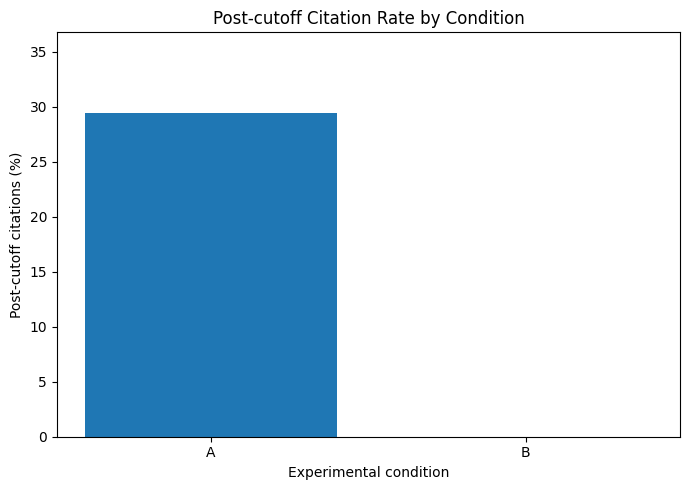

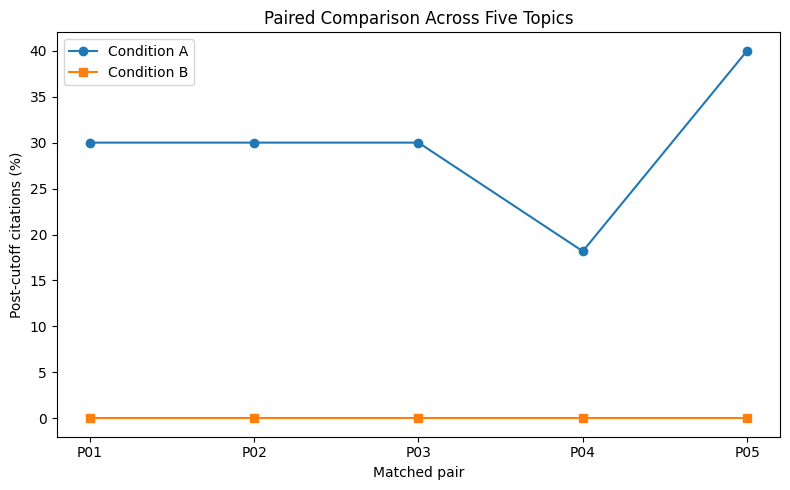

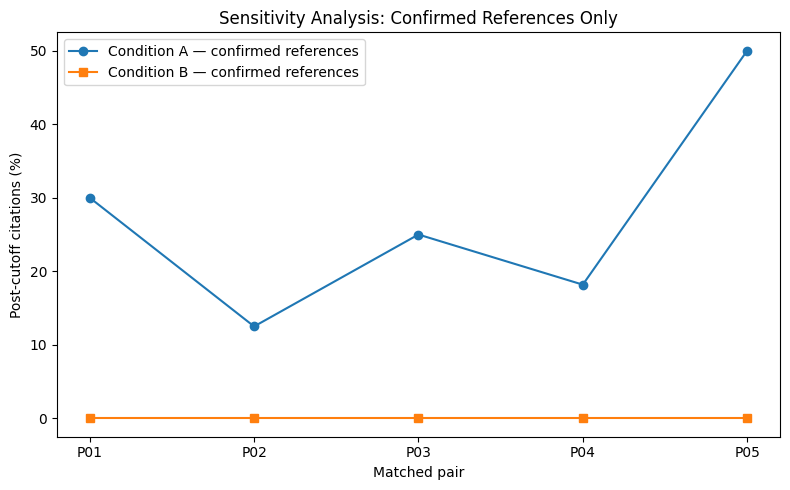

Three figures generated successfully.
Figures folder: /content/llm_cutoff_study/github_release/results
Updated GitHub ZIP: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip
Drive backup: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_figures


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
DATA = BASE / "data"
RESULTS = BASE / "github_release" / "results"

RESULTS.mkdir(parents=True, exist_ok=True)

# Load data
full = pd.read_csv(DATA / "final_consolidated_reference_audit.csv")
paired = pd.read_csv(DATA / "paired_condition_comparison.csv")
sensitivity = pd.read_csv(DATA / "sensitivity_analysis.csv")

# 1. Overall post-cutoff rates
overall = full.groupby("run_id").agg(
    post=("cutoff_status_final", lambda x: (x == "POST_CUTOFF").sum()),
    total=("run_id", "count")
).reset_index()

overall["condition"] = overall["run_id"].str.extract(r"_([AB])$")
condition_summary = overall.groupby("condition").agg(
    post=("post", "sum"),
    total=("total", "sum")
)
condition_summary["rate"] = (
    condition_summary["post"] / condition_summary["total"] * 100
)

plt.figure(figsize=(7, 5))
plt.bar(
    condition_summary.index,
    condition_summary["rate"]
)
plt.ylabel("Post-cutoff citations (%)")
plt.xlabel("Experimental condition")
plt.title("Post-cutoff Citation Rate by Condition")
plt.ylim(0, max(10, condition_summary["rate"].max() * 1.25))
plt.tight_layout()
plt.savefig(RESULTS / "figure1_overall_cutoff_rate.png", dpi=300)
plt.show()
plt.close()

# 2. Paired comparison
plt.figure(figsize=(8, 5))
x = range(len(paired))

plt.plot(
    x,
    paired["post_cutoff_rate_A"] * 100,
    marker="o",
    label="Condition A"
)
plt.plot(
    x,
    paired["post_cutoff_rate_B"] * 100,
    marker="s",
    label="Condition B"
)

plt.xticks(list(x), paired["pair_id"])
plt.ylabel("Post-cutoff citations (%)")
plt.xlabel("Matched pair")
plt.title("Paired Comparison Across Five Topics")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "figure2_paired_comparison.png", dpi=300)
plt.show()
plt.close()

# 3. Sensitivity analysis
plt.figure(figsize=(8, 5))
x = range(len(sensitivity))

plt.plot(
    x,
    sensitivity["rate_A"] * 100,
    marker="o",
    label="Condition A — confirmed references"
)
plt.plot(
    x,
    sensitivity["rate_B"] * 100,
    marker="s",
    label="Condition B — confirmed references"
)

plt.xticks(list(x), sensitivity["pair_id"])
plt.ylabel("Post-cutoff citations (%)")
plt.xlabel("Matched pair")
plt.title("Sensitivity Analysis: Confirmed References Only")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "figure3_sensitivity_analysis.png", dpi=300)
plt.show()
plt.close()

# Save a figure index
figure_index = """# Research Figures

1. figure1_overall_cutoff_rate.png — Overall post-cutoff citation rates.
2. figure2_paired_comparison.png — Condition A and B across five matched pairs.
3. figure3_sensitivity_analysis.png — Confirmed-reference sensitivity analysis.

All rates are descriptive. The study contains five matched pairs.
"""

(RESULTS / "FIGURE_INDEX.md").write_text(
    figure_index,
    encoding="utf-8"
)

# Rebuild GitHub ZIP
GITHUB = BASE / "github_release"
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(BASE))

# Backup figures to Google Drive
drive_backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_figures"
)
drive_backup.mkdir(parents=True, exist_ok=True)

for file in RESULTS.glob("figure*.png"):
    shutil.copy2(file, drive_backup / file.name)

print("Three figures generated successfully.")
print("Figures folder:", RESULTS)
print("Updated GitHub ZIP:", zip_path)
print("Drive backup:", drive_backup)

In [ ]:
from pathlib import Path

folders = {
    "Colab": Path("/content/llm_cutoff_study/github_release/results"),
    "Google Drive": Path(
        "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_figures"
    )
}

for name, folder in folders.items():
    print(f"\n{name}:")
    if folder.exists():
        for image in sorted(folder.glob("figure*.png")):
            print("✓", image.name, f"({image.stat().st_size / 1024:.1f} KB)")
    else:
        print("Folder not found")


Colab:
✓ figure1_overall_cutoff_rate.png (70.5 KB)
✓ figure2_paired_comparison.png (114.9 KB)
✓ figure3_sensitivity_analysis.png (149.7 KB)

Google Drive:
✓ figure1_overall_cutoff_rate.png (70.5 KB)
✓ figure2_paired_comparison.png (114.9 KB)
✓ figure3_sensitivity_analysis.png (149.7 KB)


In [ ]:
from pathlib import Path
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
GITHUB = BASE / "github_release"
DOCS = GITHUB / "docs"

DOCS.mkdir(parents=True, exist_ok=True)

methodology = r"""
# 3. Research Methodology

## 3.1 Research Design

This study employed a controlled comparative design to investigate
whether explicit publication-date boundary instructions influence
the temporal compliance of large language models when generating
literature reviews.

Two prompting conditions were compared. Condition A used a standard
literature-review prompt. Condition B used the same underlying prompt
with an additional instruction requiring the model to include only
scholarly works published on or before 31 December 2024, inclusive.
The instruction also required uncertain publication dates to be
omitted or flagged rather than guessed.

The experiment consisted of five matched prompt pairs, producing
ten literature reviews in total.

## 3.2 Experimental Conditions

### Condition A: Standard Prompt

The model received the standard literature-review prompt without
an explicit publication-date restriction.

### Condition B: Explicit Temporal Boundary

The model received the same underlying literature-review prompt,
preceded by an explicit instruction to respect the publication-date
boundary of 31 December 2024. The instruction specified that
unverified publication dates should not be guessed.

The comparison was designed to isolate the effect associated with
adding an explicit temporal boundary instruction.

## 3.3 Data Collection

Ten literature reviews were generated manually through the
ChatGPT user interface. The five matched pairs were identified
using pair IDs P01 through P05.

The generation order was randomized using seed 2026. The generated
reviews were saved as Word documents and subsequently converted
into text files for analysis.

The model selector label and visible generation settings were
recorded in the generation log.

The generated reviews were retained for analysis. Their observed
lengths exceeded the originally intended target of 800–1,000 words.
This deviation was documented rather than modifying the generated
outputs after collection.

## 3.4 Citation Extraction

References were extracted from the bibliography sections of the
generated literature reviews. The extraction process identified
candidate bibliography entries and assigned run IDs and reference
numbers to support traceability.

The initial extraction identified 100 candidate entries. One entry
was determined to be commentary rather than a complete bibliographic
reference. The final analysis therefore considered 99 reference
instances.

## 3.5 Bibliographic Verification

Candidate references were assessed using bibliographic metadata
services, including Crossref and OpenAlex, together with additional
record checks where appropriate.

Manual decisions were recorded using four categories:

- MATCH: the bibliographic record was identified and considered
  consistent with the cited reference.
- PARTIAL_MATCH: a record was identified, but one or more
  bibliographic details remained inconsistent or unresolved.
- DOI_MISMATCH: a discrepancy involving the cited DOI was identified.
- NOT_APPLICABLE: the entry was not a complete bibliographic reference.

A failed DOI lookup was not treated as sufficient evidence that
a reference was fabricated. Preprint and published versions were
also distinguished where relevant.

## 3.6 Temporal Classification

The temporal boundary was set to 31 December 2024, inclusive.

References were classified according to their candidate publication
year:

- WITHIN_CUTOFF: publication year on or before 2024.
- POST_CUTOFF: publication year after 2024.
- UNKNOWN_DATE: publication year could not be established.

Publication-year candidates and independently verified dates
were distinguished in the audit records. Where a preprint and a
later proceedings or journal version differed, the cited version
was relevant to the cutoff assessment.

## 3.7 Evaluation Measures

The primary outcome was the proportion of dated citation instances
published after the cutoff:

Post-cutoff rate = Post-cutoff citation instances /
                   All dated citation instances

The secondary outcome was bibliographic match rate:

Bibliographic match rate = MATCH instances /
                           All analyzed citation instances

A sensitivity analysis was also conducted using only references
classified as MATCH.

## 3.8 Paired Analysis

Results were compared within each of the five matched prompt pairs.
For each pair, the post-cutoff citation rate under Condition A
was compared with the corresponding rate under Condition B.

The mean paired reduction was calculated as the average of the
five pair-specific differences.

Given the small number of matched pairs, the analysis emphasized
descriptive comparisons and cautious interpretation rather than
strong claims of statistical generalizability.

## 3.9 Research Limitations

The experiment involved five matched pairs and ten generated
literature reviews. Consequently, the findings should not be
assumed to generalize to all language models, prompts, or subject
areas.

The study measured observable compliance with an explicit
publication-date instruction. It did not directly measure the
model's internal training-data cutoff or establish the exact
boundary of its internal knowledge.

Manual bibliographic assessment and publication-version
distinctions also introduce potential uncertainty. These
limitations were retained when interpreting the results.
"""

method_path = DOCS / "METHODOLOGY.md"
method_path.write_text(methodology, encoding="utf-8")

# Rebuild the GitHub release ZIP
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(BASE))

# Google Drive backup
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report"
)
backup.mkdir(parents=True, exist_ok=True)
shutil.copy2(method_path, backup / method_path.name)

print("Methodology document created.")
print("Saved:", method_path)
print("Drive backup:", backup)
print("Updated ZIP:", zip_path)

Methodology document created.
Saved: /content/llm_cutoff_study/github_release/docs/METHODOLOGY.md
Drive backup: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report
Updated ZIP: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip


In [ ]:
from pathlib import Path
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
GITHUB = BASE / "github_release"
RESULTS = GITHUB / "results"

RESULTS.mkdir(parents=True, exist_ok=True)

results_text = r"""
# 4. Results and Findings

## 4.1 Overview of the Dataset

The experiment generated ten literature reviews across five matched
prompt pairs. Citation extraction initially identified 100 candidate
bibliographic entries. One entry was classified as commentary rather
than a complete reference, leaving 99 citation instances for analysis.

The references were classified according to the publication-date
boundary of 31 December 2024, inclusive.

## 4.2 Overall Temporal Compliance

Condition A produced 15 post-cutoff citations among 51 citation
instances, corresponding to a post-cutoff rate of 29.41%.

Condition B produced no post-cutoff citations among 48 citation
instances. All 48 were classified as within the publication-date
boundary.

| Measure | Condition A | Condition B |
|---|---:|---:|
| Citation instances | 51 | 48 |
| Within cutoff | 36 | 48 |
| Post cutoff | 15 | 0 |
| Unknown year | 0 | 0 |
| Post-cutoff rate | 29.41% | 0.00% |

The observed difference in post-cutoff rates was 29.41 percentage
points in favour of Condition B.

![Overall post-cutoff citation rates](figure1_overall_cutoff_rate.png)

## 4.3 Bibliographic Verification

The manual bibliographic audit classified the 100 extracted
candidate entries as follows:

| Decision | Number |
|---|---:|
| MATCH | 93 |
| PARTIAL_MATCH | 5 |
| DOI_MISMATCH | 1 |
| NOT_APPLICABLE | 1 |
| Total | 100 |

Among the 99 actual reference instances, 93 were classified as MATCH.
The remaining six consisted of five partial matches and one DOI
mismatch.

Condition A had 45 MATCH entries among 51 citation instances,
giving a bibliographic match rate of 88.24%.

Condition B had 48 MATCH entries among 48 citation instances,
giving a bibliographic match rate of 100%.

These results describe the manual audit decisions and should not be
interpreted as proof that every bibliographic detail is error-free.

## 4.4 Matched-Pair Comparison

The five matched pairs were compared using their respective
post-cutoff citation rates.

| Pair | Condition A | Condition B | Reduction |
|---|---:|---:|---:|
| P01 | 30.00% | 0.00% | 30.00 pp |
| P02 | 30.00% | 0.00% | 30.00 pp |
| P03 | 30.00% | 0.00% | 30.00 pp |
| P04 | 18.18% | 0.00% | 18.18 pp |
| P05 | 40.00% | 0.00% | 40.00 pp |
| Mean | 29.64% | 0.00% | 29.64 pp |

Every matched pair showed a lower post-cutoff citation rate under
Condition B. The mean paired reduction was 29.64 percentage points.

![Paired comparison](figure2_paired_comparison.png)

## 4.5 Sensitivity Analysis

A sensitivity analysis was conducted using only references classified
as MATCH in the manual bibliographic audit.

This restricted analysis retained 45 confirmed references in
Condition A and 48 in Condition B.

| Measure | Condition A | Condition B |
|---|---:|---:|
| Confirmed references | 45 | 48 |
| Within cutoff | 33 | 48 |
| Post cutoff | 12 | 0 |
| Post-cutoff rate | 26.67% | 0.00% |

The mean paired reduction in post-cutoff rates was 27.14 percentage
points. All five matched pairs continued to show a lower rate under
Condition B.

![Sensitivity analysis](figure3_sensitivity_analysis.png)

The sensitivity analysis therefore supports the consistency of the
descriptive pattern when unresolved bibliographic cases are excluded.

## 4.6 Statistical Interpretation

All five matched pairs showed a reduction in post-cutoff citation
rates under Condition B.

A two-sided exact sign test based on the five pairwise directions
gives p = 0.0625. This does not meet the conventional 0.05
significance threshold.

The sample contains only five matched pairs. Accordingly, the
results are interpreted primarily as descriptive evidence rather
than conclusive statistical proof.

## 4.7 Summary of Findings

The principal findings are:

1. Condition A produced a post-cutoff citation rate of 29.41%.
2. Condition B produced a post-cutoff citation rate of 0%.
3. All five matched pairs favoured Condition B.
4. The mean paired reduction was 29.64 percentage points.
5. The confirmed-reference sensitivity analysis retained a
   reduction of 27.14 percentage points.
6. Condition B had a higher bibliographic match rate in this sample.

Overall, the results indicate that adding an explicit publication-date
boundary instruction was associated with improved observable temporal
compliance in the generated literature reviews.
"""

results_path = RESULTS / "RESULTS_AND_FINDINGS.md"
results_path.write_text(results_text, encoding="utf-8")

# Rebuild GitHub ZIP
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(BASE))

# Google Drive backup
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report"
)
backup.mkdir(parents=True, exist_ok=True)
shutil.copy2(results_path, backup / results_path.name)

print("Results section created successfully.")
print("Saved:", results_path)
print("Drive backup:", backup)
print("Updated ZIP:", zip_path)

Results section created successfully.
Saved: /content/llm_cutoff_study/github_release/results/RESULTS_AND_FINDINGS.md
Drive backup: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report
Updated ZIP: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip


In [ ]:
from pathlib import Path
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
GITHUB = BASE / "github_release"
DOCS = GITHUB / "docs"

DOCS.mkdir(parents=True, exist_ok=True)

discussion = r"""
# 5. Discussion

## 5.1 Interpretation of the Findings

The findings indicate that adding an explicit publication-date
boundary instruction was associated with improved temporal compliance
in the generated literature reviews.

Condition A produced 15 post-cutoff citation instances among 51
references, whereas Condition B produced none among 48 references.
The observed difference was 29.41 percentage points.

Importantly, this pattern was consistent across all five matched
pairs. The sensitivity analysis, which retained only references
classified as bibliographic matches, also showed a reduction.
Its mean paired reduction was 27.14 percentage points.

These results suggest that a clearly stated temporal constraint
can influence the publication dates of references selected or
generated during literature-review generation.

## 5.2 Implications for Literature Review Generation

The findings have practical implications for researchers using
large language models to support literature reviews.

A model may produce a plausible-looking bibliography without
necessarily respecting a researcher's intended temporal scope.
An explicit cutoff instruction may help reduce this problem.

However, a date instruction should not replace independent
bibliographic verification. Researchers should still check titles,
authors, publication venues, DOIs, and the distinction between
preprint and formally published versions.

A useful research workflow should therefore combine explicit
prompt constraints with external reference verification.

## 5.3 Bibliographic Reliability

Condition B also showed a higher bibliographic match rate in this
sample. However, this result should be interpreted cautiously.

The experiment was not designed with a sufficiently large sample
to establish that explicit temporal instructions generally improve
bibliographic accuracy. The observed difference may be influenced
by the small number of generated reviews, the topics selected,
and the unresolved partial-match cases.

Temporal compliance and bibliographic correctness should therefore
be treated as separate dimensions of citation reliability.

## 5.4 Relationship to Knowledge Boundaries

The experiment evaluates whether a model follows an explicitly
provided publication-date boundary. It does not directly reveal
the model's internal training-data cutoff or establish when the
model acquired particular information.

A model can cite a post-cutoff work because of information available
through its context, retrieval, updates, or other mechanisms.
Likewise, a model can omit a recent work even if it has information
about that work.

Consequently, the results concern observable temporal instruction
compliance rather than the model's internal knowledge boundary.

# 6. Limitations

## 6.1 Small Sample Size

The experiment included five matched pairs and ten literature
reviews. This limited sample restricts statistical power and
generalizability.

The descriptive consistency across pairs is encouraging, but
larger studies are needed to determine whether the observed
pattern holds across different models, domains, and prompts.

## 6.2 Single Model Interface

The reviews were generated manually through the ChatGPT interface.
The findings should not automatically be generalized to other
models, model versions, APIs, or generation settings.

## 6.3 Review Length Deviation

The generated reviews exceeded the originally intended target
of 800–1,000 words. This deviation was documented, and the
original outputs were retained rather than edited after generation.

Differences in review length may have influenced the number of
references produced.

## 6.4 Bibliographic Uncertainty

Although 93 entries were classified as MATCH, five were classified
as PARTIAL_MATCH and one as DOI_MISMATCH.

Automated metadata services may return incomplete records, and
preprint and publication versions can have different dates or
identifiers. These cases require careful interpretation.

## 6.5 Publication Date Versus Internal Knowledge

The experiment measured compliance with an explicit publication-date
constraint. It did not measure the model's internal knowledge
cutoff, training-data composition, or exact knowledge acquisition
dates.

## 6.6 Limited Statistical Generalizability

Only five paired comparisons were available. The two-sided exact
sign test yielded p = 0.0625, which does not meet the conventional
0.05 threshold.

The results should therefore be presented as preliminary,
descriptive evidence rather than definitive statistical proof.

# 7. Conclusion

This study investigated whether an explicit publication-date
boundary instruction influences the temporal compliance of
large language models when generating literature reviews.

Across five matched prompt pairs, the standard prompting condition
produced a post-cutoff citation rate of 29.41%, while the condition
containing an explicit publication-date boundary produced a rate
of 0%.

The mean paired reduction was 29.64 percentage points. A sensitivity
analysis restricted to bibliographically matched references
also showed a reduction, with a mean paired difference of
27.14 percentage points.

The findings suggest that explicitly stating a publication-date
boundary may be a useful practical measure for reducing
post-cutoff citations in generated literature reviews.

Nevertheless, temporal instruction compliance does not guarantee
bibliographic accuracy. Independent verification remains necessary,
particularly when references involve preprints, later proceedings,
or uncertain publication metadata.

Future research should examine larger samples, multiple language
models, different academic domains, and repeated generations under
controlled settings. Such work could provide stronger evidence
about the reliability of temporal constraints in AI-assisted
academic research.

Overall, this study provides preliminary evidence that explicit
temporal instructions can improve observable date-boundary
compliance, while highlighting the continuing need for
independent citation verification.
"""

path = DOCS / "DISCUSSION_LIMITATIONS_CONCLUSION.md"
path.write_text(discussion, encoding="utf-8")

# Back up to Google Drive
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report"
)
backup.mkdir(parents=True, exist_ok=True)
shutil.copy2(path, backup / path.name)

# Rebuild GitHub ZIP
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(BASE))

print("Discussion, limitations and conclusion saved.")
print("File:", path)
print("Google Drive backup:", backup)
print("Updated GitHub ZIP:", zip_path)

Discussion, limitations and conclusion saved.
File: /content/llm_cutoff_study/github_release/docs/DISCUSSION_LIMITATIONS_CONCLUSION.md
Google Drive backup: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report
Updated GitHub ZIP: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip


In [ ]:
from pathlib import Path
import zipfile
import shutil

BASE = Path("/content/llm_cutoff_study")
GITHUB = BASE / "github_release"

# Verify required report files
required = [
    GITHUB / "RESEARCH_REPORT.md",
    GITHUB / "docs" / "METHODOLOGY.md",
    GITHUB / "results" / "RESULTS_AND_FINDINGS.md",
    GITHUB / "docs" / "DISCUSSION_LIMITATIONS_CONCLUSION.md"
]

print("REPORT FILE CHECK")
for file in required:
    print(("✓ " if file.exists() else "MISSING: ") + str(file))

# Rebuild ZIP without copying files onto themselves
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(BASE))

# Back up main report to Drive
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report"
)
backup.mkdir(parents=True, exist_ok=True)

report_path = GITHUB / "RESEARCH_REPORT.md"
if report_path.exists():
    shutil.copy2(report_path, backup / report_path.name)

print("\nGitHub ZIP rebuilt successfully:", zip_path)
print("Google Drive backup updated:", backup)
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")

REPORT FILE CHECK
✓ /content/llm_cutoff_study/github_release/RESEARCH_REPORT.md
✓ /content/llm_cutoff_study/github_release/docs/METHODOLOGY.md
✓ /content/llm_cutoff_study/github_release/results/RESULTS_AND_FINDINGS.md
✓ /content/llm_cutoff_study/github_release/docs/DISCUSSION_LIMITATIONS_CONCLUSION.md

GitHub ZIP rebuilt successfully: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip
Google Drive backup updated: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report
ZIP size: 0.39 MB


In [ ]:
import pandas as pd
from pathlib import Path
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
DATA = BASE / "data"
GITHUB = BASE / "github_release"
DOCS = GITHUB / "docs"

df = pd.read_csv(DATA / "final_consolidated_reference_audit.csv")

# Exclude commentary and empty entries
refs = df[
    (df["manual_decision"] != "NOT_APPLICABLE") &
    (df["reference_text"].notna())
].copy()

# Preserve each citation instance and its source
refs = refs.sort_values(["run_id", "reference_number"])

lines = [
    "# Appendix A: Extracted Bibliographic References",
    "",
    "The following entries are reproduced from the generated reviews. ",
    "They are grouped by experimental run. Bibliographic verification ",
    "decisions are recorded separately in the citation audit dataset.",
    ""
]

for run_id, group in refs.groupby("run_id", sort=True):
    lines.extend([f"## {run_id}", ""])
    for _, row in group.iterrows():
        text = str(row["reference_text"]).strip()
        decision = row["manual_decision"]
        lines.append(
            f"{int(row['reference_number'])}. {text} "
            f"[Audit: {decision}]"
        )
        lines.append("")

appendix = DOCS / "APPENDIX_A_EXTRACTED_REFERENCES.md"
appendix.write_text("\n".join(lines), encoding="utf-8")

# Back up to Drive
backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report"
)
backup.mkdir(parents=True, exist_ok=True)
shutil.copy2(appendix, backup / appendix.name)

# Rebuild ZIP
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(BASE))

print("Bibliography appendix created.")
print("Reference instances included:", len(refs))
print("Saved:", appendix)
print("Updated ZIP:", zip_path)

Bibliography appendix created.
Reference instances included: 99
Saved: /content/llm_cutoff_study/github_release/docs/APPENDIX_A_EXTRACTED_REFERENCES.md
Updated ZIP: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip


In [ ]:
!pip -q install reportlab

In [ ]:
from pathlib import Path
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, PageBreak,
    Image, Table, TableStyle, KeepTogether
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4
from xml.sax.saxutils import escape
import re
import shutil
import zipfile

BASE = Path("/content/llm_cutoff_study")
GITHUB = BASE / "github_release"
DOCS = GITHUB / "docs"
RESULTS = GITHUB / "results"

pdf_path = BASE / "LLM_Cutoff_Temporal_Knowledge_Study.pdf"

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle", parent=styles["Title"],
    fontSize=21, leading=27, alignment=TA_CENTER, spaceAfter=20
))
styles.add(ParagraphStyle(
    name="SectionHeading", parent=styles["Heading1"],
    fontSize=15, leading=19, spaceBefore=14, spaceAfter=8
))
styles.add(ParagraphStyle(
    name="SubHeading", parent=styles["Heading2"],
    fontSize=11, leading=14, spaceBefore=9, spaceAfter=5
))
styles.add(ParagraphStyle(
    name="ReportBody", parent=styles["BodyText"],
    fontSize=9, leading=13, spaceAfter=7
))
styles.add(ParagraphStyle(
    name="SmallText", parent=styles["BodyText"],
    fontSize=7, leading=9
))

story = []

def add_markdown(path):
    if not path.exists():
        print("Missing section:", path)
        return

    text = path.read_text(encoding="utf-8")
    for raw in text.splitlines():
        line = raw.strip()

        if not line:
            story.append(Spacer(1, 4))
        elif line.startswith("# "):
            story.append(Paragraph(escape(line[2:]), styles["SectionHeading"]))
        elif line.startswith("## "):
            story.append(Paragraph(escape(line[3:]), styles["SubHeading"]))
        elif line.startswith("### "):
            story.append(Paragraph(escape(line[4:]), styles["Heading3"]))
        elif line.startswith("|"):
            # Tables are represented as readable text in this basic exporter.
            story.append(Paragraph(escape(line), styles["SmallText"]))
        elif line.startswith("!["):
            continue
        elif line.startswith("- ") or re.match(r"^\d+\.\s", line):
            story.append(Paragraph("• " + escape(line.lstrip("-0123456789. ")),
                                   styles["ReportBody"]))
        else:
            clean = re.sub(r"\*\*(.*?)\*\*", r"<b>\1</b>", escape(line))
            story.append(Paragraph(clean, styles["ReportBody"]))

# Title page
story.append(Spacer(1, 1.2 * inch))
story.append(Paragraph(
    "Knowledge Cutoffs, Temporal Knowledge Boundaries, "
    "and Citation Reliability in Large Language Models",
    styles["ReportTitle"]
))
story.append(Spacer(1, 0.3 * inch))
story.append(Paragraph(
    "A Controlled Comparative Study of Explicit Publication-Date Instructions",
    ParagraphStyle(
        "Subtitle", parent=styles["BodyText"],
        alignment=TA_CENTER, fontSize=12, leading=17
    )
))
story.append(Spacer(1, 1.0 * inch))
story.append(Paragraph(
    "Research Report",
    ParagraphStyle("Center", parent=styles["BodyText"],
                   alignment=TA_CENTER, fontSize=12)
))
story.append(PageBreak())

# Main report
add_markdown(GITHUB / "RESEARCH_REPORT.md")
add_markdown(DOCS / "METHODOLOGY.md")
add_markdown(RESULTS / "RESULTS_AND_FINDINGS.md")

# Embed figures
for filename, caption in [
    ("figure1_overall_cutoff_rate.png", "Figure 1. Overall post-cutoff citation rates"),
    ("figure2_paired_comparison.png", "Figure 2. Paired comparison across five topics"),
    ("figure3_sensitivity_analysis.png", "Figure 3. Sensitivity analysis using confirmed references")
]:
    image_path = RESULTS / filename
    if image_path.exists():
        story.append(Spacer(1, 10))
        story.append(Image(str(image_path), width=6.0*inch, height=3.7*inch))
        story.append(Paragraph(caption, styles["SmallText"]))

add_markdown(DOCS / "DISCUSSION_LIMITATIONS_CONCLUSION.md")
add_markdown(DOCS / "APPENDIX_A_EXTRACTED_REFERENCES.md")

def footer(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.drawString(0.7*inch, 0.45*inch,
                      "Knowledge Cutoffs and Citation Reliability Study")
    canvas.drawRightString(7.8*inch, 0.45*inch, f"Page {doc.page}")
    canvas.restoreState()

doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=0.65*inch,
    leftMargin=0.65*inch,
    topMargin=0.7*inch,
    bottomMargin=0.7*inch
)

doc.build(story, onFirstPage=footer, onLaterPages=footer)

# Save PDF in GitHub project
shutil.copy2(pdf_path, GITHUB / "LLM_Cutoff_Temporal_Knowledge_Study.pdf")

# Back up to Drive
drive_backup = Path(
    "/content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report"
)
drive_backup.mkdir(parents=True, exist_ok=True)
shutil.copy2(pdf_path, drive_backup / pdf_path.name)

# Rebuild final ZIP
zip_path = BASE / "LLM_Cutoff_Study_GitHub_Release.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for file in GITHUB.rglob("*"):
        if file.is_file():
            z.write(file, file.relative_to(BASE))

print("PDF created:", pdf_path)
print("PDF size:", round(pdf_path.stat().st_size / 1024, 1), "KB")
print("GitHub ZIP updated:", zip_path)
print("Google Drive backup:", drive_backup)

PDF created: /content/llm_cutoff_study/LLM_Cutoff_Temporal_Knowledge_Study.pdf
PDF size: 370.9 KB
GitHub ZIP updated: /content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip
Google Drive backup: /content/drive/MyDrive/LLM_Cutoff_Study_Backups/final_report


In [ ]:
from google.colab import files

files.download(
    "/content/llm_cutoff_study/LLM_Cutoff_Temporal_Knowledge_Study.pdf"
)

files.download(
    "/content/llm_cutoff_study/LLM_Cutoff_Study_GitHub_Release.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>